In [42]:
import pandas as pd
import numpy as np
import matplotlib as m
import matplotlib.pyplot as plt

In [43]:
# importing yeast count data

# 42 clean WT replicates
WT_yeast = pd.read_csv('WT_yeast.csv', index_col=0)

# 44 clean Snf2 mutant replciates
Snf2_yeast = pd.read_csv('Snf2_yeast.csv', index_col=0)

display(WT_yeast)
display(Snf2_yeast)

,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
0,15S_rRNA,2,12,31,8,21,11,2,3,7,...,0,49,9,4,11,12,1,22,12,4
1,21S_rRNA,20,76,101,99,128,74,36,32,57,...,10,274,49,30,72,58,21,159,107,70
2,HRA1,3,2,2,2,3,5,4,0,4,...,5,3,6,5,2,2,2,5,2,1
3,ICR1,75,123,107,157,98,245,119,120,119,...,85,177,137,118,113,81,142,94,187,106
4,LSR1,60,163,233,163,193,375,194,84,211,...,66,385,232,149,114,81,109,132,243,128
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7121,tY(GUA)J2,0,1,0,0,0,2,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7122,tY(GUA)M1,0,0,1,1,1,1,0,0,1,...,0,1,1,0,1,0,0,0,1,0
7123,tY(GUA)M2,0,0,1,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
7124,tY(GUA)O,0,0,0,0,0,0,1,0,0,...,0,0,1,0,0,0,0,0,0,1


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
0,15S_rRNA,4,2,5,5,46,5,4,2,40,...,7,15,6,1,85,8,34,3,6,3
1,21S_rRNA,31,18,23,44,356,35,33,13,148,...,64,79,67,13,576,52,234,23,44,24
2,HRA1,5,1,3,1,2,1,4,4,0,...,5,5,0,2,0,1,2,2,0,1
3,ICR1,205,196,211,252,127,275,160,190,146,...,286,155,184,164,202,186,148,183,195,145
4,LSR1,210,103,159,260,298,303,96,132,263,...,250,195,153,57,742,227,227,117,224,136
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7121,tY(GUA)J2,1,0,0,0,0,0,1,0,0,...,1,1,0,0,0,0,0,2,1,1
7122,tY(GUA)M1,0,0,1,0,2,0,0,0,0,...,1,1,1,0,0,0,0,0,0,1
7123,tY(GUA)M2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7124,tY(GUA)O,0,1,0,0,0,0,0,0,1,...,0,1,0,0,0,0,0,0,0,0


In [44]:
# importing yeast count data >>> q-values
# from explore_clean_yeast_consistency.ipynb

# 42 clean WT replicates
WT_yeast_q = pd.read_csv('WT_yeast_q.csv', index_col=0)

# 44 clean Snf2 mutant replciates
Snf2_yeast_q = pd.read_csv('Snf2_yeast_q.csv', index_col=0)

display(WT_yeast_q)
display(Snf2_yeast_q)

,13_q,8_q,38_q,27_q,5_q,16_q,14_q,33_q,6_q,19_q,...,15_q,1_q,30_q,40_q,21_q,4_q,24_q,31_q,39_q,17_q
0,1.651220e-06,4.065404e-07,1.603579e-06,5.808502e-07,2.745867e-06,5.386557e-06,1.353193e-06,1.349760e-07,8.207817e-07,2.573225e-06,...,5.250010e-07,5.030082e-07,3.455352e-06,4.120753e-06,2.093998e-06,8.628760e-07,1.042284e-06,1.816573e-07,1.727728e-07,3.619449e-06
1,4.513335e-06,3.353958e-06,7.277780e-06,4.065951e-06,1.610077e-05,3.986052e-05,7.910972e-06,1.484737e-06,5.129886e-06,9.649594e-06,...,2.756255e-06,3.521057e-06,1.307024e-05,2.866611e-05,1.439624e-05,9.587511e-06,5.732564e-06,2.724860e-06,1.900501e-06,1.670515e-05
2,3.302440e-07,1.016351e-07,3.700566e-07,9.293603e-07,4.992486e-07,1.795519e-07,5.204587e-07,8.098563e-07,4.103909e-07,4.288709e-07,...,1.312503e-07,6.706775e-07,4.506981e-07,1.074979e-06,6.543744e-07,2.876253e-07,2.084569e-07,4.541433e-07,2.591592e-07,9.744670e-07
3,1.398033e-05,1.229785e-05,1.011488e-05,1.556678e-05,1.235640e-05,1.274819e-05,1.634240e-05,1.160794e-05,1.682602e-05,1.275891e-05,...,1.509378e-05,1.274287e-05,1.442234e-05,1.702050e-05,1.518149e-05,1.514827e-05,1.396661e-05,1.017281e-05,1.235325e-05,1.809724e-05
4,2.201627e-05,8.638984e-06,1.011488e-05,3.090123e-05,2.421356e-05,5.655885e-05,1.374011e-05,9.043395e-06,2.571783e-05,1.254447e-05,...,1.312503e-05,1.022783e-05,3.365212e-05,2.382870e-05,2.970860e-05,1.572352e-05,2.105414e-05,9.173695e-06,9.502503e-06,2.881638e-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7121,1.100813e-07,1.016351e-07,1.233522e-07,1.161700e-07,1.248121e-07,1.795519e-07,1.040917e-07,1.349760e-07,2.051954e-07,1.072177e-07,...,1.312503e-07,1.676694e-07,1.502327e-07,1.791632e-07,1.308749e-07,9.587511e-08,1.042284e-07,9.082867e-08,8.638639e-08,1.392096e-07
7122,1.100813e-07,1.016351e-07,1.233522e-07,2.323401e-07,2.496243e-07,1.795519e-07,1.040917e-07,1.349760e-07,1.367970e-07,1.072177e-07,...,1.312503e-07,1.676694e-07,1.502327e-07,1.791632e-07,2.617497e-07,1.917502e-07,2.084569e-07,9.082867e-08,8.638639e-08,4.176287e-07
7123,1.100813e-07,1.016351e-07,1.233522e-07,2.323401e-07,1.248121e-07,1.795519e-07,1.040917e-07,1.349760e-07,6.839848e-08,1.072177e-07,...,1.312503e-07,1.676694e-07,1.502327e-07,1.791632e-07,1.308749e-07,9.587511e-08,1.042284e-07,9.082867e-08,8.638639e-08,1.392096e-07
7124,1.100813e-07,1.016351e-07,1.233522e-07,1.161700e-07,1.248121e-07,1.795519e-07,1.040917e-07,1.349760e-07,6.839848e-08,1.072177e-07,...,1.312503e-07,1.676694e-07,1.502327e-07,1.791632e-07,1.308749e-07,9.587511e-08,1.042284e-07,9.082867e-08,8.638639e-08,1.392096e-07


,11_q,23_q,5_q,27_q,43_q,33_q,13_q,24_q,31_q,28_q,...,40_q,7_q,21_q,32_q,26_q,15_q,10_q,22_q,19_q,2_q
0,6.755117e-07,9.171568e-07,6.827575e-06,4.152554e-06,7.991772e-07,1.127455e-06,9.497976e-07,1.205007e-06,8.953913e-07,7.889508e-07,...,1.014152e-06,6.136811e-07,1.215388e-06,4.463240e-07,9.023679e-07,5.007454e-06,8.074703e-07,7.894240e-06,2.203145e-06,3.450619e-07
1,3.242456e-06,7.642973e-06,5.186051e-05,2.366956e-05,5.137568e-06,3.883457e-06,4.748988e-06,7.832543e-06,5.148500e-06,6.048623e-06,...,5.972229e-06,4.173032e-06,5.401724e-06,3.459011e-06,7.863492e-06,3.848866e-05,6.560696e-06,3.114636e-05,9.337138e-06,2.185392e-06
2,4.053070e-07,1.019063e-07,4.358026e-07,2.768369e-07,1.141682e-07,2.505456e-07,2.374494e-07,6.025033e-07,3.357717e-07,6.574590e-07,...,2.253671e-07,6.136811e-07,1.350431e-07,3.347430e-07,2.578194e-07,2.945561e-07,4.037352e-07,4.305949e-07,6.294700e-07,2.300412e-07
3,2.202168e-05,2.201176e-05,1.859425e-05,1.716389e-05,2.237696e-05,1.828983e-05,1.733381e-05,1.491196e-05,1.712436e-05,1.354366e-05,...,2.107183e-05,1.976053e-05,2.133681e-05,1.305498e-05,2.797341e-05,2.002981e-05,1.937929e-05,1.901794e-05,1.982830e-05,2.265906e-05
4,2.418332e-05,1.569357e-05,4.343500e-05,3.681931e-05,2.568784e-05,2.117111e-05,7.242207e-06,1.551446e-05,2.126554e-05,1.078233e-05,...,2.569185e-05,1.190541e-05,2.376759e-05,9.707547e-06,1.740281e-05,4.320156e-05,1.594754e-05,3.695939e-05,2.706721e-05,1.196214e-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7121,1.351023e-07,1.019063e-07,1.452675e-07,1.384185e-07,2.283363e-07,1.252728e-07,1.187247e-07,1.506258e-07,1.119239e-07,1.314918e-07,...,1.126836e-07,2.454724e-07,1.350431e-07,1.115810e-07,2.578194e-07,9.818537e-08,1.009338e-07,7.176581e-08,1.049117e-07,1.150206e-07
7122,1.351023e-07,2.038126e-07,4.358026e-07,1.384185e-07,1.141682e-07,2.505456e-07,1.187247e-07,1.506258e-07,1.119239e-07,2.629836e-07,...,1.126836e-07,1.227362e-07,4.051293e-07,1.115810e-07,1.289097e-07,1.963707e-07,1.009338e-07,1.435316e-07,1.049117e-07,1.150206e-07
7123,2.702047e-07,1.019063e-07,1.452675e-07,1.384185e-07,1.141682e-07,1.252728e-07,1.187247e-07,1.506258e-07,1.119239e-07,1.314918e-07,...,1.126836e-07,1.227362e-07,1.350431e-07,1.115810e-07,1.289097e-07,1.963707e-07,1.009338e-07,7.176581e-08,2.098233e-07,1.150206e-07
7124,1.351023e-07,1.019063e-07,1.452675e-07,1.384185e-07,1.141682e-07,1.252728e-07,1.187247e-07,1.506258e-07,2.238478e-07,1.314918e-07,...,1.126836e-07,1.227362e-07,1.350431e-07,1.115810e-07,1.289097e-07,9.818537e-08,1.009338e-07,7.176581e-08,1.049117e-07,2.300412e-07


In [45]:
# importing yeast count data >>> average q-values
# from explore_clean_yeast_consistency.ipynb

# 42 clean WT replicates
WT_yeast_avq = pd.read_csv('WT_yeast_avq.csv', index_col=0)

# 44 clean Snf2 mutant replciates
Snf2_yeast_avq = pd.read_csv('Snf2_yeast_avq.csv', index_col=0)

display(WT_yeast_avq)
display(Snf2_yeast_avq)

,genes,1,2,3,4,5,6,7,8,9,...,32,33,34,35,36,37,38,39,40,41
0,15S_rRNA,5.030082e-07,1.082671e-06,2.266838e-06,1.757651e-06,1.936241e-06,1.611843e-06,1.414441e-06,1.262933e-06,1.211224e-06,...,1.904640e-06,1.853748e-06,1.946728e-06,1.911901e-06,1.879292e-06,1.874652e-06,1.864698e-06,1.802844e-06,1.838121e-06,1.808986e-06
1,21S_rRNA,3.521057e-06,7.001270e-06,9.757261e-06,9.667083e-06,1.097203e-05,9.352440e-06,8.599160e-06,7.869044e-06,7.712282e-06,...,1.143895e-05,1.116937e-05,1.165616e-05,1.143130e-05,1.125617e-05,1.124791e-05,1.114460e-05,1.082007e-05,1.111147e-05,1.103367e-05
2,HRA1,6.706775e-07,4.330683e-07,3.942327e-07,3.254910e-07,3.356151e-07,3.373626e-07,3.536103e-07,3.053245e-07,3.213451e-07,...,3.409082e-07,3.498319e-07,3.457776e-07,3.543033e-07,3.621552e-07,3.608785e-07,3.579971e-07,3.515545e-07,3.605317e-07,3.538079e-07
3,ICR1,1.274287e-05,1.436343e-05,1.507940e-05,1.507023e-05,1.448308e-05,1.510635e-05,1.486771e-05,1.450291e-05,1.438637e-05,...,1.402170e-05,1.395360e-05,1.399016e-05,1.398161e-05,1.403270e-05,1.409661e-05,1.399302e-05,1.393298e-05,1.398095e-05,1.403248e-05
4,LSR1,1.022783e-05,1.616788e-05,2.252055e-05,2.018044e-05,2.098885e-05,2.226593e-05,2.221316e-05,2.034571e-05,2.072676e-05,...,2.320770e-05,2.282563e-05,2.321551e-05,2.321690e-05,2.314857e-05,2.302277e-05,2.269390e-05,2.223207e-05,2.225545e-05,2.218147e-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7121,tY(GUA)J2,1.676694e-07,1.443561e-07,9.855819e-08,6.509820e-08,5.163308e-08,7.496946e-08,6.429279e-08,5.551354e-08,4.943770e-08,...,1.852762e-08,1.803257e-08,1.728888e-08,1.671242e-08,1.631330e-08,1.596807e-08,1.556509e-08,1.502370e-08,1.477589e-08,1.426645e-08
7122,tY(GUA)M1,1.676694e-07,7.217804e-08,9.855819e-08,9.764730e-08,1.032662e-07,9.371182e-08,8.036599e-08,6.939192e-08,7.415655e-08,...,4.817182e-08,4.688468e-08,4.840887e-08,5.013727e-08,4.893989e-08,5.109783e-08,4.980829e-08,4.807583e-08,4.728285e-08,4.850592e-08
7123,tY(GUA)M2,1.676694e-07,7.217804e-08,9.855819e-08,6.509820e-08,5.163308e-08,3.748473e-08,4.821959e-08,4.163515e-08,3.707828e-08,...,1.482210e-08,1.442606e-08,1.383111e-08,1.336994e-08,1.305064e-08,1.277446e-08,1.245207e-08,1.201896e-08,1.182071e-08,1.141316e-08
7124,tY(GUA)O,1.676694e-07,7.217804e-08,4.927909e-08,3.254910e-08,2.581654e-08,1.874236e-08,3.214639e-08,2.775677e-08,2.471885e-08,...,1.111657e-08,1.081954e-08,1.037333e-08,1.336994e-08,1.305064e-08,1.277446e-08,1.245207e-08,1.201896e-08,1.182071e-08,1.141316e-08


,genes,1,2,3,4,5,6,7,8,9,...,34,35,36,37,38,39,40,41,42,43
0,15S_rRNA,4.888009e-07,3.699162e-07,4.332702e-07,4.431870e-07,1.392500e-06,1.178058e-06,1.093068e-06,9.750276e-07,1.354988e-06,...,2.247482e-06,2.162239e-06,2.153404e-06,2.107489e-06,2.068077e-06,2.252873e-06,2.219721e-06,2.264491e-06,2.219710e-06,2.184992e-06
1,21S_rRNA,3.128326e-06,2.642259e-06,2.635727e-06,3.050169e-06,1.045480e-05,8.800790e-06,8.213191e-06,7.299531e-06,8.343876e-06,...,1.195357e-05,1.158432e-05,1.153281e-05,1.139055e-05,1.119966e-05,1.252824e-05,1.236465e-05,1.273472e-05,1.249908e-05,1.232996e-05
2,HRA1,5.865611e-07,3.699162e-07,3.610585e-07,2.867680e-07,2.873412e-07,2.425414e-07,2.732670e-07,2.898731e-07,2.614890e-07,...,2.475201e-07,2.514231e-07,2.603689e-07,2.526609e-07,2.534122e-07,2.465408e-07,2.432571e-07,2.434937e-07,2.431111e-07,2.376114e-07
3,ICR1,2.013860e-05,2.124376e-05,2.213289e-05,2.255039e-05,2.192635e-05,2.195000e-05,2.166400e-05,2.130567e-05,2.095478e-05,...,1.977850e-05,1.973357e-05,1.970839e-05,1.967188e-05,1.975450e-05,1.979128e-05,1.981993e-05,1.979874e-05,1.982148e-05,1.987671e-05
4,LSR1,2.062740e-05,1.659338e-05,1.707807e-05,1.910918e-05,2.278837e-05,2.311074e-05,2.170954e-05,2.058099e-05,2.169170e-05,...,2.351111e-05,2.317493e-05,2.318508e-05,2.295350e-05,2.265855e-05,2.414683e-05,2.418197e-05,2.428173e-05,2.402572e-05,2.406074e-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7121,tY(GUA)J2,1.955204e-07,1.056903e-07,7.221170e-08,5.213964e-08,4.420634e-08,3.464878e-08,4.554450e-08,3.952815e-08,3.565759e-08,...,1.320107e-08,1.571395e-08,1.837898e-08,1.783489e-08,1.747671e-08,1.700282e-08,1.658571e-08,1.623291e-08,2.114009e-08,2.324459e-08
7122,tY(GUA)M1,9.776019e-08,5.284517e-08,7.221170e-08,5.213964e-08,8.841268e-08,6.929756e-08,6.072600e-08,5.270420e-08,4.754345e-08,...,4.950401e-08,5.028463e-08,5.207378e-08,5.350466e-08,5.243012e-08,5.100845e-08,4.975714e-08,4.869873e-08,4.756521e-08,4.648918e-08
7123,tY(GUA)M2,9.776019e-08,5.284517e-08,3.610585e-08,2.606982e-08,2.210317e-08,1.732439e-08,1.518150e-08,1.317605e-08,1.188586e-08,...,1.650134e-08,1.571395e-08,1.531582e-08,1.486241e-08,1.456392e-08,1.416901e-08,1.382143e-08,1.352743e-08,1.321256e-08,1.291366e-08
7124,tY(GUA)O,9.776019e-08,1.056903e-07,7.221170e-08,5.213964e-08,4.420634e-08,3.464878e-08,3.036300e-08,2.635210e-08,3.565759e-08,...,1.980160e-08,1.885673e-08,2.144214e-08,2.080737e-08,2.038949e-08,1.983662e-08,1.935000e-08,1.893840e-08,1.849758e-08,1.807913e-08


In [46]:
# importing results from differential gene expression anaylsis
RALL_bayexpress = pd.read_csv('RALL_bayexpress.csv', index_col=0)

display(RALL_bayexpress)

,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
0,15S_rRNA,-3.710645,0.274047,-107.138056,False,53.627445,True
1,21S_rRNA,-1.302642,0.147177,362.115507,True,1052.203968,True
2,HRA1,-5.206545,-0.564787,-240.338654,False,-258.581365,False
3,ICR1,76.746125,0.504048,-194.077441,False,-196.467262,False
4,LSR1,0.451012,0.120243,251.787125,True,478.066414,True
...,...,...,...,...,...,...,...
7121,tY(GUA)J2,-7.312143,0.861839,-270.299503,False,-281.214963,False
7122,tY(GUA)M1,-7.406574,0.022303,-262.736078,False,-275.253246,False
7123,tY(GUA)M2,-7.727890,0.183767,-271.177492,False,-284.863866,False
7124,tY(GUA)O,-7.622253,0.347266,-270.291196,False,-282.682788,False


In [47]:
# importing bootstrapping results
# via package_comp_numbers.ipynb

bayexpress_BF_21Ntrue = pd.read_csv('bayexpress_BF_21Ntrue.csv').set_index('locus_name')
display(bayexpress_BF_21Ntrue)

bayexpress_Ntrue = pd.read_csv('bayexpress_Ntrue.csv').set_index('locus_name')
display(bayexpress_Ntrue)

edgeR_Ntrue = pd.read_csv('edgeR_Ntrue.csv').set_index('genes')
display(edgeR_Ntrue)

DESeq2_Ntrue = pd.read_csv('DESeq2_Ntrue.csv').set_index('genes')
display(DESeq2_Ntrue)

,#3R,#6R,#12R,#20R
locus_name,,,,
15S_rRNA,30,25,24,21
21S_rRNA,67,53,63,54
HRA1,0,0,0,0
ICR1,45,91,99,100
LSR1,51,46,39,41
...,...,...,...,...
tY(GUA)J2,0,0,0,0
tY(GUA)M1,0,0,0,0
tY(GUA)M2,0,0,0,0


,#3R,#6R,#12R,#20R
locus_name,,,,
15S_rRNA,30,24,15,5
21S_rRNA,54,27,8,2
HRA1,0,0,0,0
ICR1,0,0,0,0
LSR1,18,2,0,0
...,...,...,...,...
tY(GUA)J2,0,0,0,0
tY(GUA)M1,0,0,0,0
tY(GUA)M2,0,0,0,0


,#R3,#R6,#R12,#R20
genes,,,,
15S_rRNA,0,0,0,0
21S_rRNA,0,1,0,0
HRA1,0,0,0,0
ICR1,0,0,0,0
LSR1,0,0,0,0
...,...,...,...,...
tY(GUA)J2,0,0,0,0
tY(GUA)M1,0,0,0,0
tY(GUA)M2,0,0,0,0


,#R3,#R6,#R12,#R20
genes,,,,
15S_rRNA,23,20,15,7
21S_rRNA,25,21,12,10
HRA1,0,17,26,28
ICR1,0,0,0,0
LSR1,3,6,0,0
...,...,...,...,...
tY(GUA)J2,0,0,0,0
tY(GUA)M1,0,0,0,0
tY(GUA)M2,0,0,0,0


In [57]:
# define function to get plots showing the package comparison numbers
# all the info from explore_clean_yeast.ipynb
# plus consistency tests
# PCN plots, 100 bootstrapping iterations

# Set global font size to 12
plt.rcParams.update({'font.size': 12})


def stalk(genes):

    # Find the index of all genes
    igenes = [list(RALL_bayexpress.locus_name).index(gene) for gene in genes]
    
    # Some more numbers about the genes

    print('Read counts in WT across replicates:')
    display(WT_yeast.iloc[igenes])

    print('Read counts in Snf2 mutant across replicates:')
    display(Snf2_yeast.iloc[igenes])

    print('bayexpress results:')
    display(RALL_bayexpress.iloc[igenes])

    print('With:')
    print('BF_21 ... Bayes factor for differential gene expression analysis')
    print('FC ... inferred log_2 fold change')
    print('BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type')
    print('CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.')
    print('BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant')
    print('CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.')
    print('(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1')

    # printing q-plots
    for t in igenes:
        fig, ax = plt.subplots(dpi=300)

        ax.hist(WT_yeast_q.iloc[t], 10, density=False, histtype='step', color='#5D3A9B',
                alpha=0.4, orientation='horizontal')

        ax.hist(Snf2_yeast_q.iloc[t], 10, density=False, histtype='step', color='#E66100',
                alpha=0.4, orientation='horizontal')


        # scatter WT
        gene_WT_BF_k1 = str(RALL_bayexpress.loc[t].BF_k1_WT.round(3))
        gene_ATOP_WT = RALL_bayexpress.loc[t].CIG_WT
        ax.scatter(np.arange(1,len(WT_yeast_q.columns)+1), WT_yeast_q.iloc[t],
                
            c='#5D3A9B', s=30, 
            label=f'BF_k1 = {gene_WT_BF_k1}{"*" if gene_ATOP_WT else ""}',
            alpha=0.95, edgecolors='none')
        
        # scatter Snf2
        gene_Snf2_BF_k1 = str(RALL_bayexpress.loc[t].BF_k1_Snf2.round(3))
        gene_ATOP_Snf2 = RALL_bayexpress.loc[t].CIG_Snf2
        ax.scatter(np.arange(1,len(Snf2_yeast_q.columns)+1), Snf2_yeast_q.iloc[t],
                
            c='#E66100', s=30, 
            label=f'BF_k1 = {gene_Snf2_BF_k1}{"*" if gene_ATOP_Snf2 else ""}',
            alpha=0.95, edgecolors='none')
        
        ax.legend(loc='upper right')
        
        # average estimates WT
        series = WT_yeast_avq.iloc[t,1:]
        series.plot(color='#5D3A9B', alpha=0.3, linewidth=10)
        
        # average estimates Snf2
        series = Snf2_yeast_avq.iloc[t,1:]
        series.plot(color='#E66100', alpha=0.3, linewidth=10)
            
        gene = str(RALL_bayexpress.loc[t].locus_name)
        gene_BF_21 = str(RALL_bayexpress.loc[t].BF_21.round(3))
        gene_iFC = str(RALL_bayexpress.loc[t].FC.round(3))
        ax.set_title(f'{gene}: BF_21 = {gene_BF_21}, iFC = {gene_iFC}')

        # Use tex in labels
        ax.set_xticks(np.arange(1,44))
        ax.set_xticklabels('')

        # formatting y axis ticks
        plt.gca().ticklabel_format(axis='y', style='plain', useOffset=False)

        ax.set_xlabel('Replicates')
        ax.set_ylabel('q = (n+1) / (N+2)')

        plt.show()

        # package number comparison plots
        reps = ['3/3 R', '6/6 R', '12/12 R', '20/20 R']

        fig, (ax1, ax2, ax3, ax4) = plt.subplots(1,4, dpi=300, figsize=(8,3))

        # Bayes factors

        im = ax1.imshow(bayexpress_Ntrue.loc[genes].values, cmap='Greens', alpha=0.3, norm=m.colors.Normalize(vmin=0, vmax=100))

        ax1.set_xticks(np.arange(len(reps)), labels=reps)
        ax1.set_yticks([], labels=[])

        # Rotate the tick labels and set their alignment.
        plt.setp(ax1.get_xticklabels(), rotation=45, ha="right",
                rotation_mode="anchor")

        # Loop over data dimensions and create text annotations.
        for i in range(len(genes)):
            for j in range(len(reps)):
                text = ax1.text(j, i, bayexpress_Ntrue.loc[genes].values[i, j],
                            ha="center", va="center", color="black")
        ax1.set_title('(1)')

        # edgeR

        im = ax2.imshow(edgeR_Ntrue.loc[genes].values, cmap='Greens', alpha=0.3, norm=m.colors.Normalize(vmin=0, vmax=100))

        ax2.set_xticks(np.arange(len(reps)), labels=reps)
        ax2.set_yticks([], labels=[])

        # Rotate the tick labels and set their alignment.
        plt.setp(ax2.get_xticklabels(), rotation=45, ha="right",
                rotation_mode="anchor")

        # Loop over data dimensions and create text annotations.
        for i in range(len(genes)):
            for j in range(len(reps)):
                text = ax2.text(j, i, edgeR_Ntrue.loc[genes].values[i, j],
                            ha="center", va="center", color="black")
        ax2.set_title('(2)')



        # DESeq2

        im = ax3.imshow(DESeq2_Ntrue.loc[genes].values, cmap='Greens', alpha=0.3, norm=m.colors.Normalize(vmin=0, vmax=100))

        ax3.set_xticks(np.arange(len(reps)), labels=reps)
        ax3.set_yticks([], labels=[])

        # Rotate the tick labels and set their alignment.
        plt.setp(ax3.get_xticklabels(), rotation=45, ha="right",
                rotation_mode="anchor")

        # Loop over data dimensions and create text annotations.
        for i in range(len(genes)):
            for j in range(len(reps)):
                text = ax3.text(j, i, DESeq2_Ntrue.loc[genes].values[i, j],
                            ha="center", va="center", color="black")
        ax3.set_title('(3)')


        # Bayes factors only

        im = ax4.imshow(bayexpress_BF_21Ntrue.loc[genes].values, cmap='Greens', alpha=0.3, norm=m.colors.Normalize(vmin=0, vmax=100))

        ax4.set_xticks(np.arange(len(reps)), labels=reps)
        ax4.set_yticks([], labels=[])

        # Rotate the tick labels and set their alignment.
        plt.setp(ax4.get_xticklabels(), rotation=45, ha="right",
                rotation_mode="anchor")

        # Loop over data dimensions and create text annotations.
        for i in range(len(genes)):
            for j in range(len(reps)):
                text = ax4.text(j, i, bayexpress_BF_21Ntrue.loc[genes].values[i, j],
                            ha="center", va="center", color="black")
        ax4.set_title('(4)')
        plt.show()

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
76,YAL016C-B,21,33,43,54,15,72,31,23,23,...,29,70,40,32,42,26,37,24,45,33


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
76,YAL016C-B,85,61,88,96,72,169,64,61,84,...,133,38,72,51,84,83,51,98,104,70


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
76,YAL016C-B,126.045252,1.06013,-197.181254,False,-173.052282,False


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


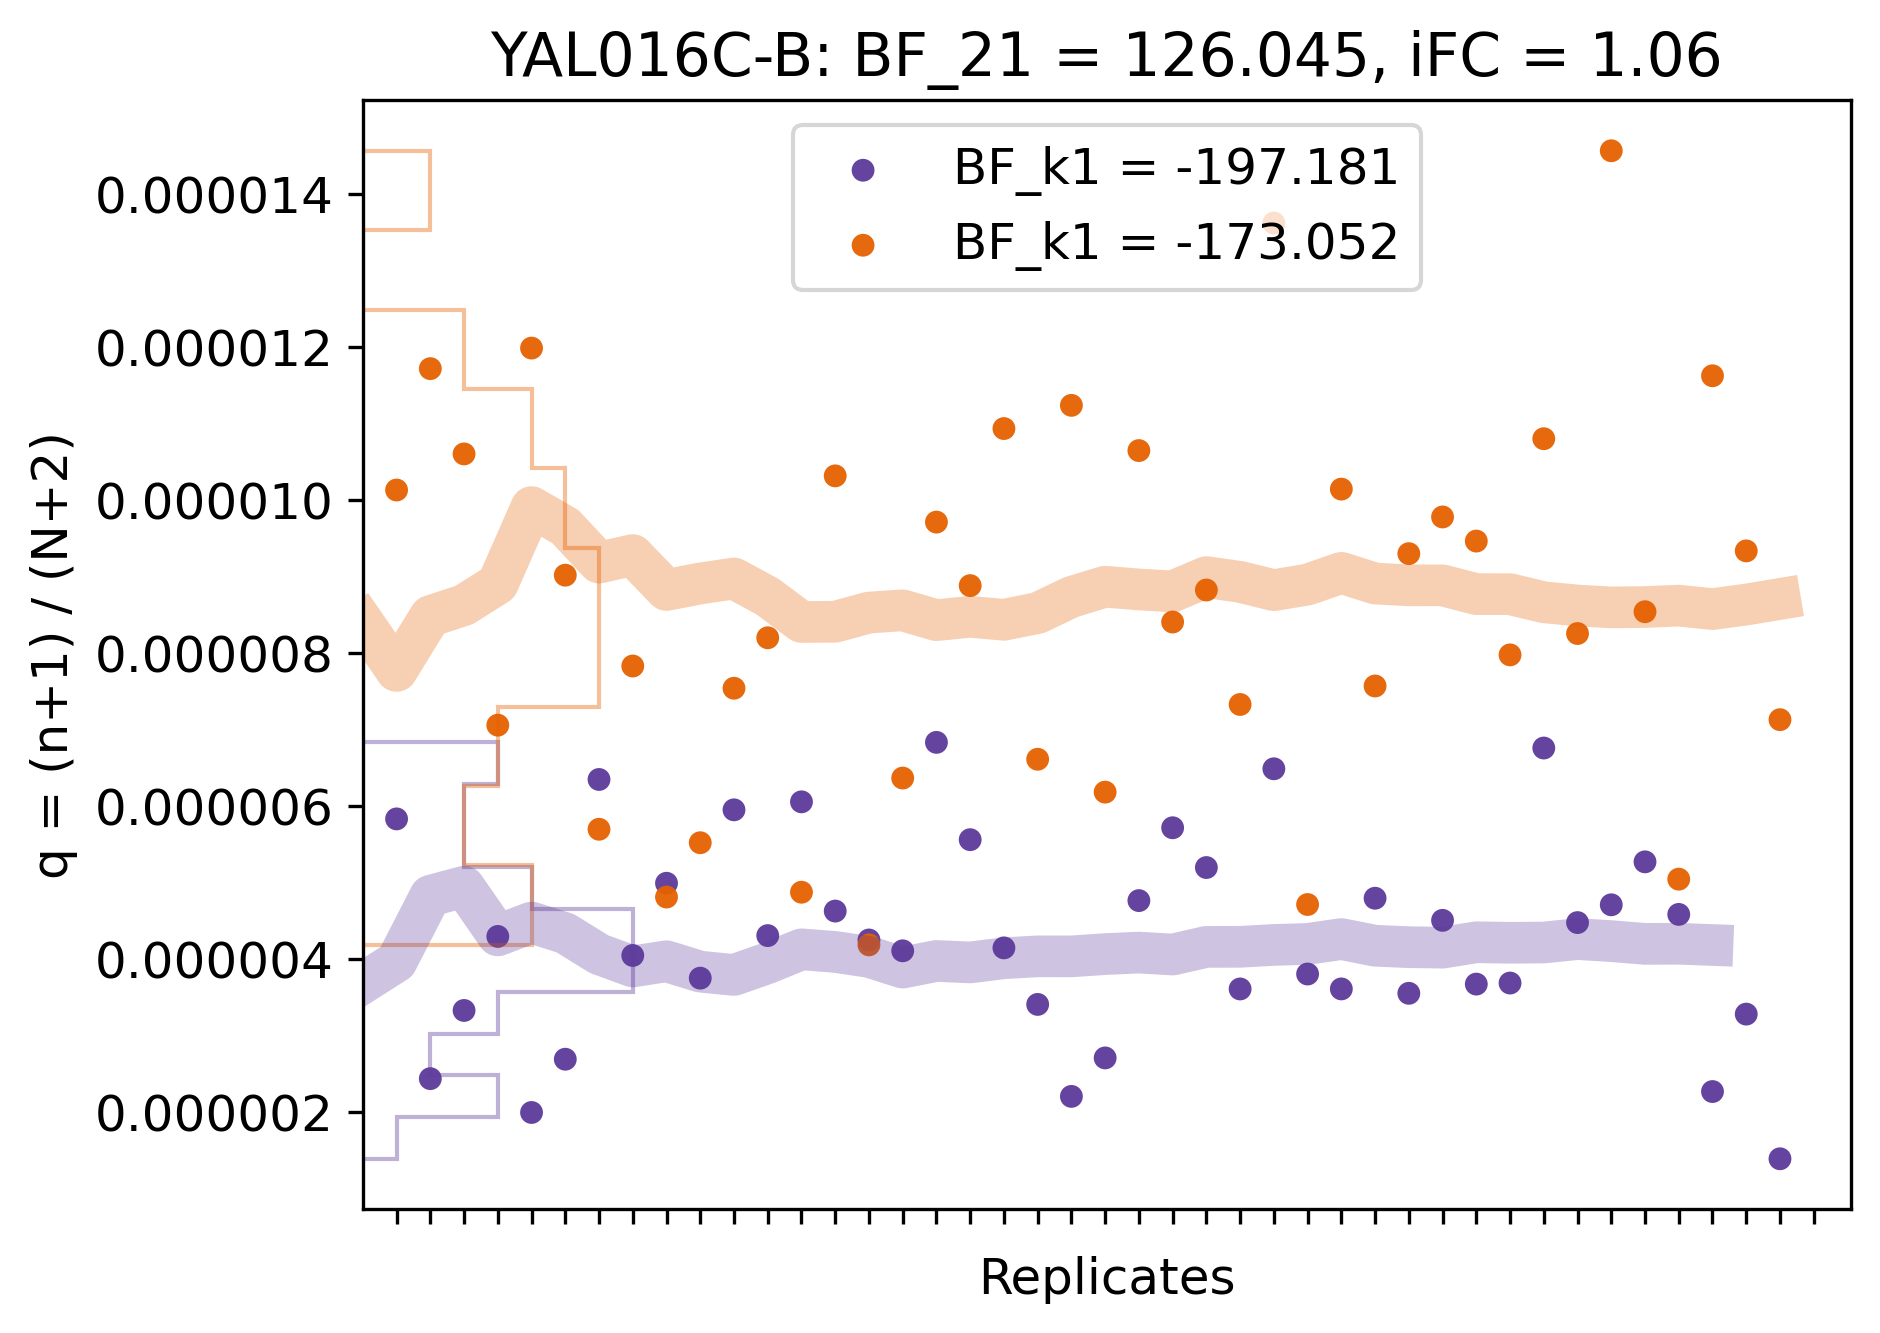

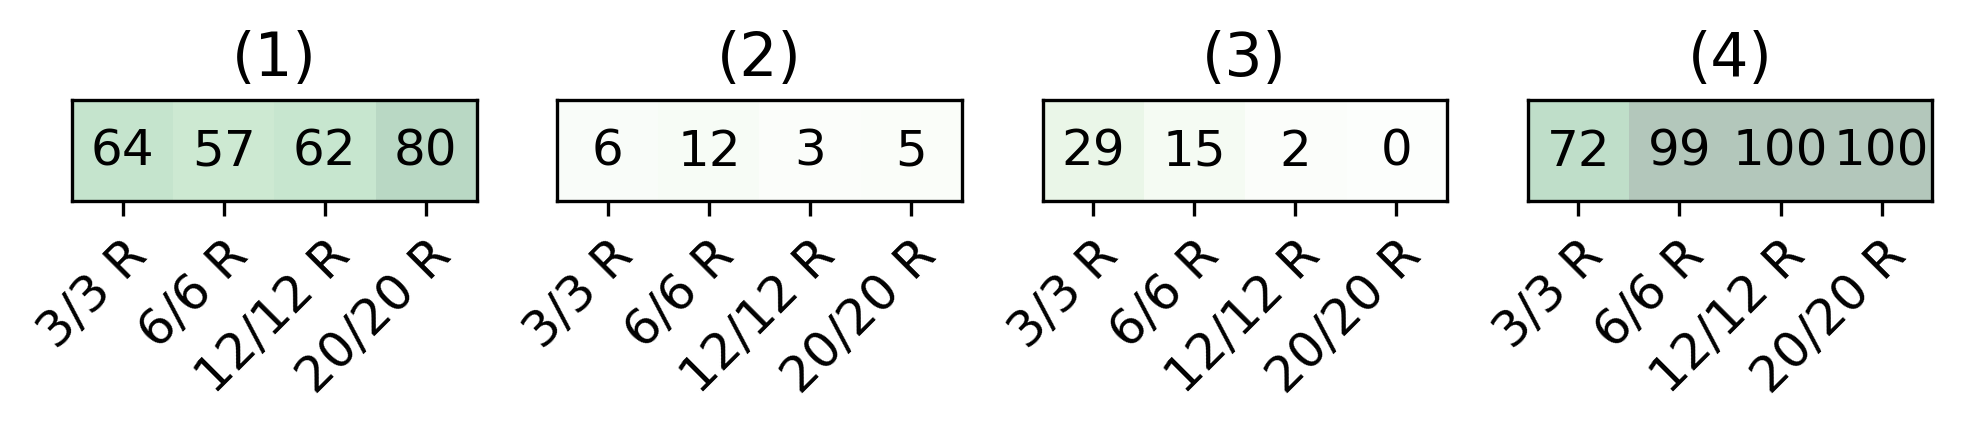

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
95,YAL031W-A,5,7,10,7,3,19,7,3,1,...,3,10,6,6,7,2,5,5,6,11


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
95,YAL031W-A,27,13,12,15,10,38,13,6,6,...,22,9,15,16,11,24,18,14,27,17


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
95,YAL031W-A,29.16,1.276184,-227.526482,False,-220.195081,False


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


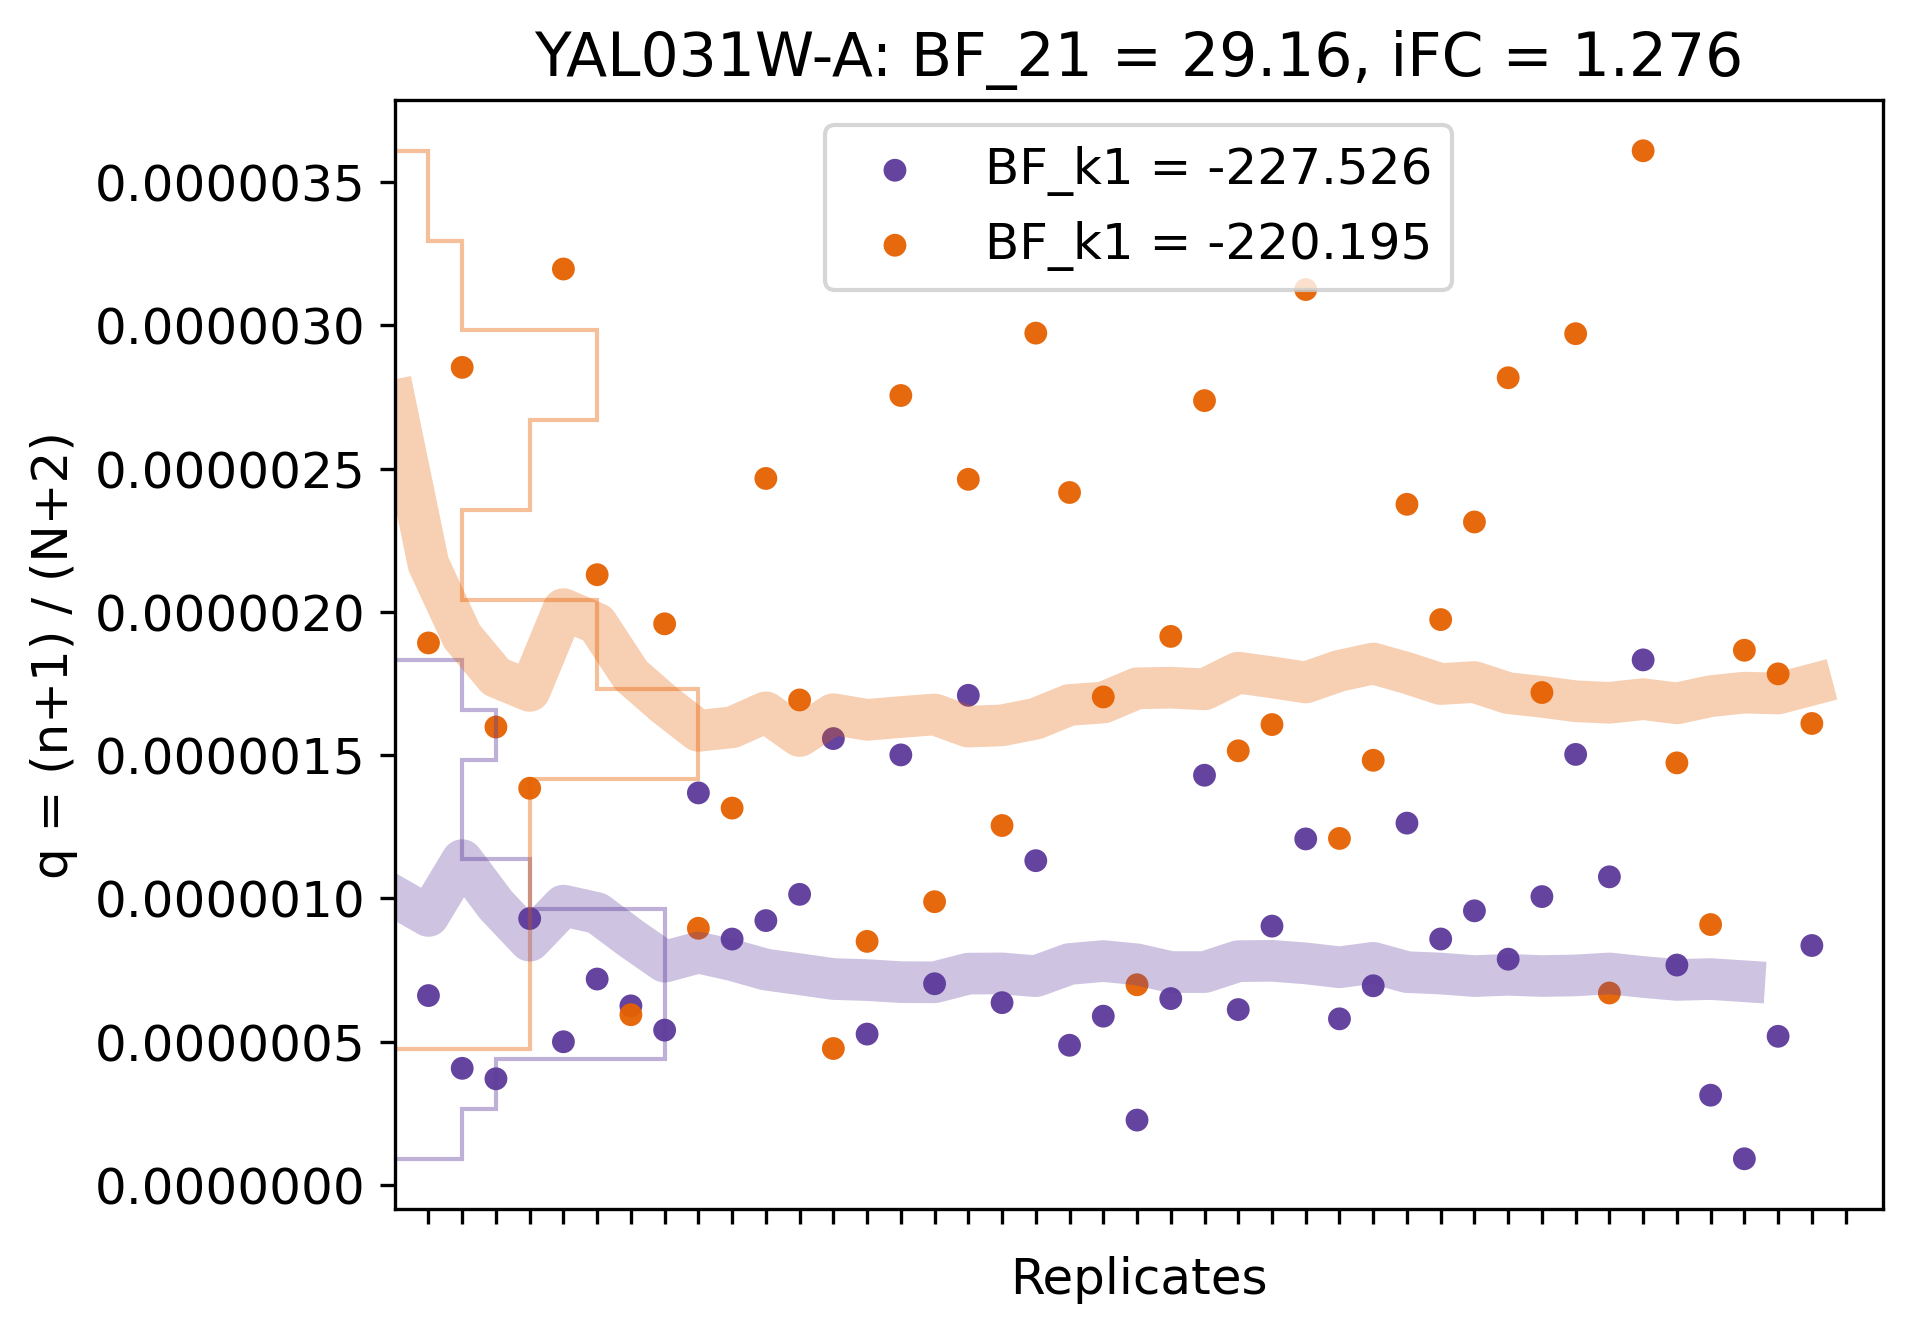

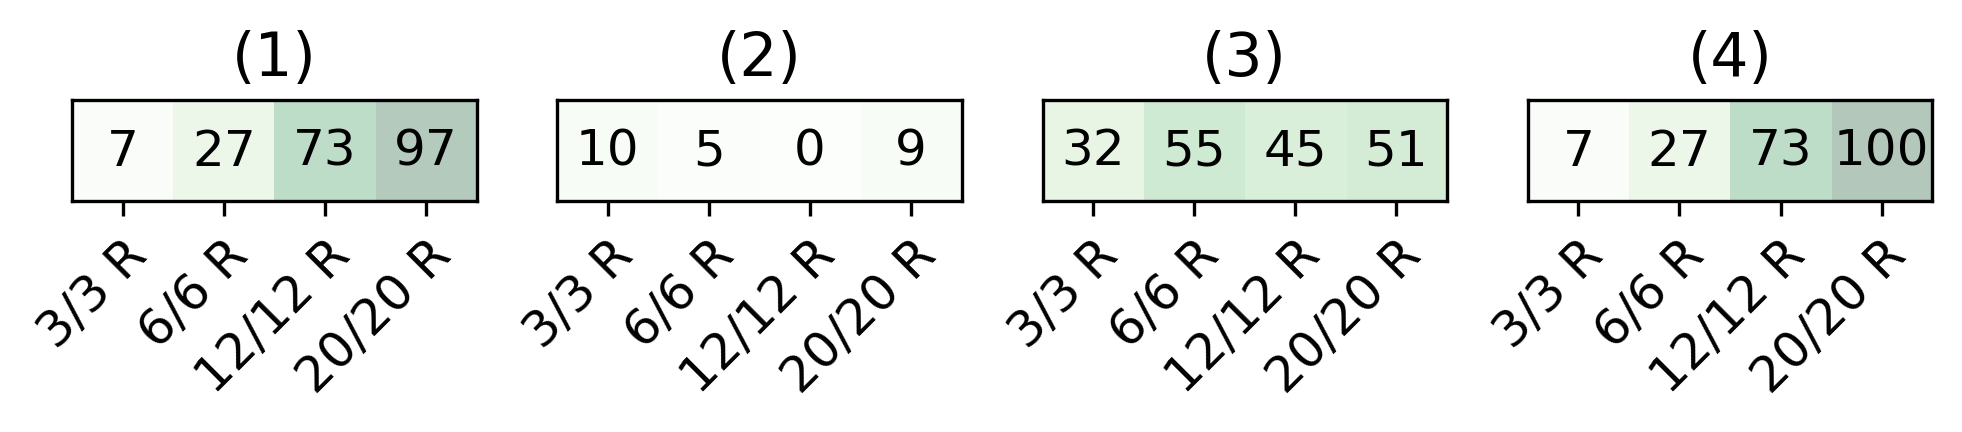

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
166,YAR035W,193,132,144,221,146,242,156,395,203,...,137,284,173,172,114,270,253,144,262,214


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
166,YAR035W,584,475,478,575,339,648,562,396,417,...,879,453,827,348,480,427,390,410,429,311


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
166,YAR035W,1011.933095,1.227418,-88.9385,False,-87.148361,False


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


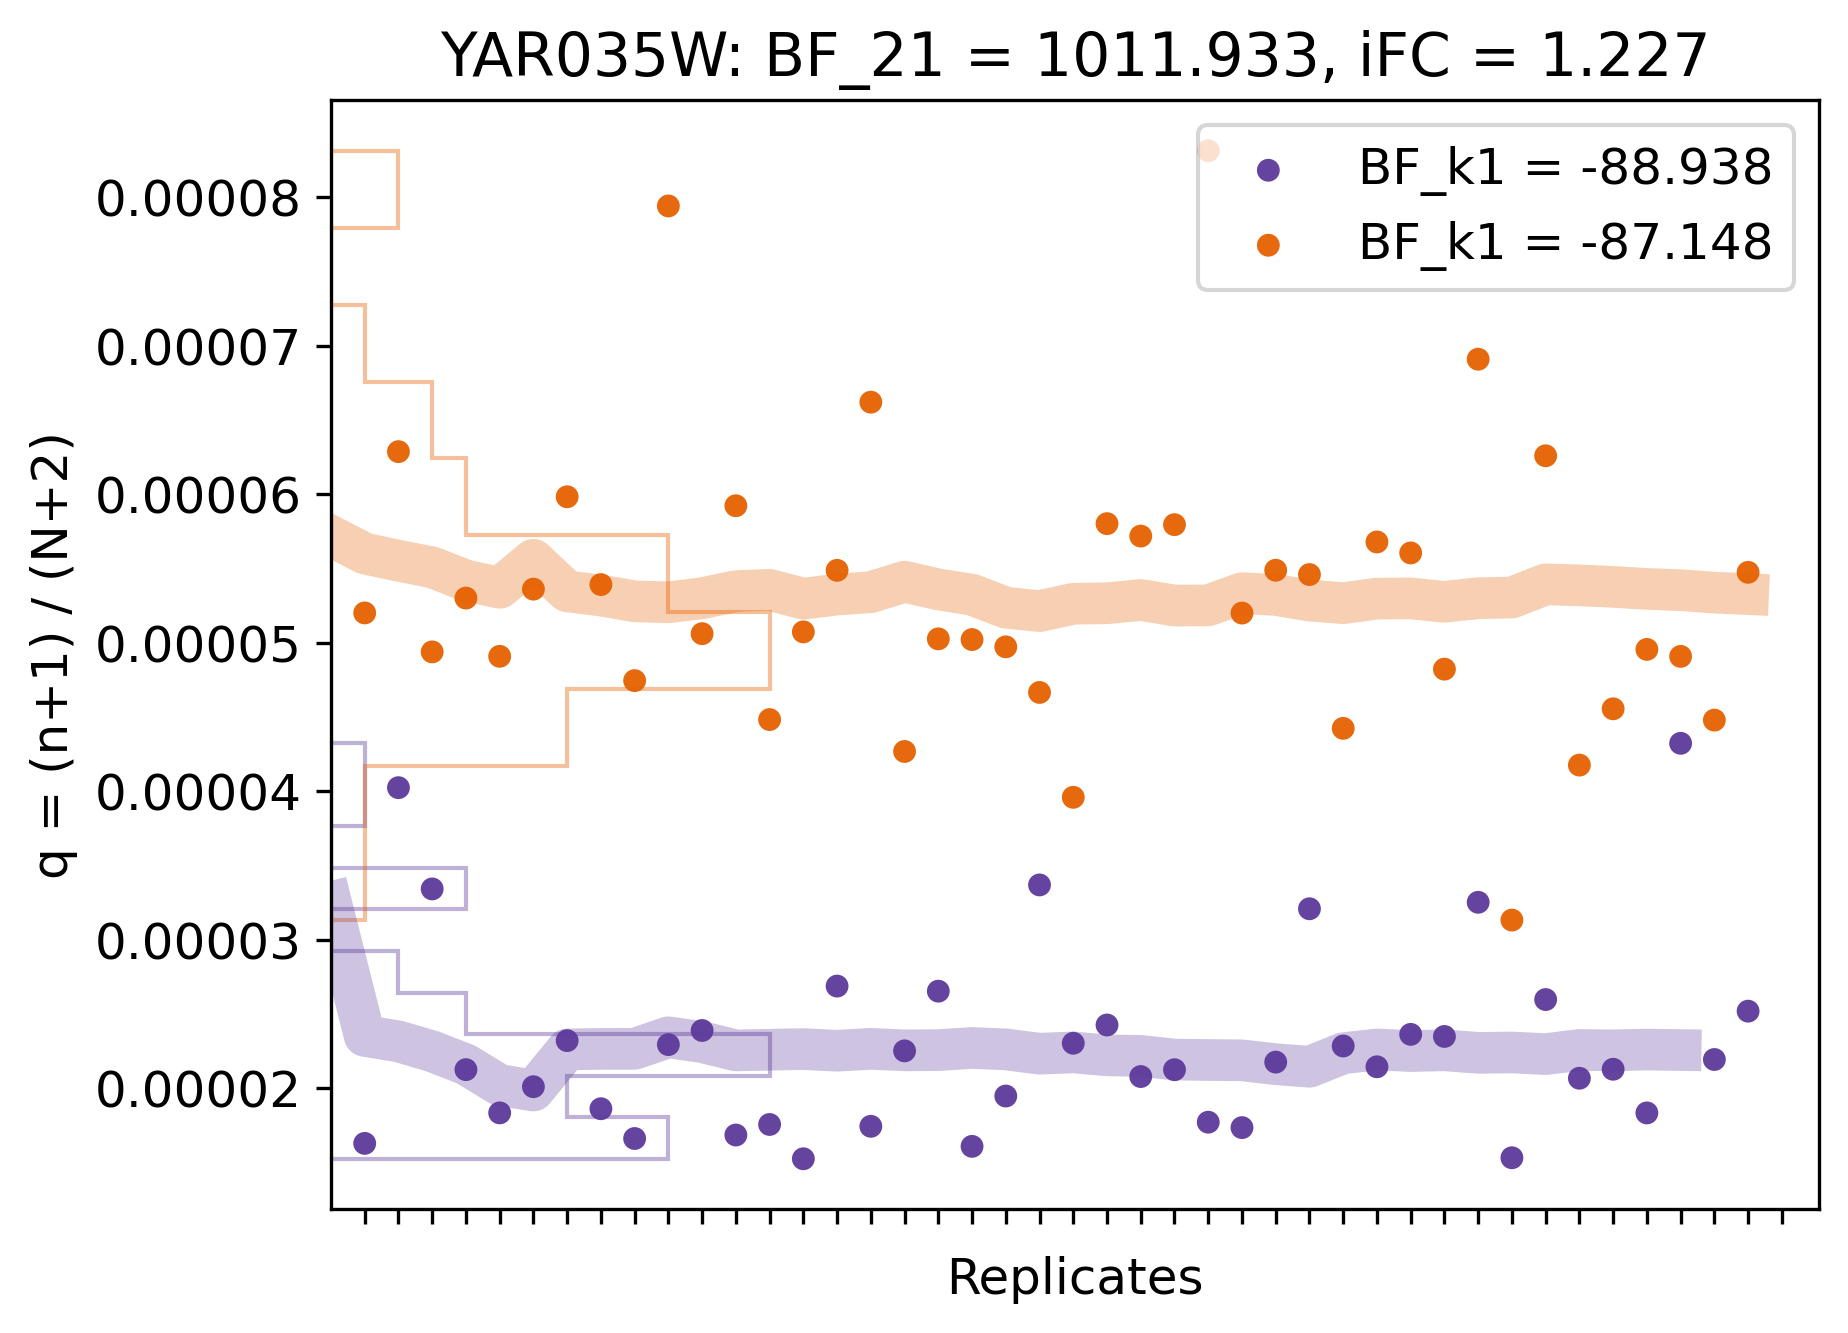

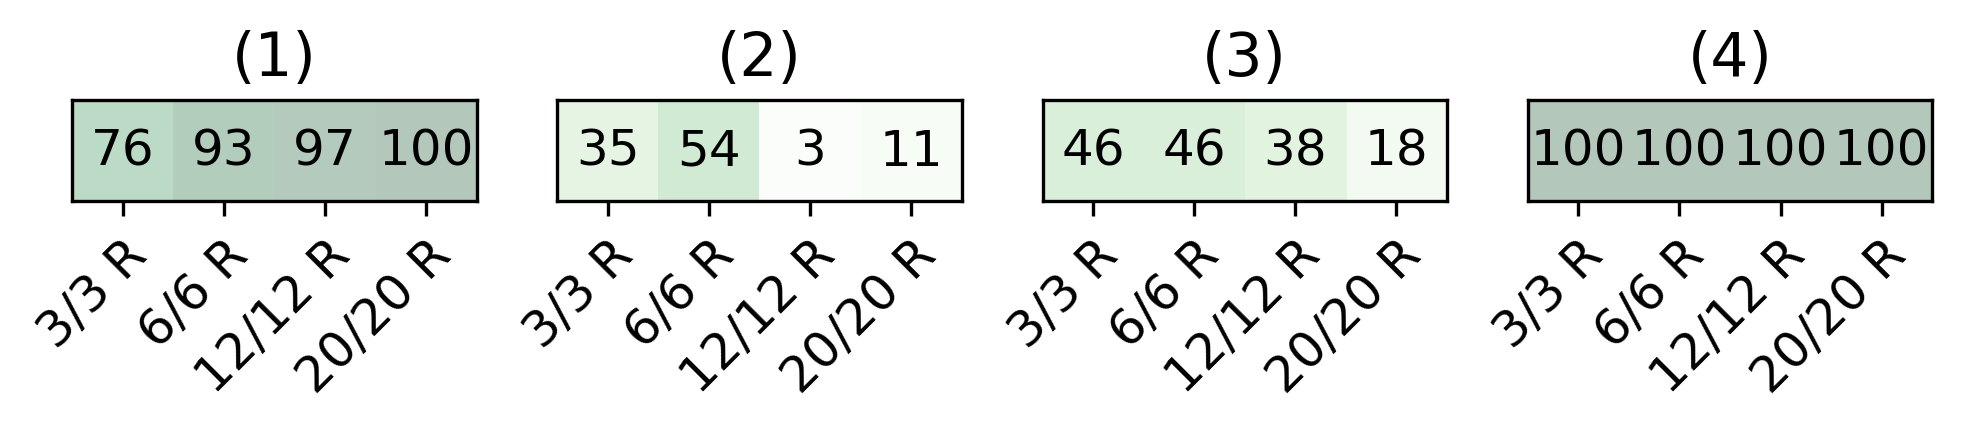

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
176,YAR068W,119,91,90,136,99,190,122,237,117,...,122,147,124,74,82,184,216,58,203,105


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
176,YAR068W,318,291,257,322,266,426,296,325,148,...,528,266,354,254,356,281,268,251,250,231


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
176,YAR068W,552.837207,1.145139,-171.270934,False,-139.829908,False


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


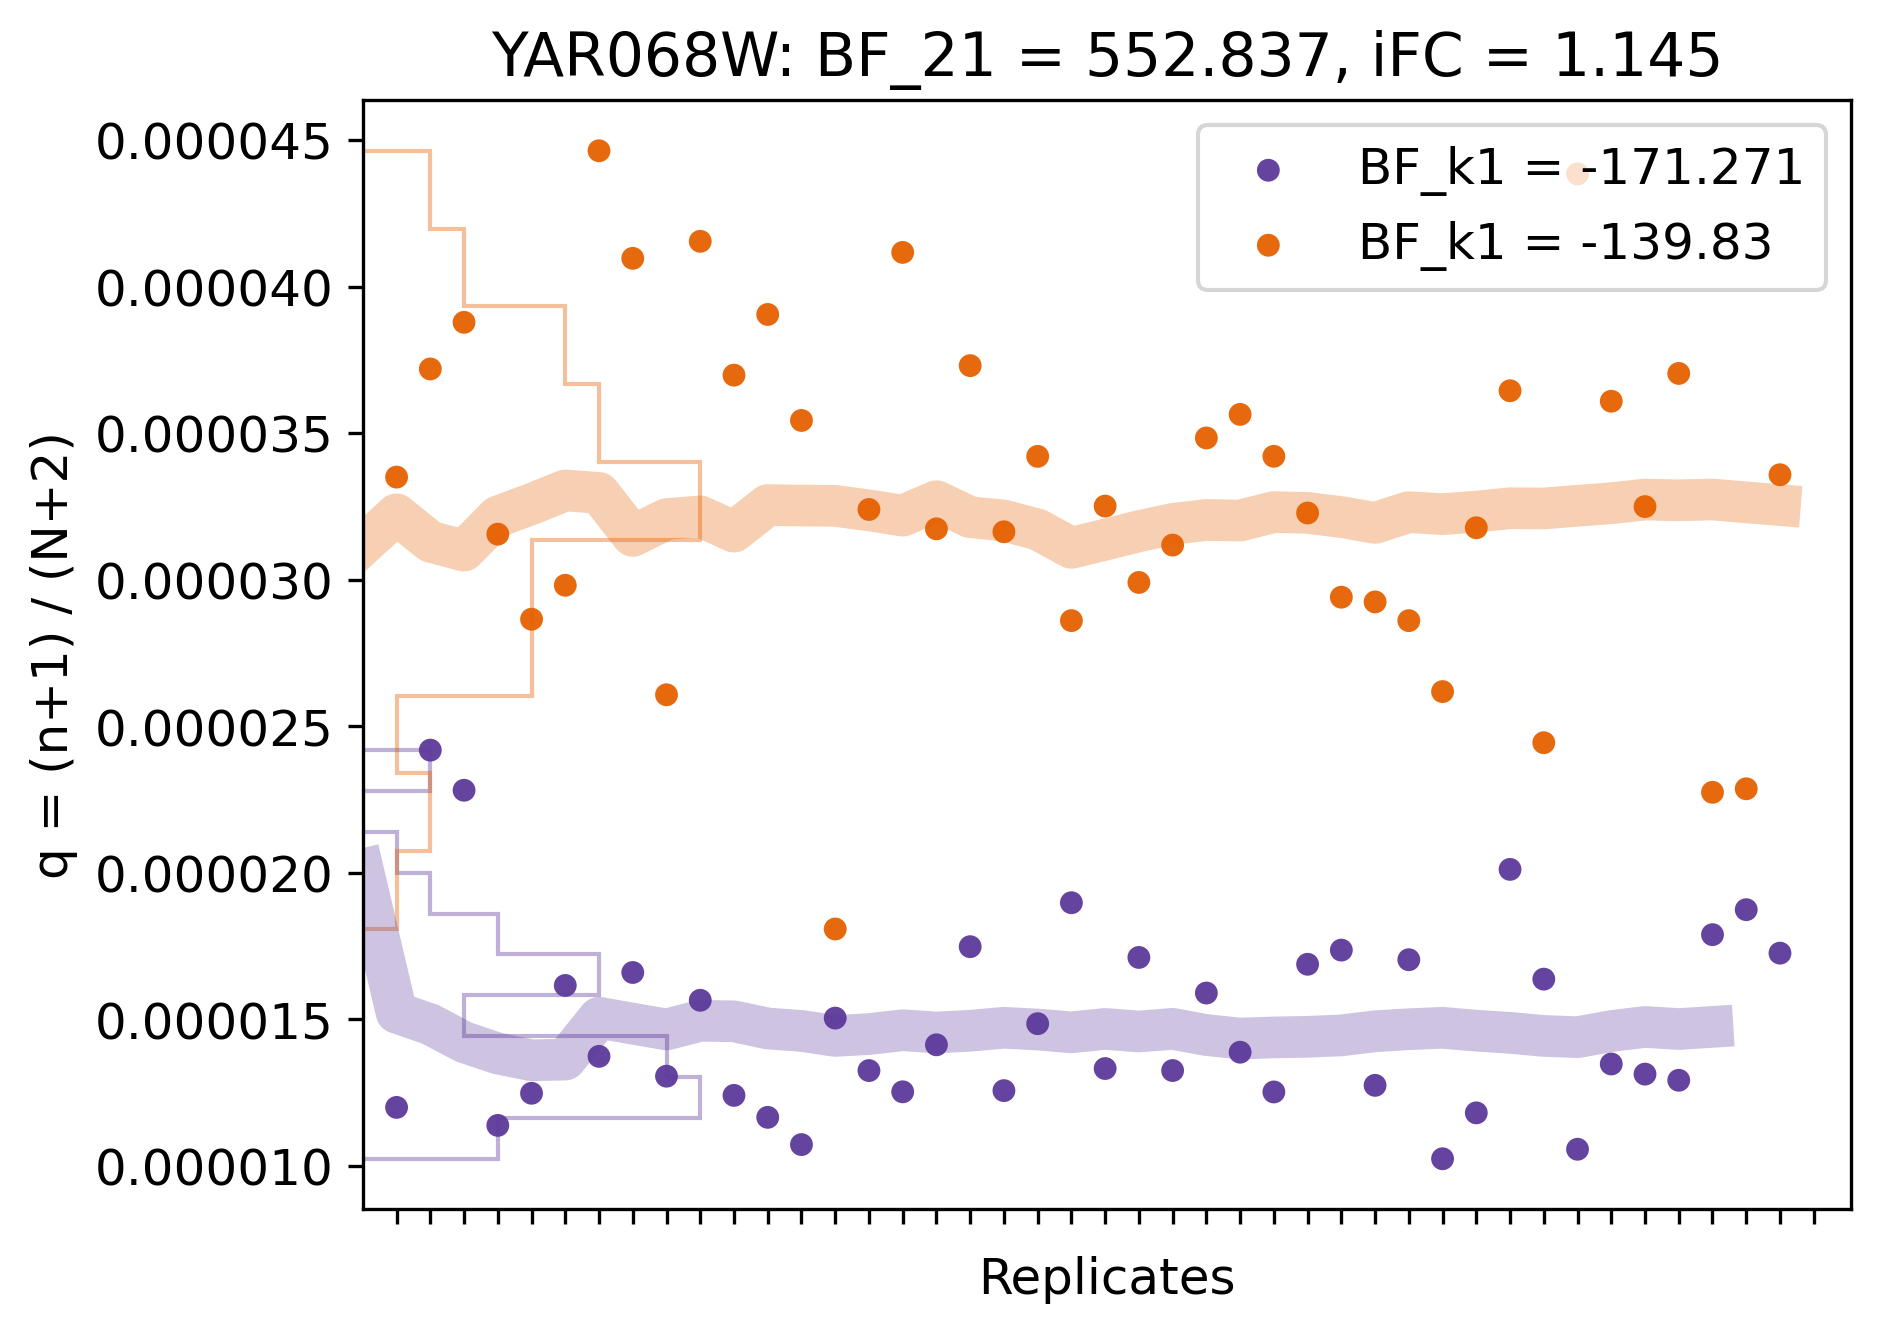

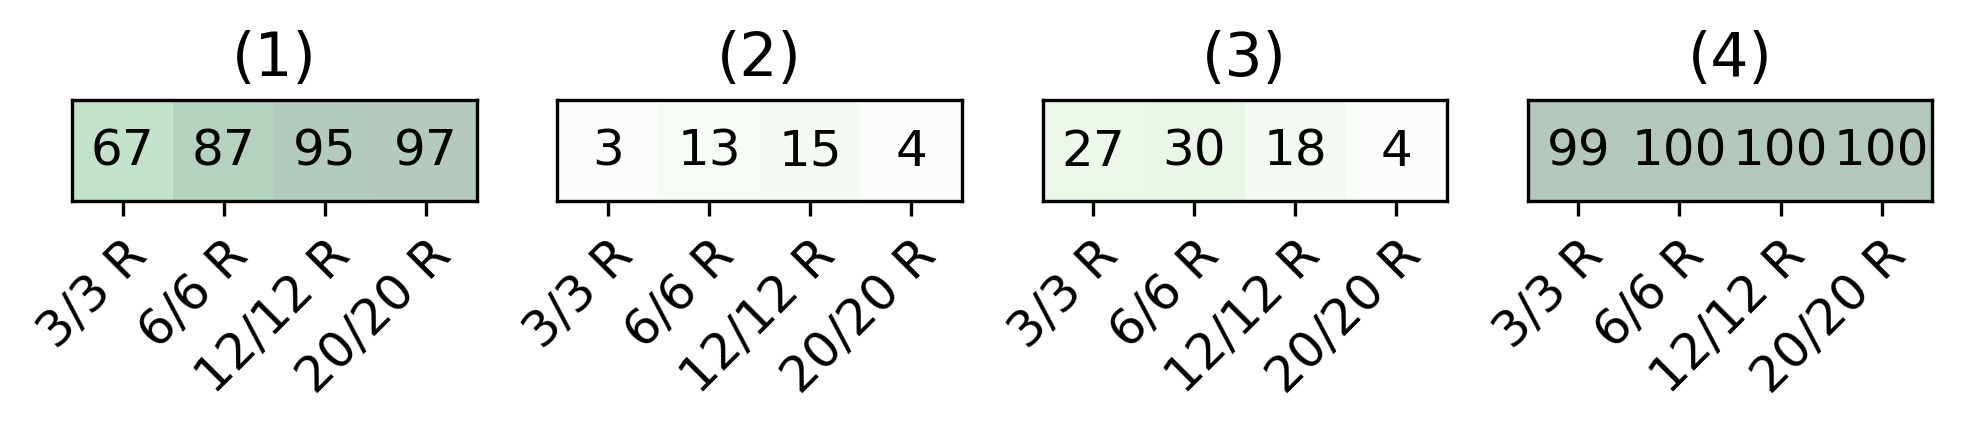

[None, None, None, None]

In [58]:
[stalk([gene]) for gene in ['YAL016C-B', 'YAL031W-A', 'YAR035W', 'YAR068W']]

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
2392,YGL228W,1122,1471,1195,1892,1497,2856,1679,1894,1642,...,1496,2312,1893,1413,1288,1655,2270,995,2302,1517


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
2392,YGL228W,2639,2223,2312,2872,1667,3109,1968,2406,2213,...,4188,2223,2641,1848,2437,2279,1881,2218,2103,1777


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
2392,YGL228W,734.162161,0.413575,-170.352819,False,-163.984429,False


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


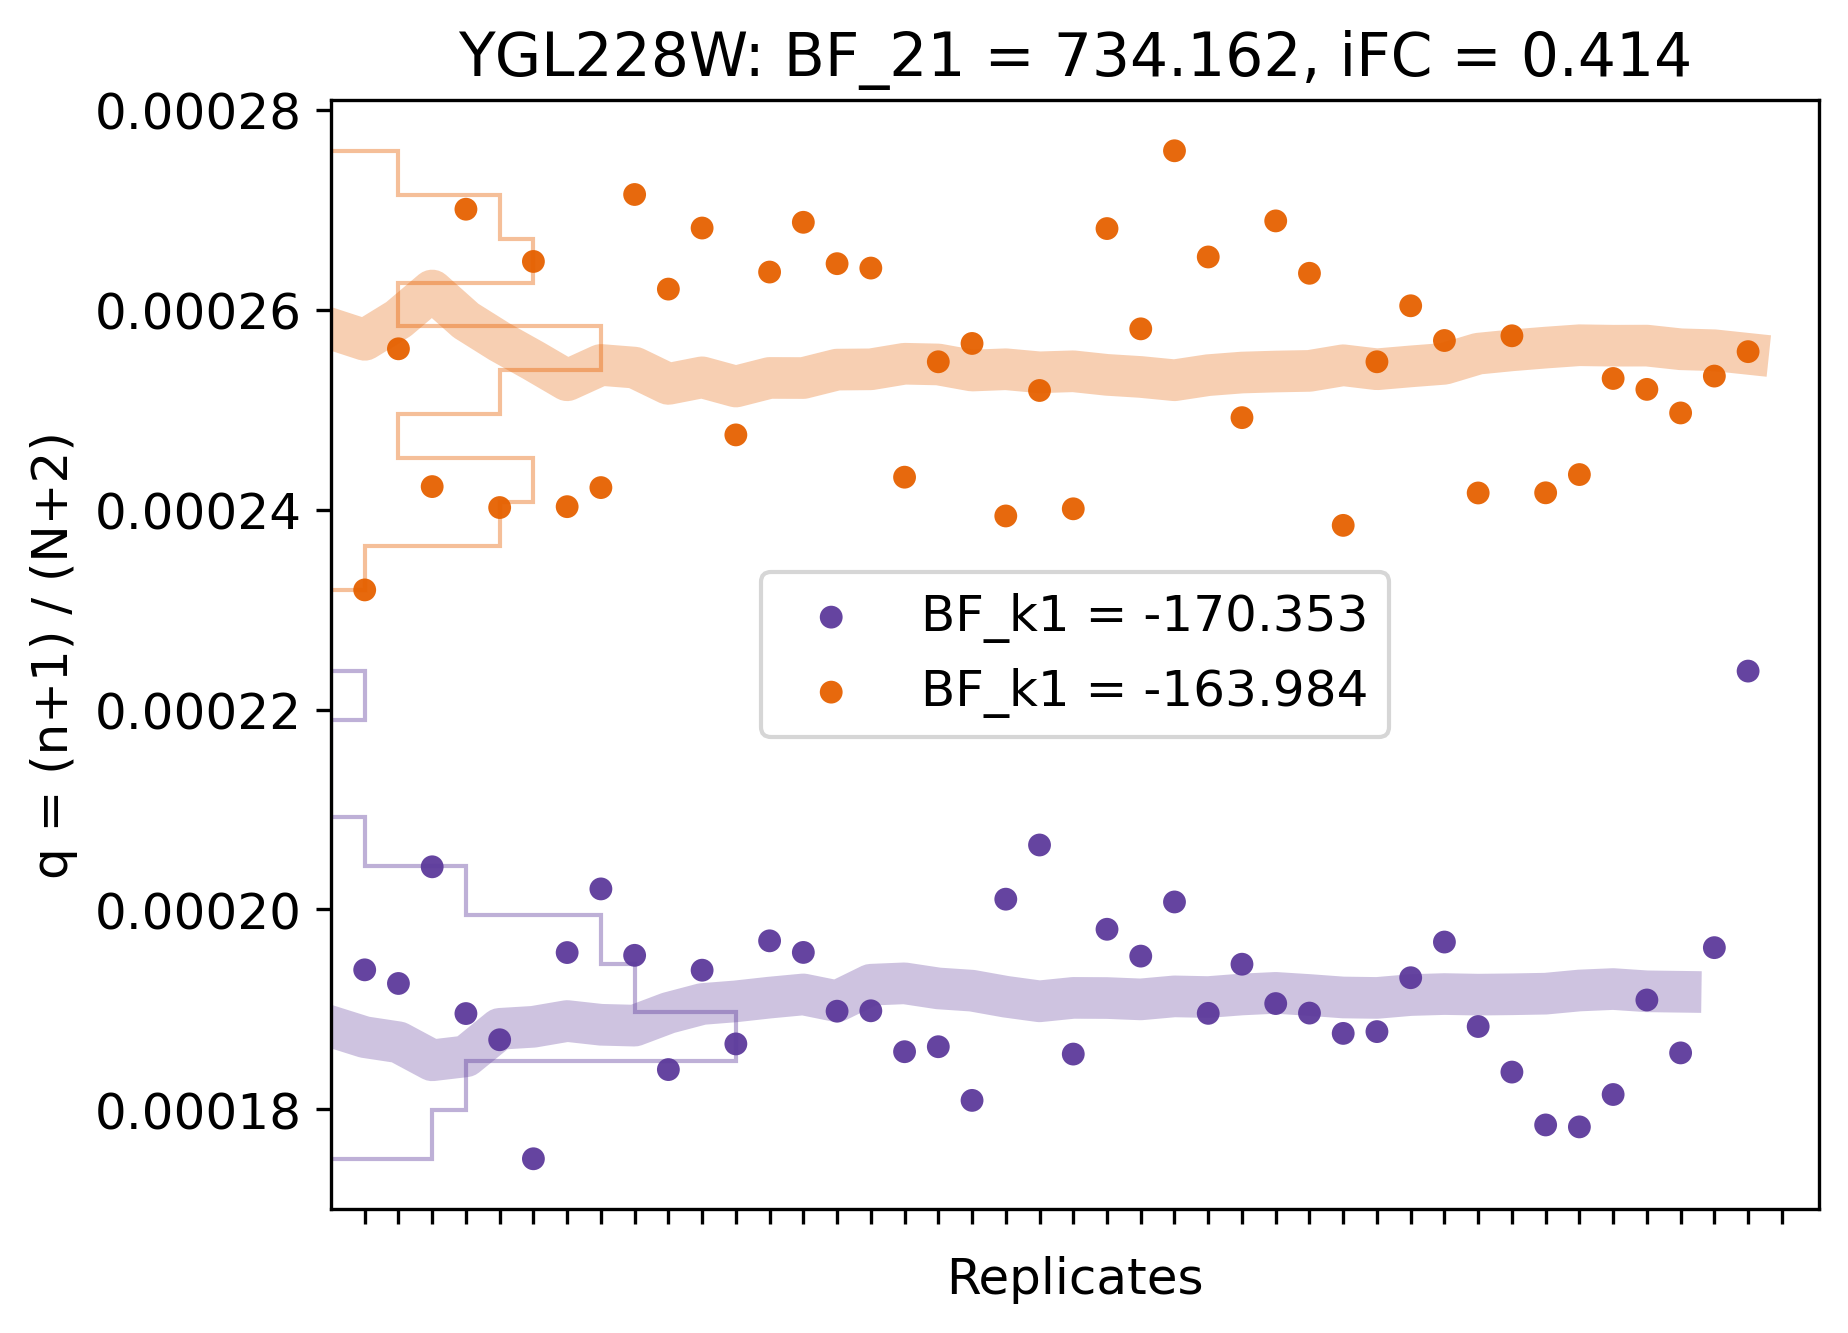

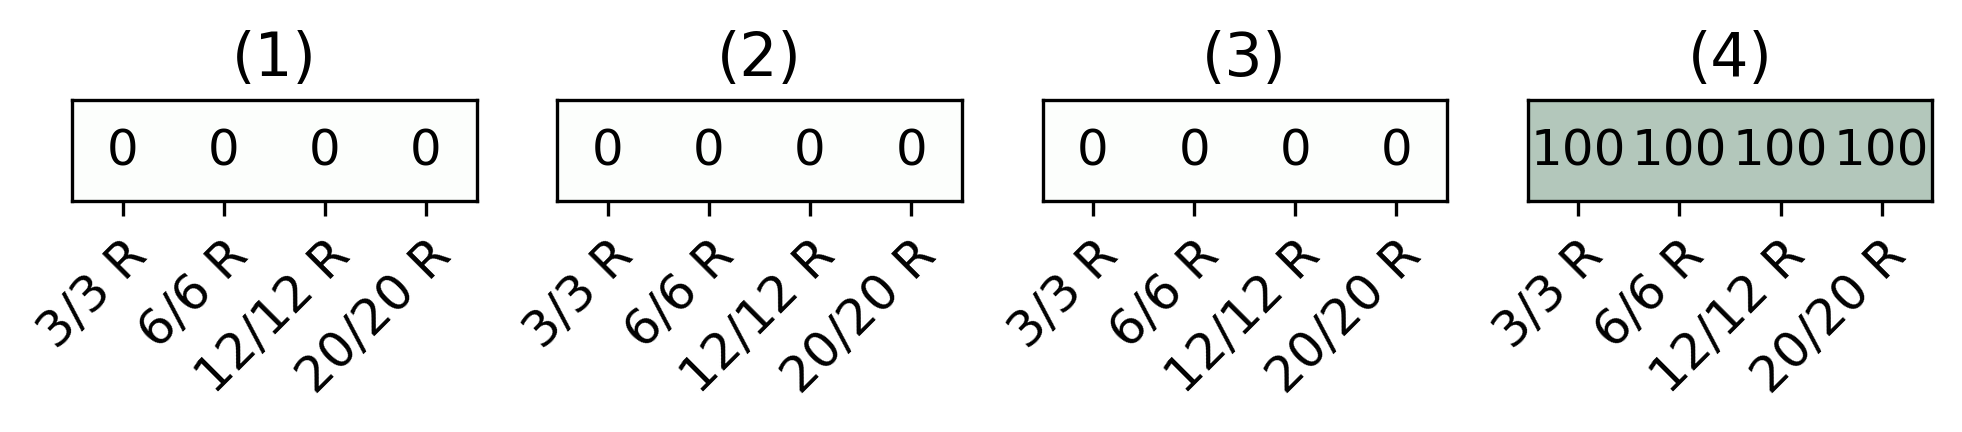

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
395,YBR078W,6824,9337,7478,13172,8986,17113,10497,11067,9671,...,8691,13594,11277,8264,7706,9673,14434,6381,13324,9939


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
395,YBR078W,12495,11380,10844,12078,8963,13687,9785,13099,9220,...,17699,9657,11872,9318,12682,10478,10435,11837,10656,9764


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
395,YBR078W,163.131687,0.084818,-0.154711,False,278.297316,True


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


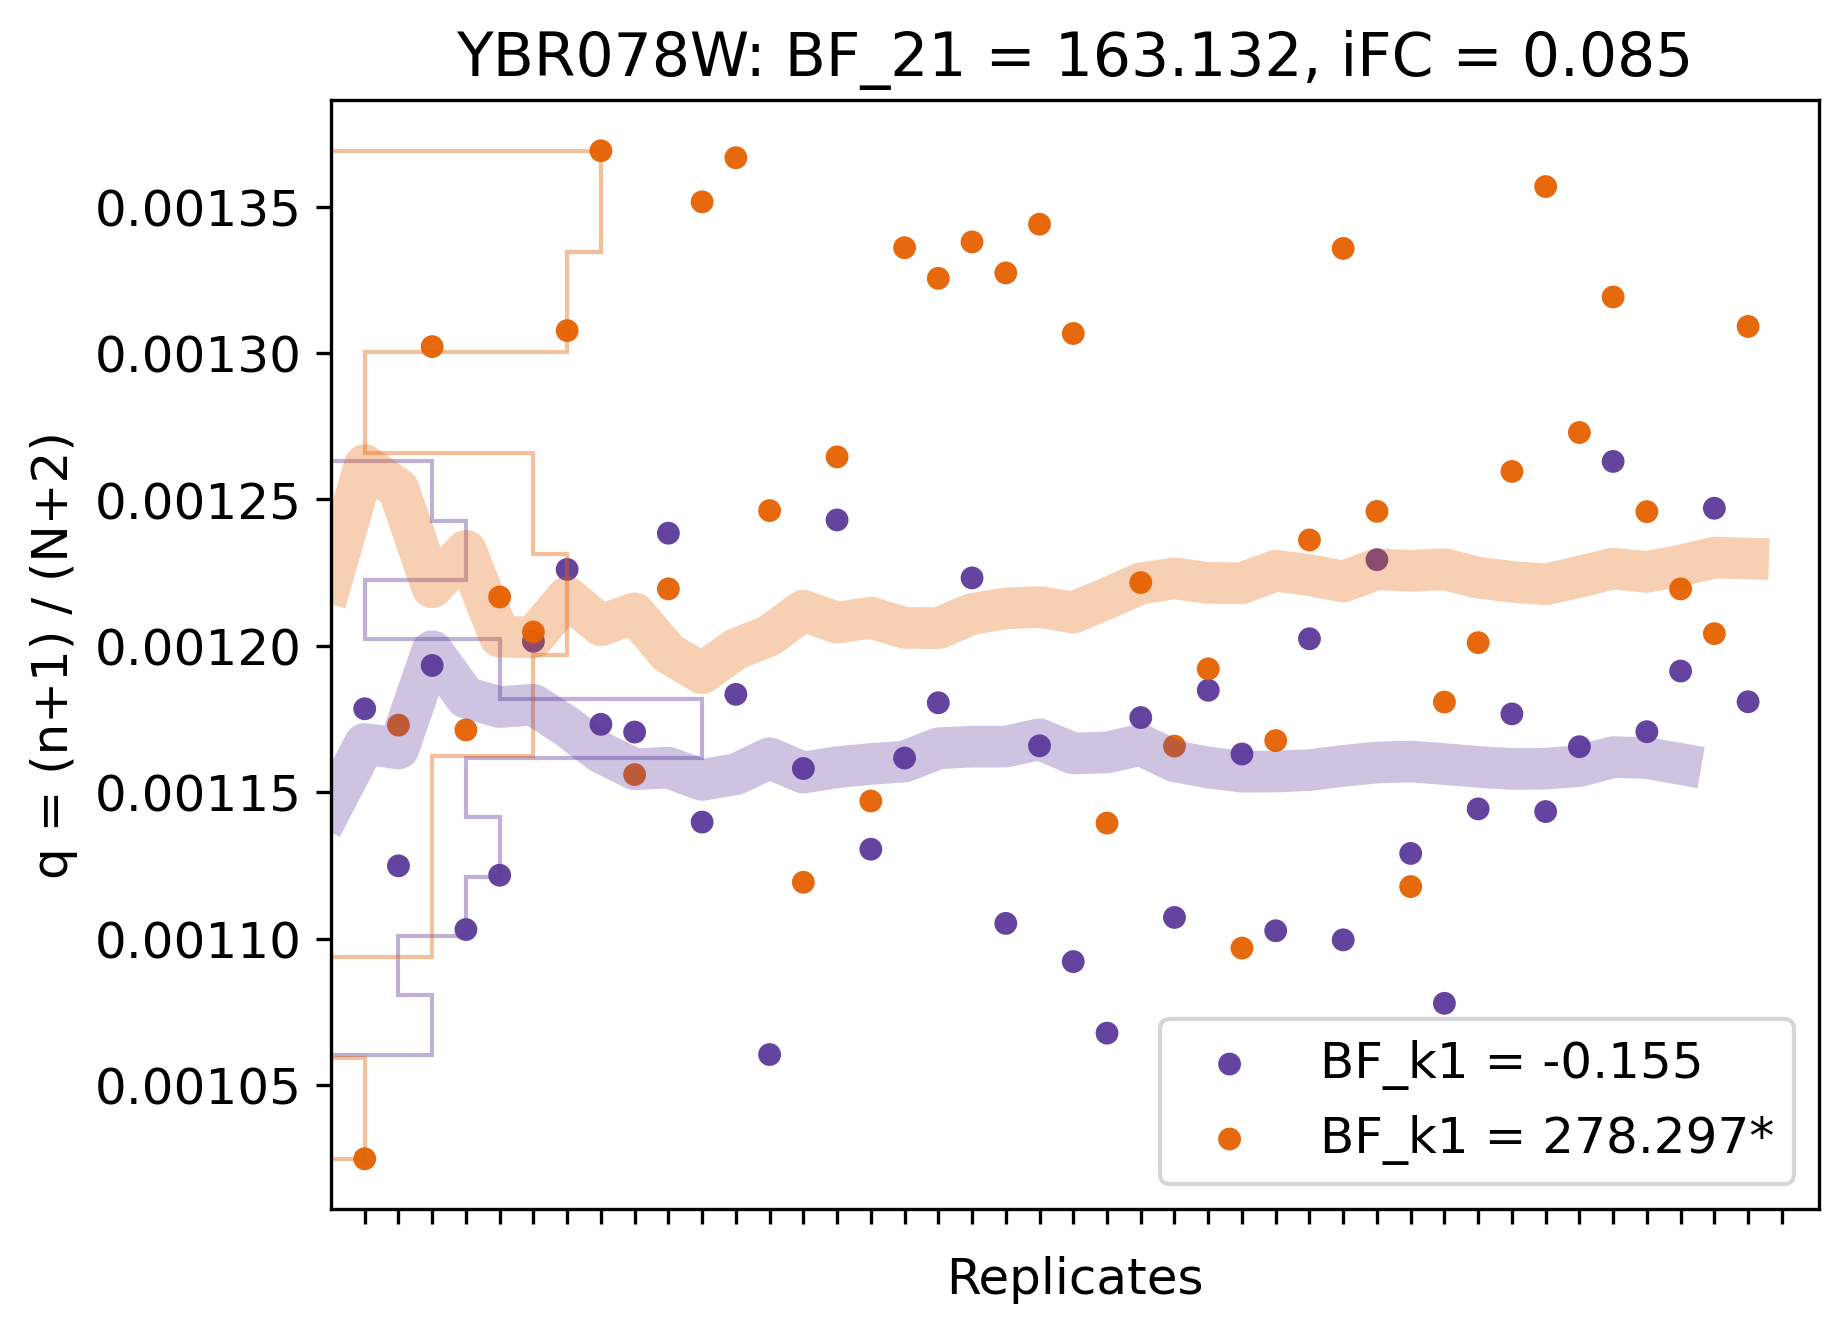

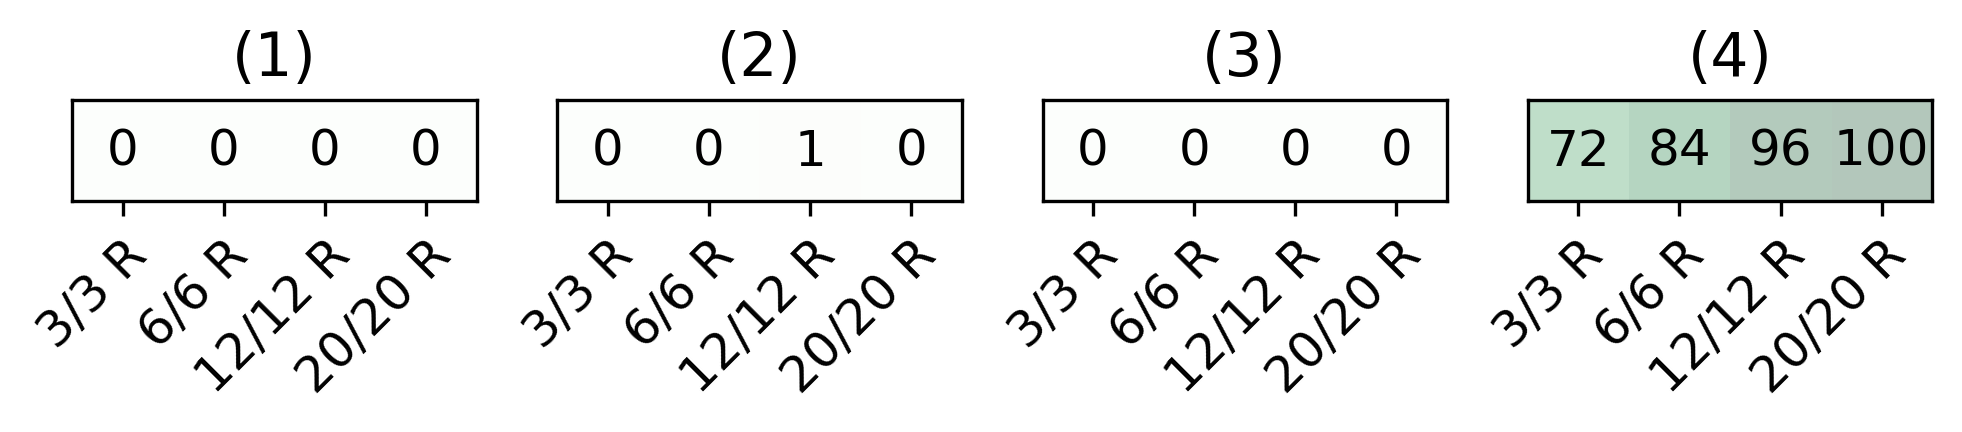

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
3179,YIL094C,1744,2539,1824,3084,2347,4363,2772,3019,2622,...,2315,3499,2998,2146,1856,2513,3661,1687,3811,2254


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
3179,YIL094C,1753,1543,1387,1617,1174,1857,1478,1731,1210,...,2503,1342,1815,1141,1464,1468,1335,1432,1521,1184


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
3179,YIL094C,3256.618809,-0.861366,-150.200504,False,-171.690121,False


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


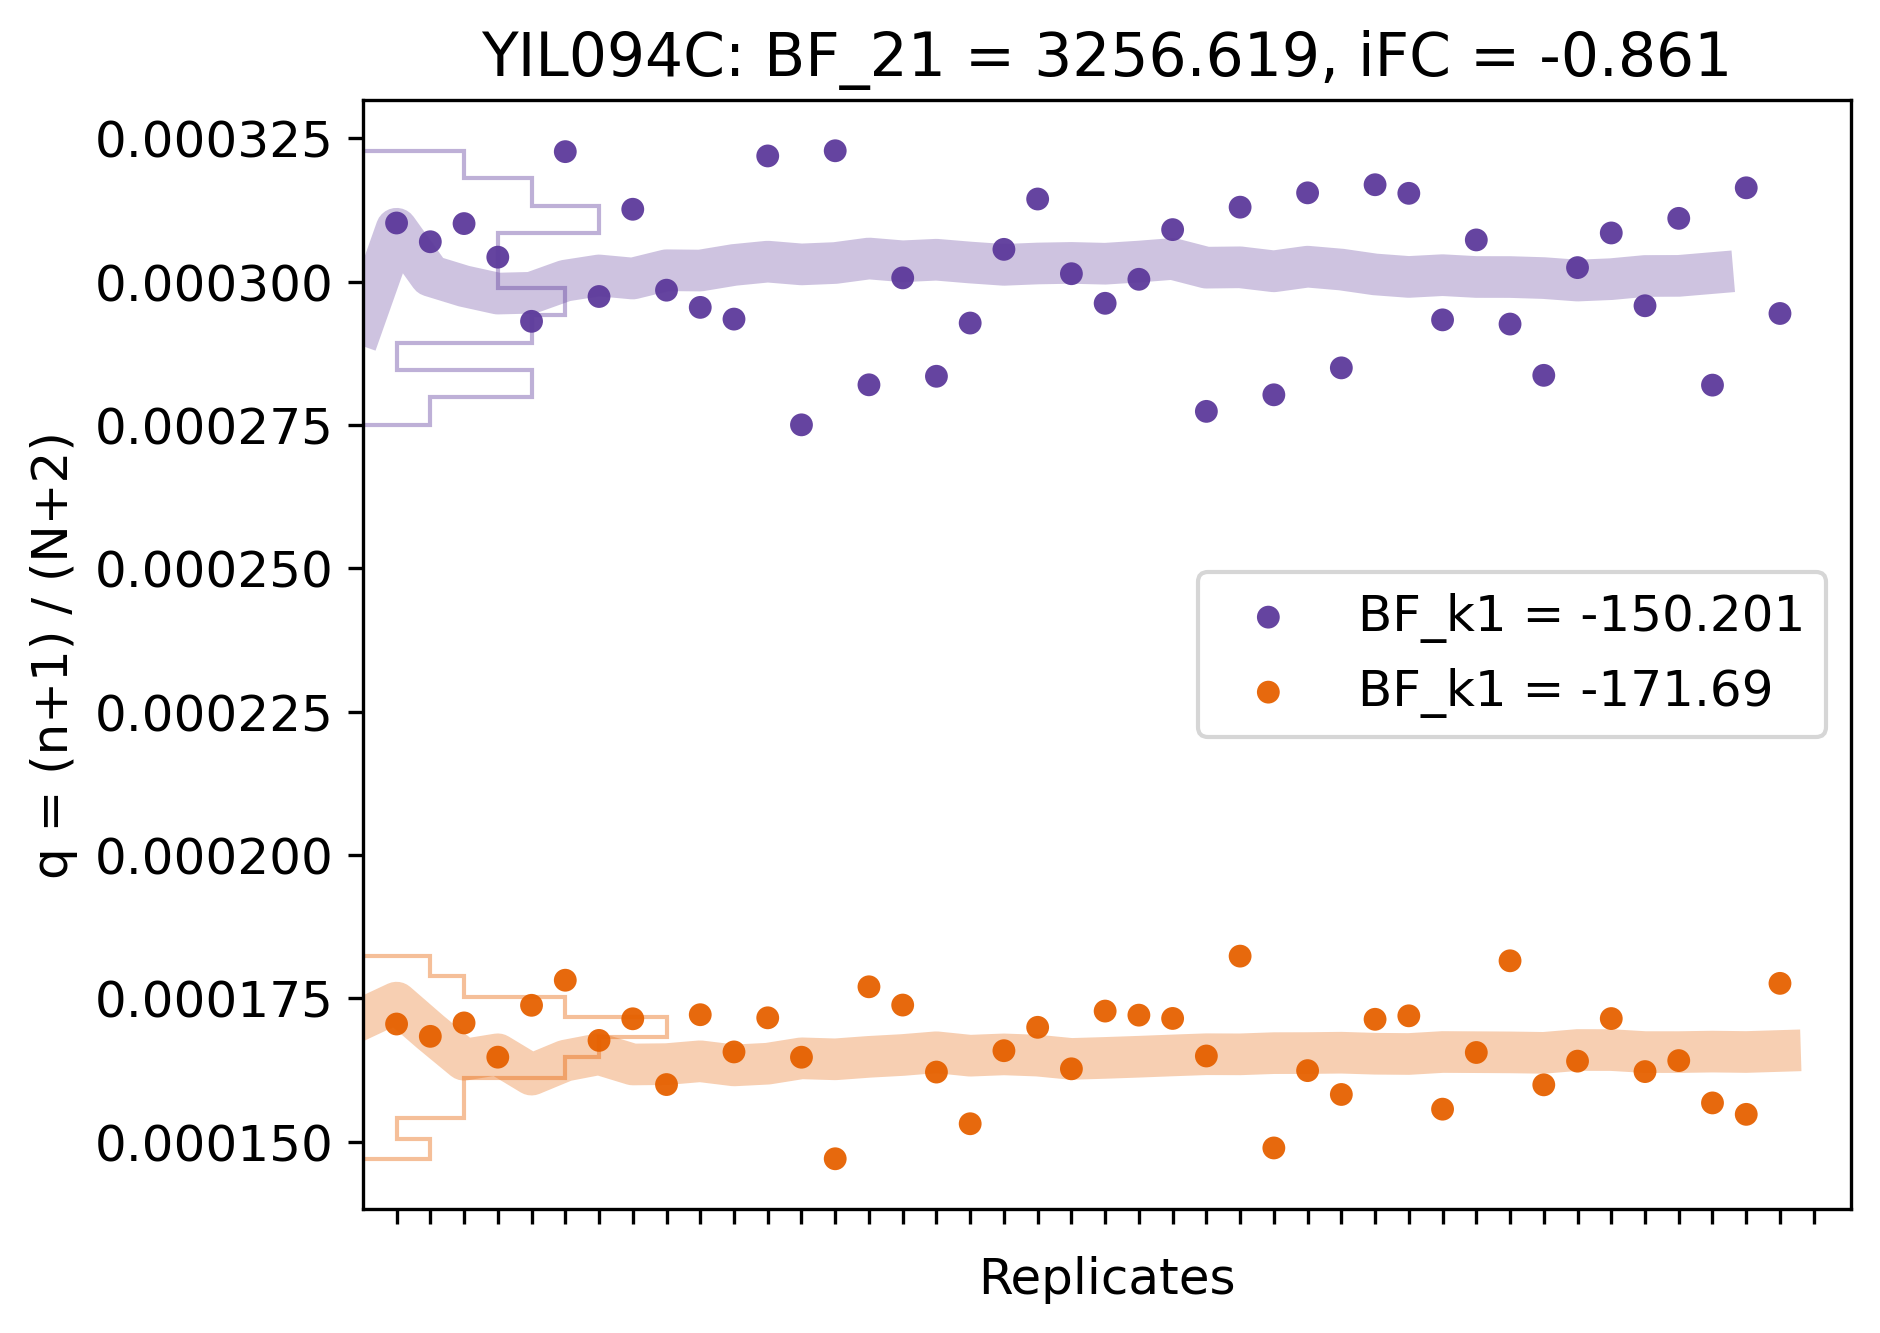

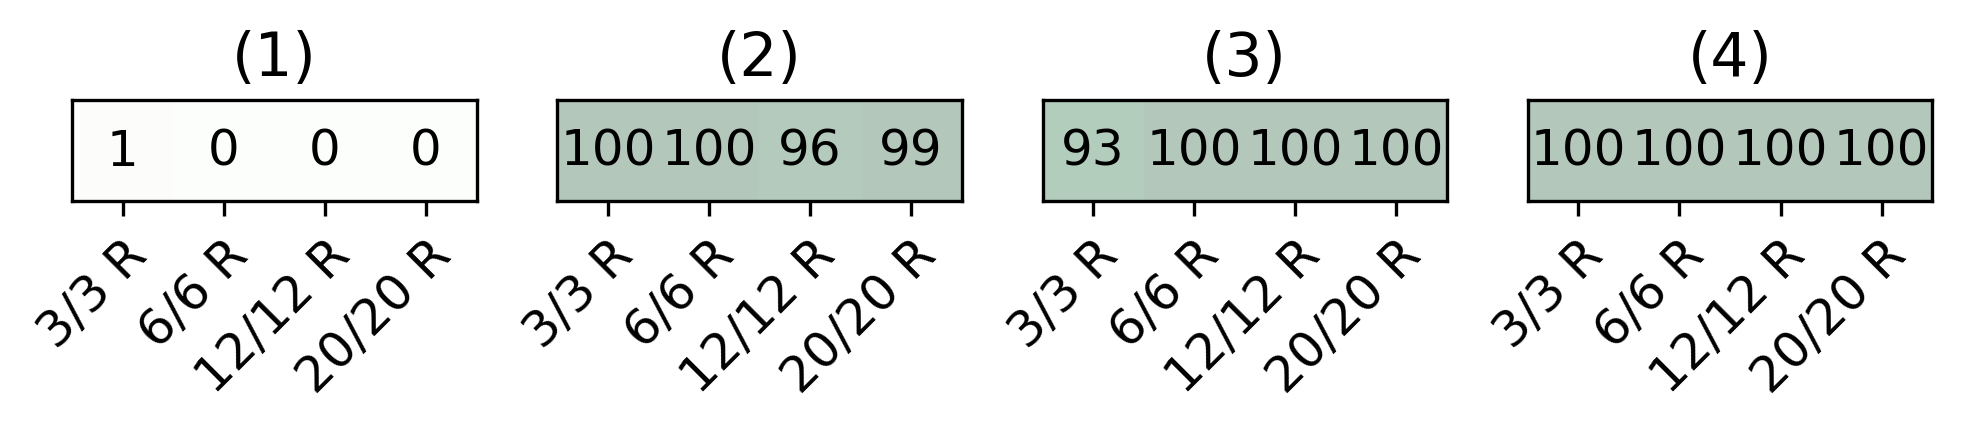

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
2417,YGL253W,16947,22007,19773,29671,21819,40508,26237,30426,24864,...,21124,34287,26821,21482,19087,23306,32459,16215,33248,22441


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
2417,YGL253W,32160,26611,26422,30372,18786,37250,26768,29112,23861,...,43465,23810,30315,20020,26317,26666,21046,23698,25546,17457


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
2417,YGL253W,12.997108,0.017858,209.824321,True,628.468949,True


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


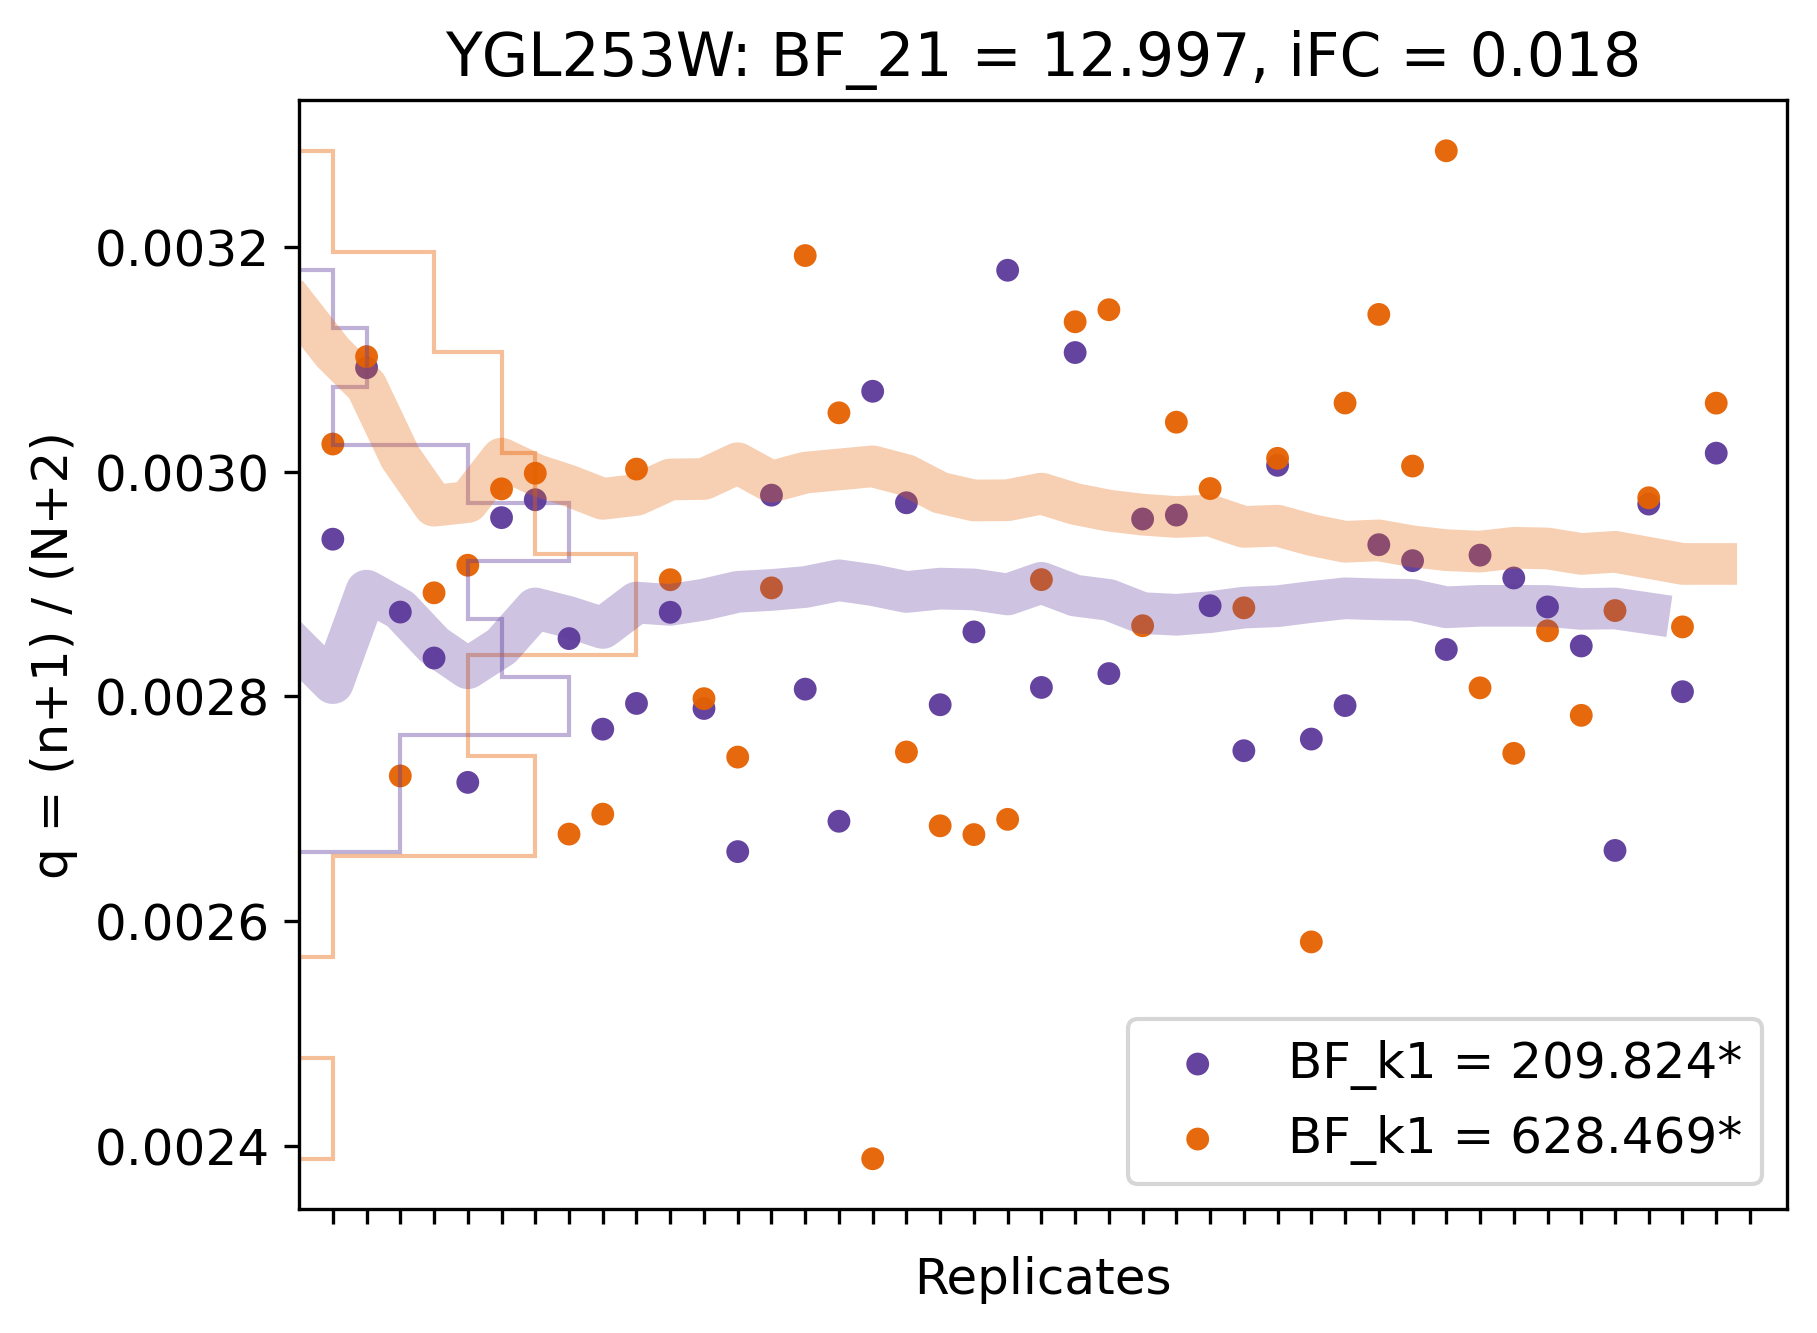

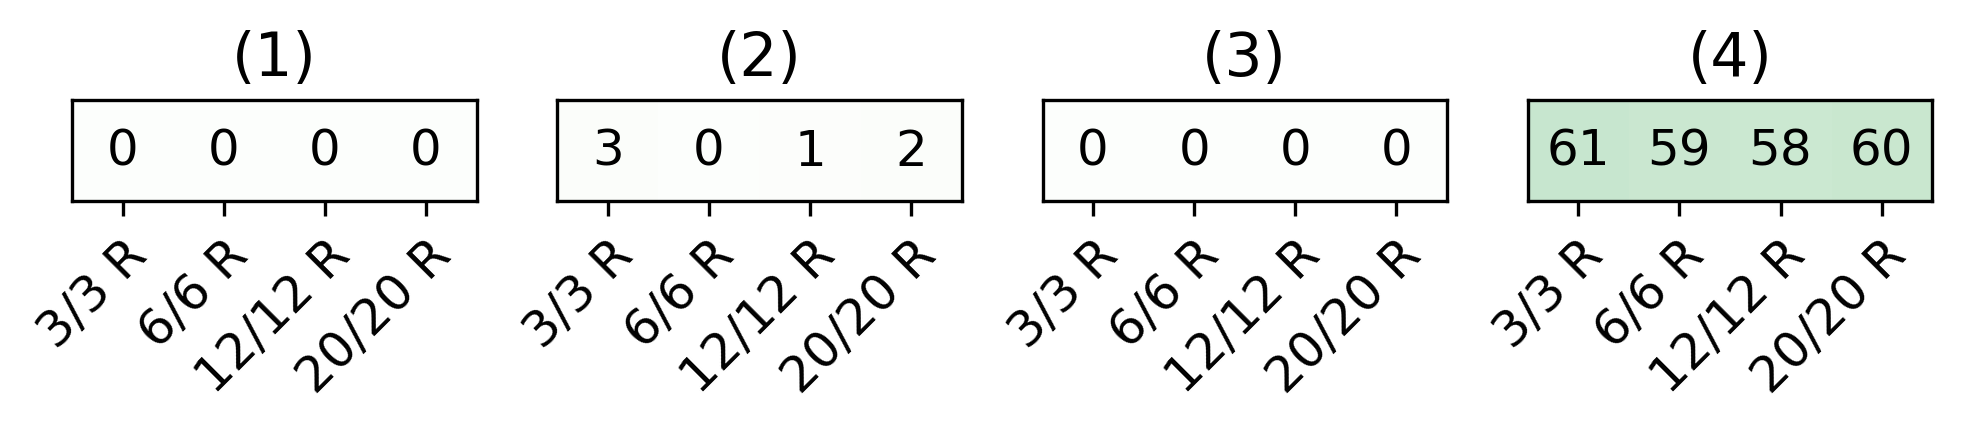

[None, None, None, None]

In [59]:
[stalk([gene]) for gene in ['YGL228W', 'YBR078W', 'YIL094C', 'YGL253W']]

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
2639,YGR192C,188825,196804,172119,328674,225435,357247,261535,343455,268394,...,246621,358116,278531,209062,191739,318398,338511,169415,348635,244192


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
2639,YGR192C,205731,199983,210124,204494,158243,242692,209080,210681,178901,...,323457,180745,239701,163673,219417,167478,177709,170179,160083,142435


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
2639,YGR192C,101517.928512,-0.456369,52530.251796,True,23438.201797,True


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


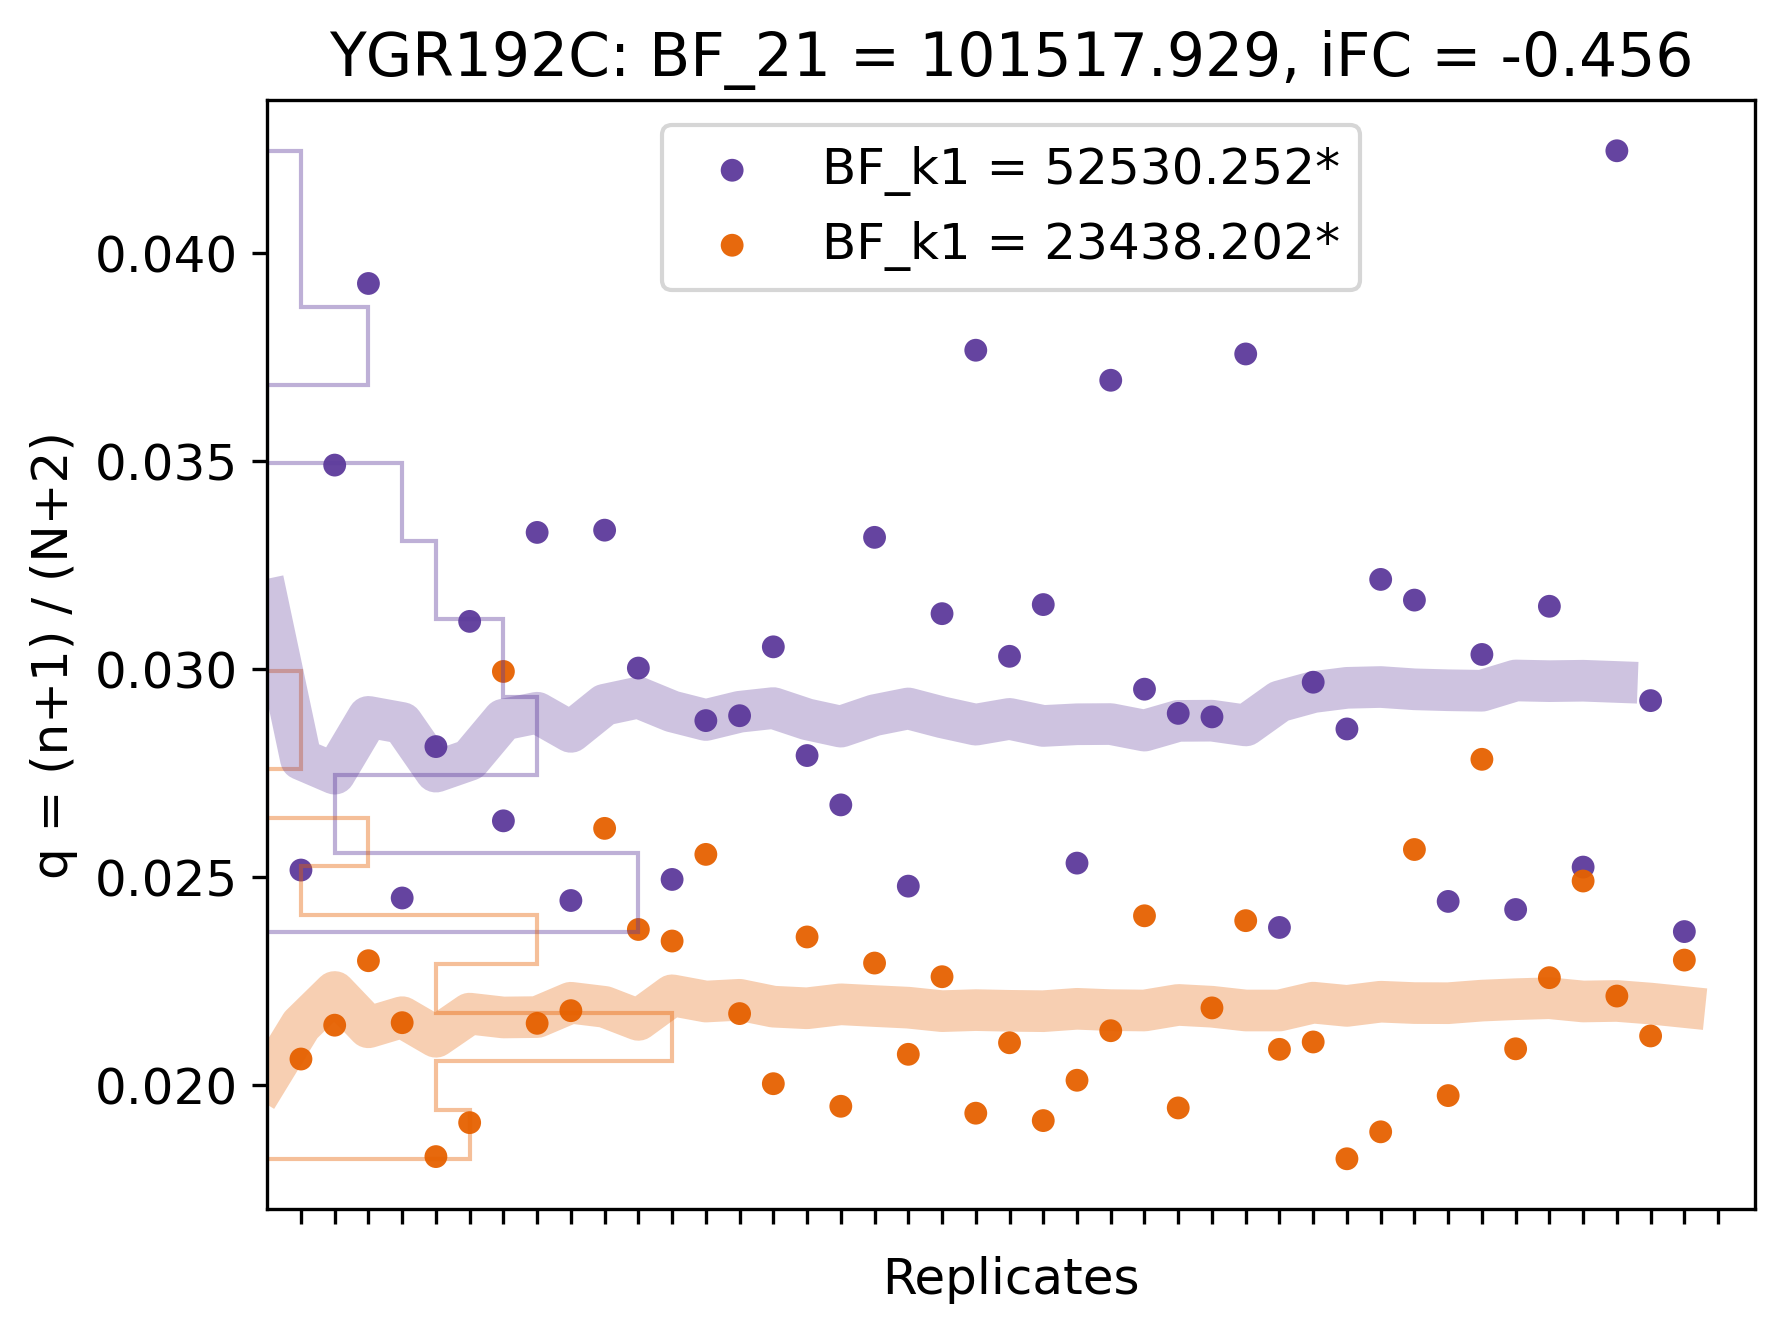

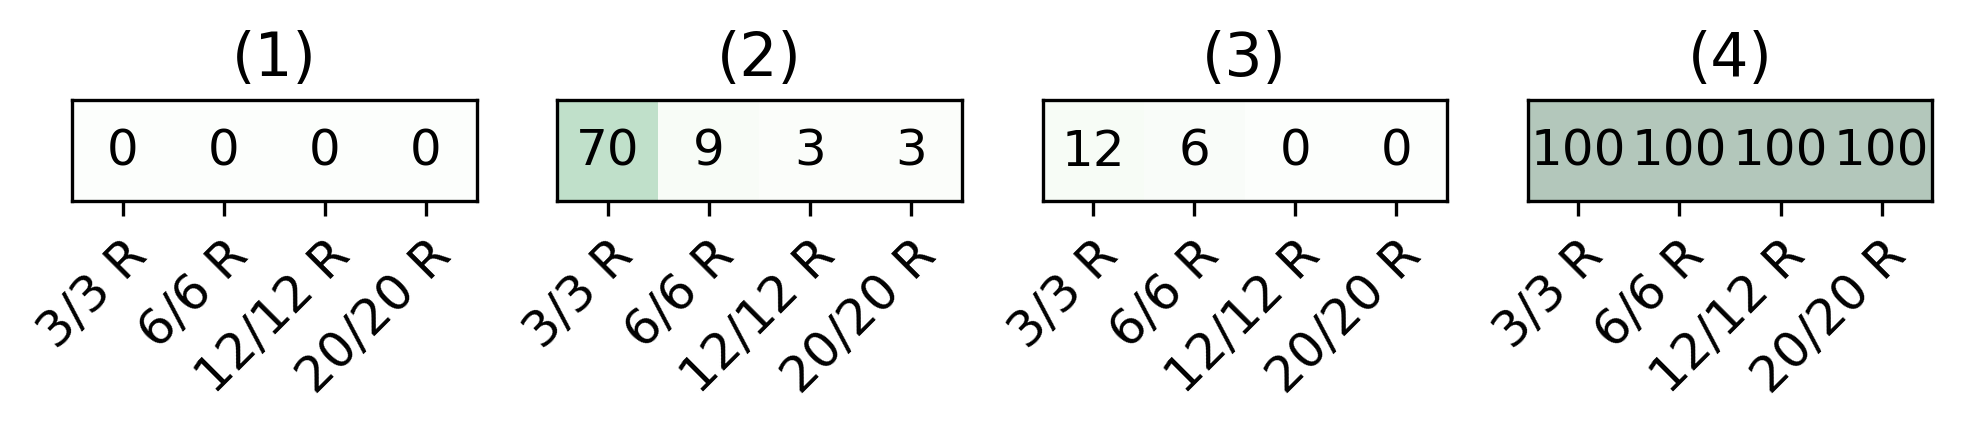

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
6209,YOR383C,12713,11599,10437,18694,10940,21254,11928,20445,14405,...,11286,21585,17444,12251,10503,16357,18733,8162,19044,14295


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
6209,YOR383C,36728,39745,40978,49945,33631,56767,31049,52374,33049,...,60183,37108,50351,34465,46750,37686,43105,47984,34235,29763


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
6209,YOR383C,118338.158193,1.478789,1920.042323,True,10685.558763,True


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


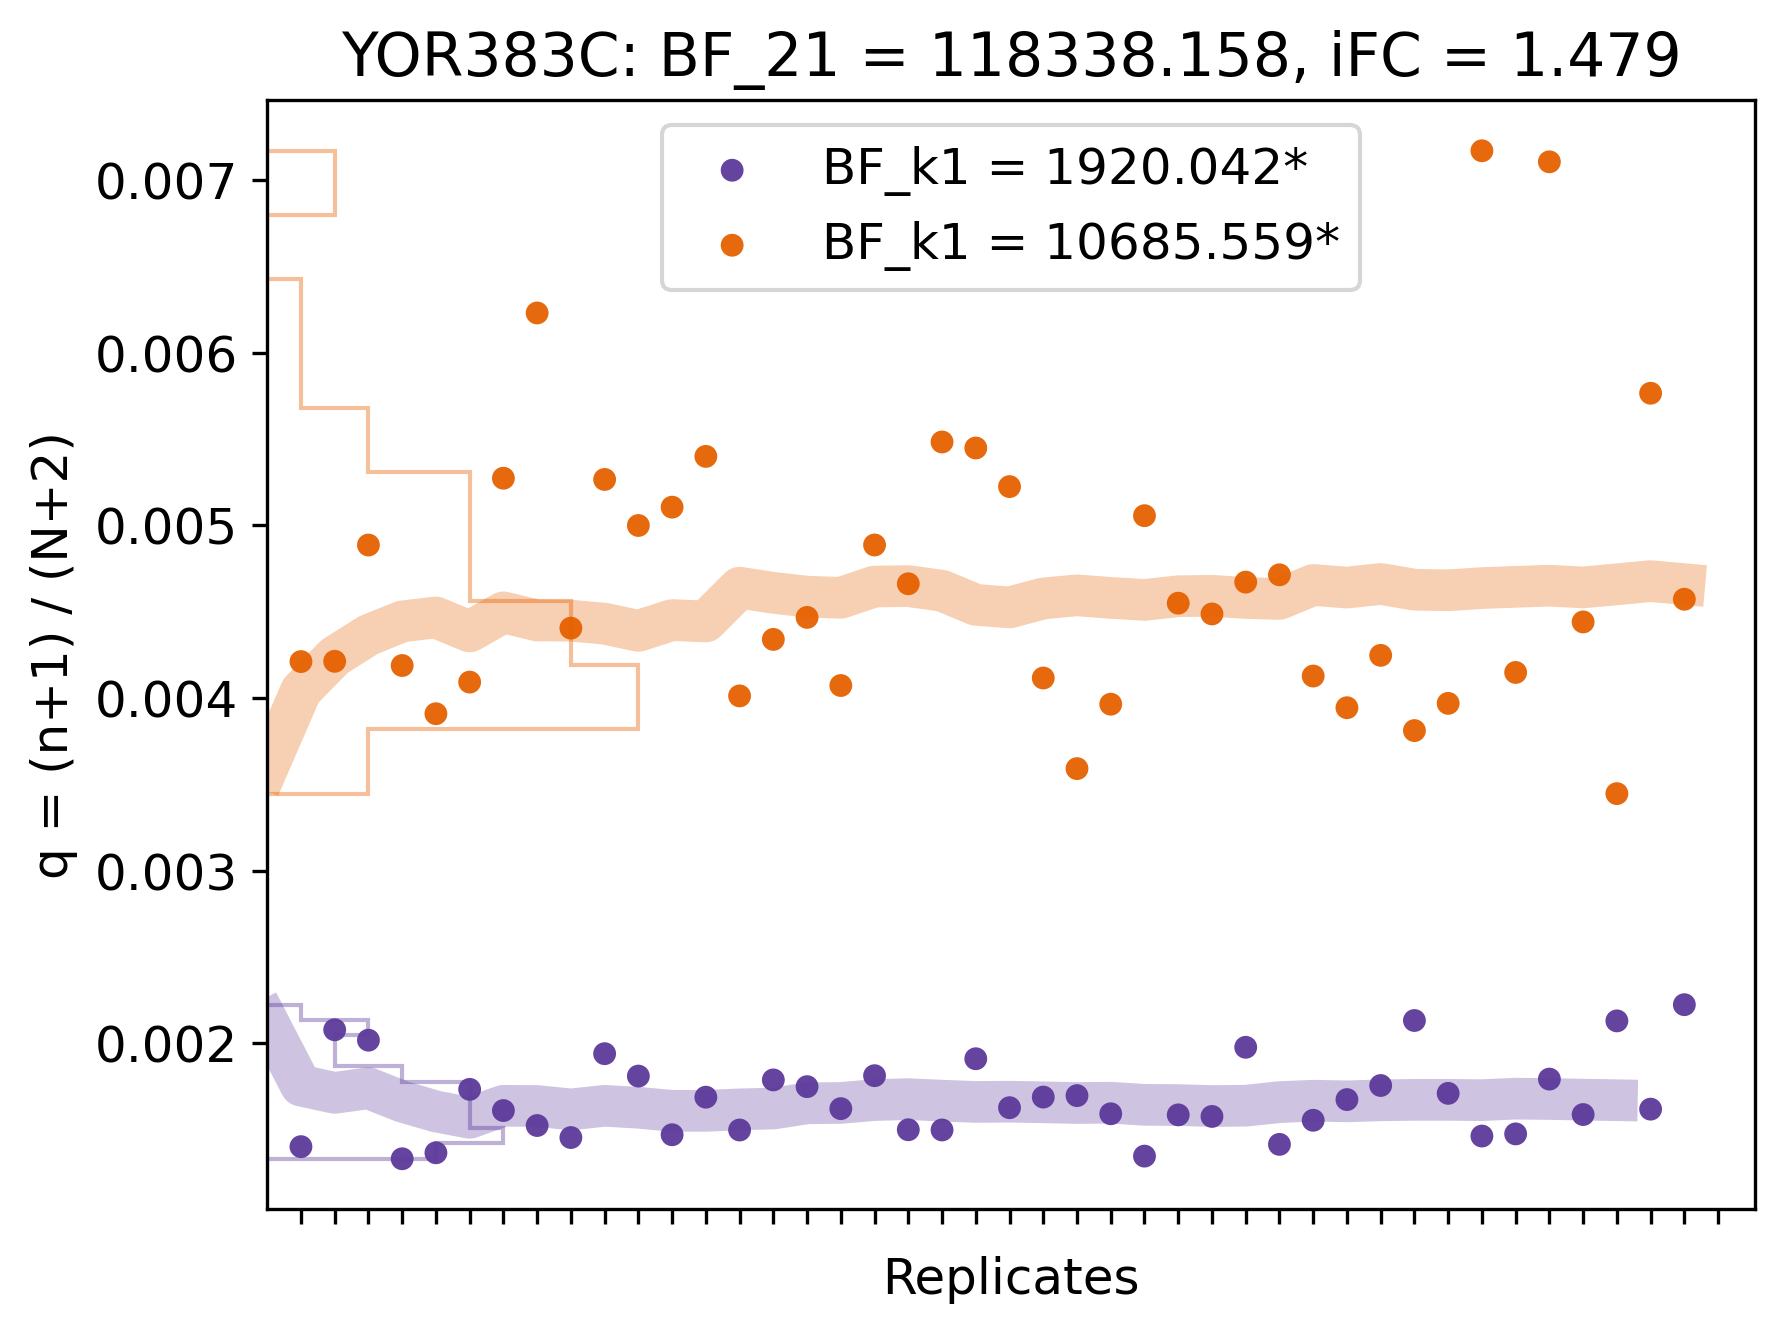

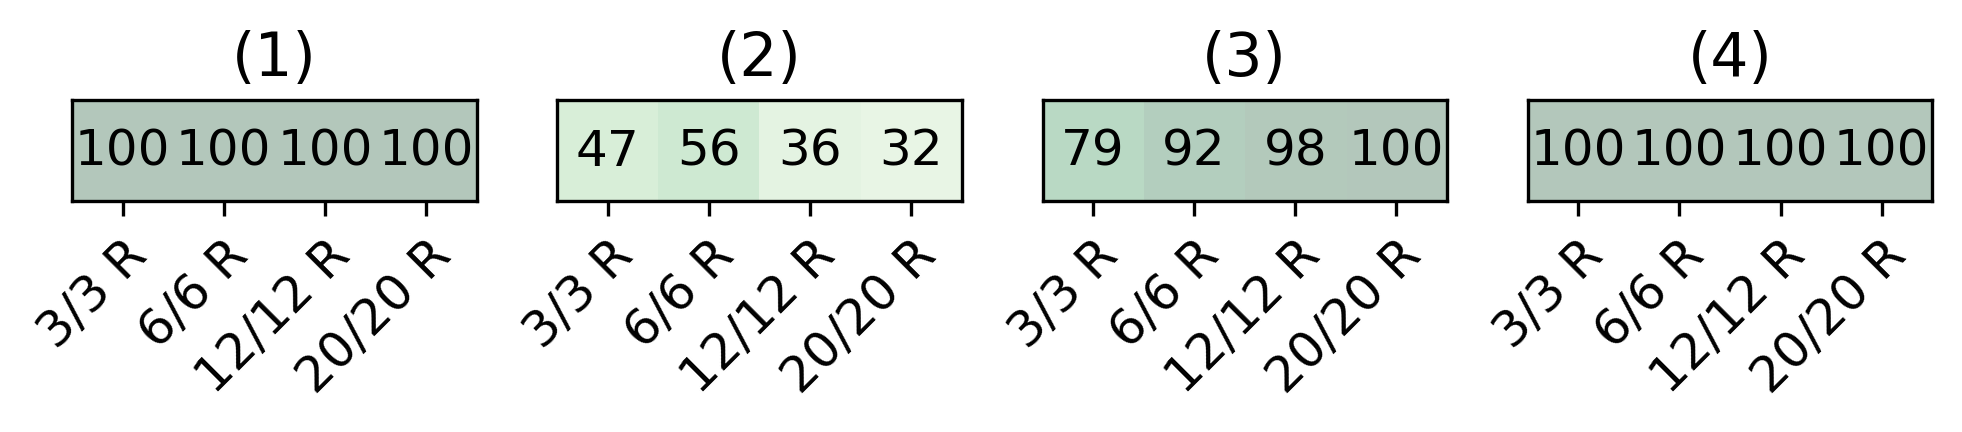

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
3012,YHR174W,129581,133346,109168,207147,145674,268592,196925,211933,189789,...,157763,235246,191877,136675,120124,195917,243868,107856,237778,158290


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
3012,YHR174W,107206,100381,112005,104187,76754,126571,101232,105342,114602,...,165739,86105,112391,81618,106975,86521,85779,95411,83560,75125


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
3012,YHR174W,205922.03536,-0.847059,13841.417356,True,7918.998188,True


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


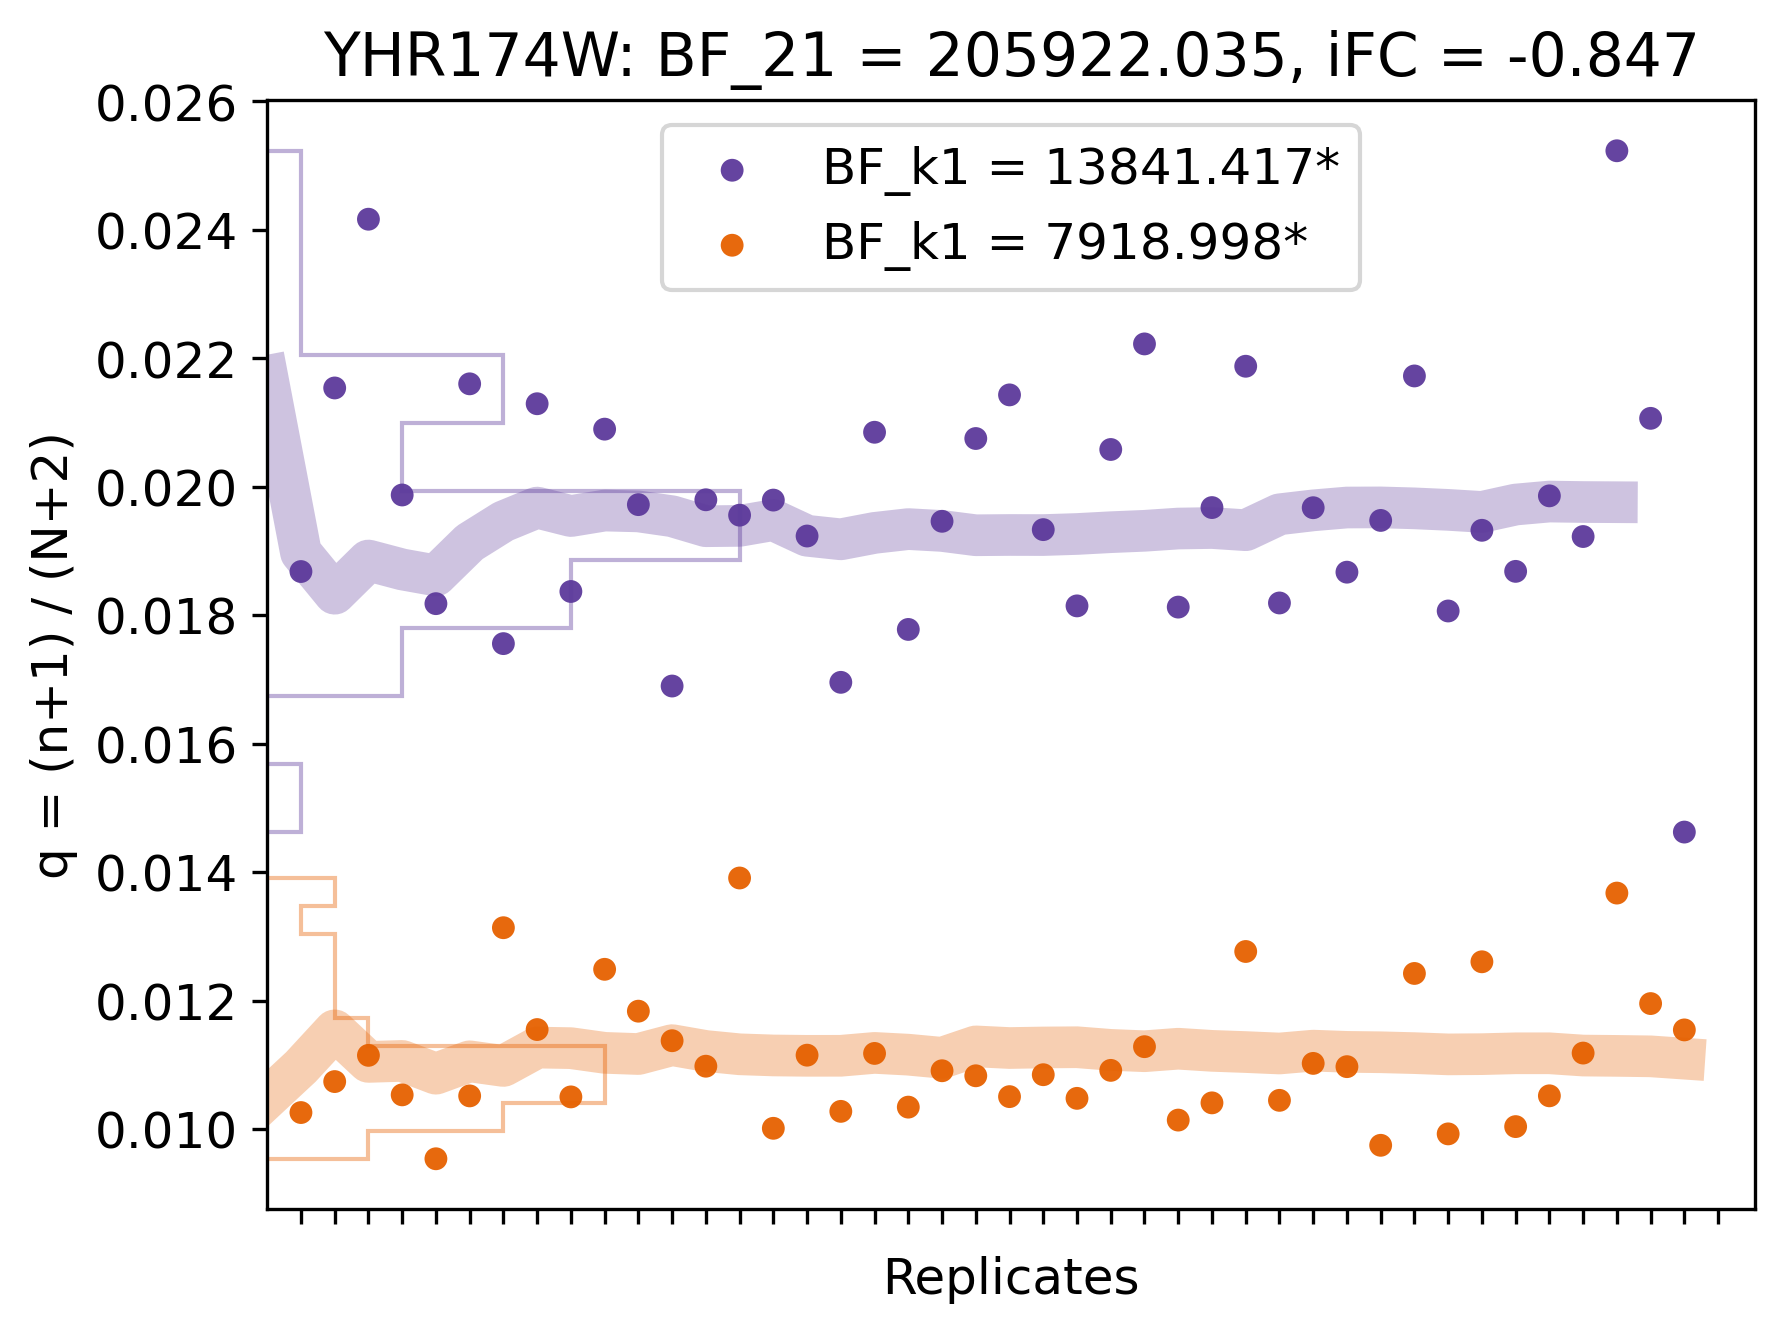

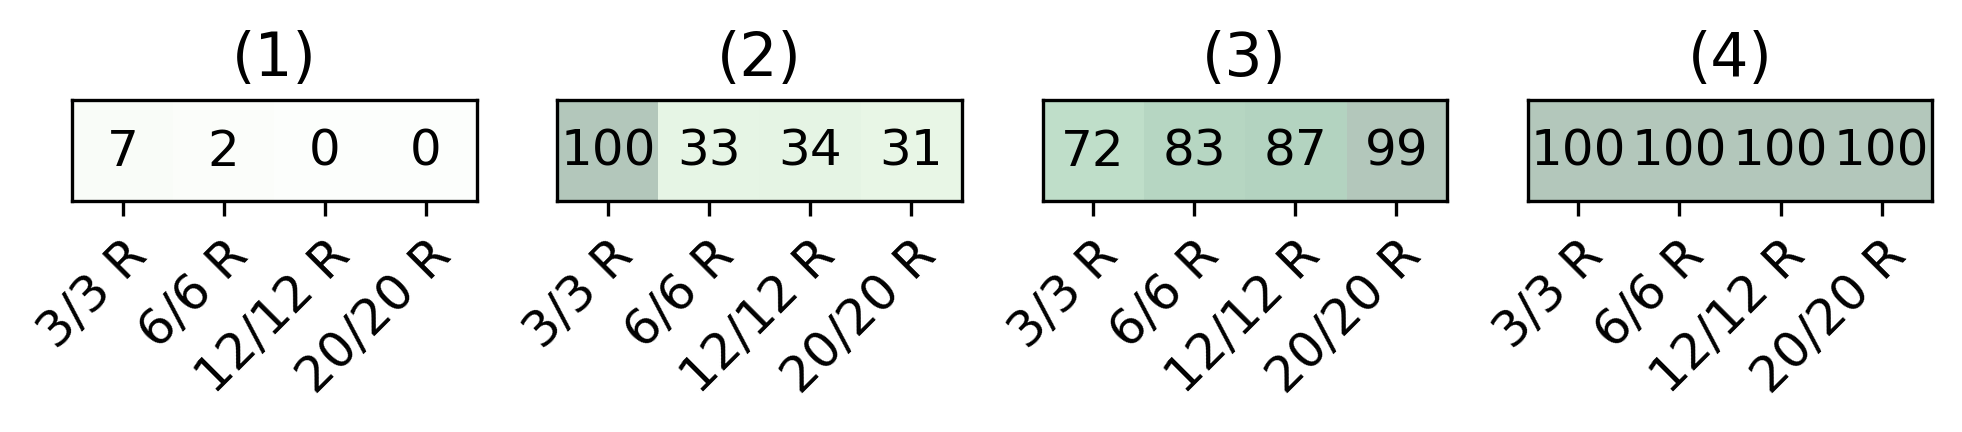

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
1175,YDR077W,35563,31153,31852,54048,30594,65771,39147,58449,45629,...,37196,63004,38304,36697,33838,54827,54371,26658,50782,45913


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
1175,YDR077W,5978,5813,4679,5852,4049,9193,4939,4684,2002,...,9285,5125,7021,4165,5594,5013,4016,3755,4674,3275


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
1175,YDR077W,341558.582413,-3.175344,13017.391966,True,1422.483953,True


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


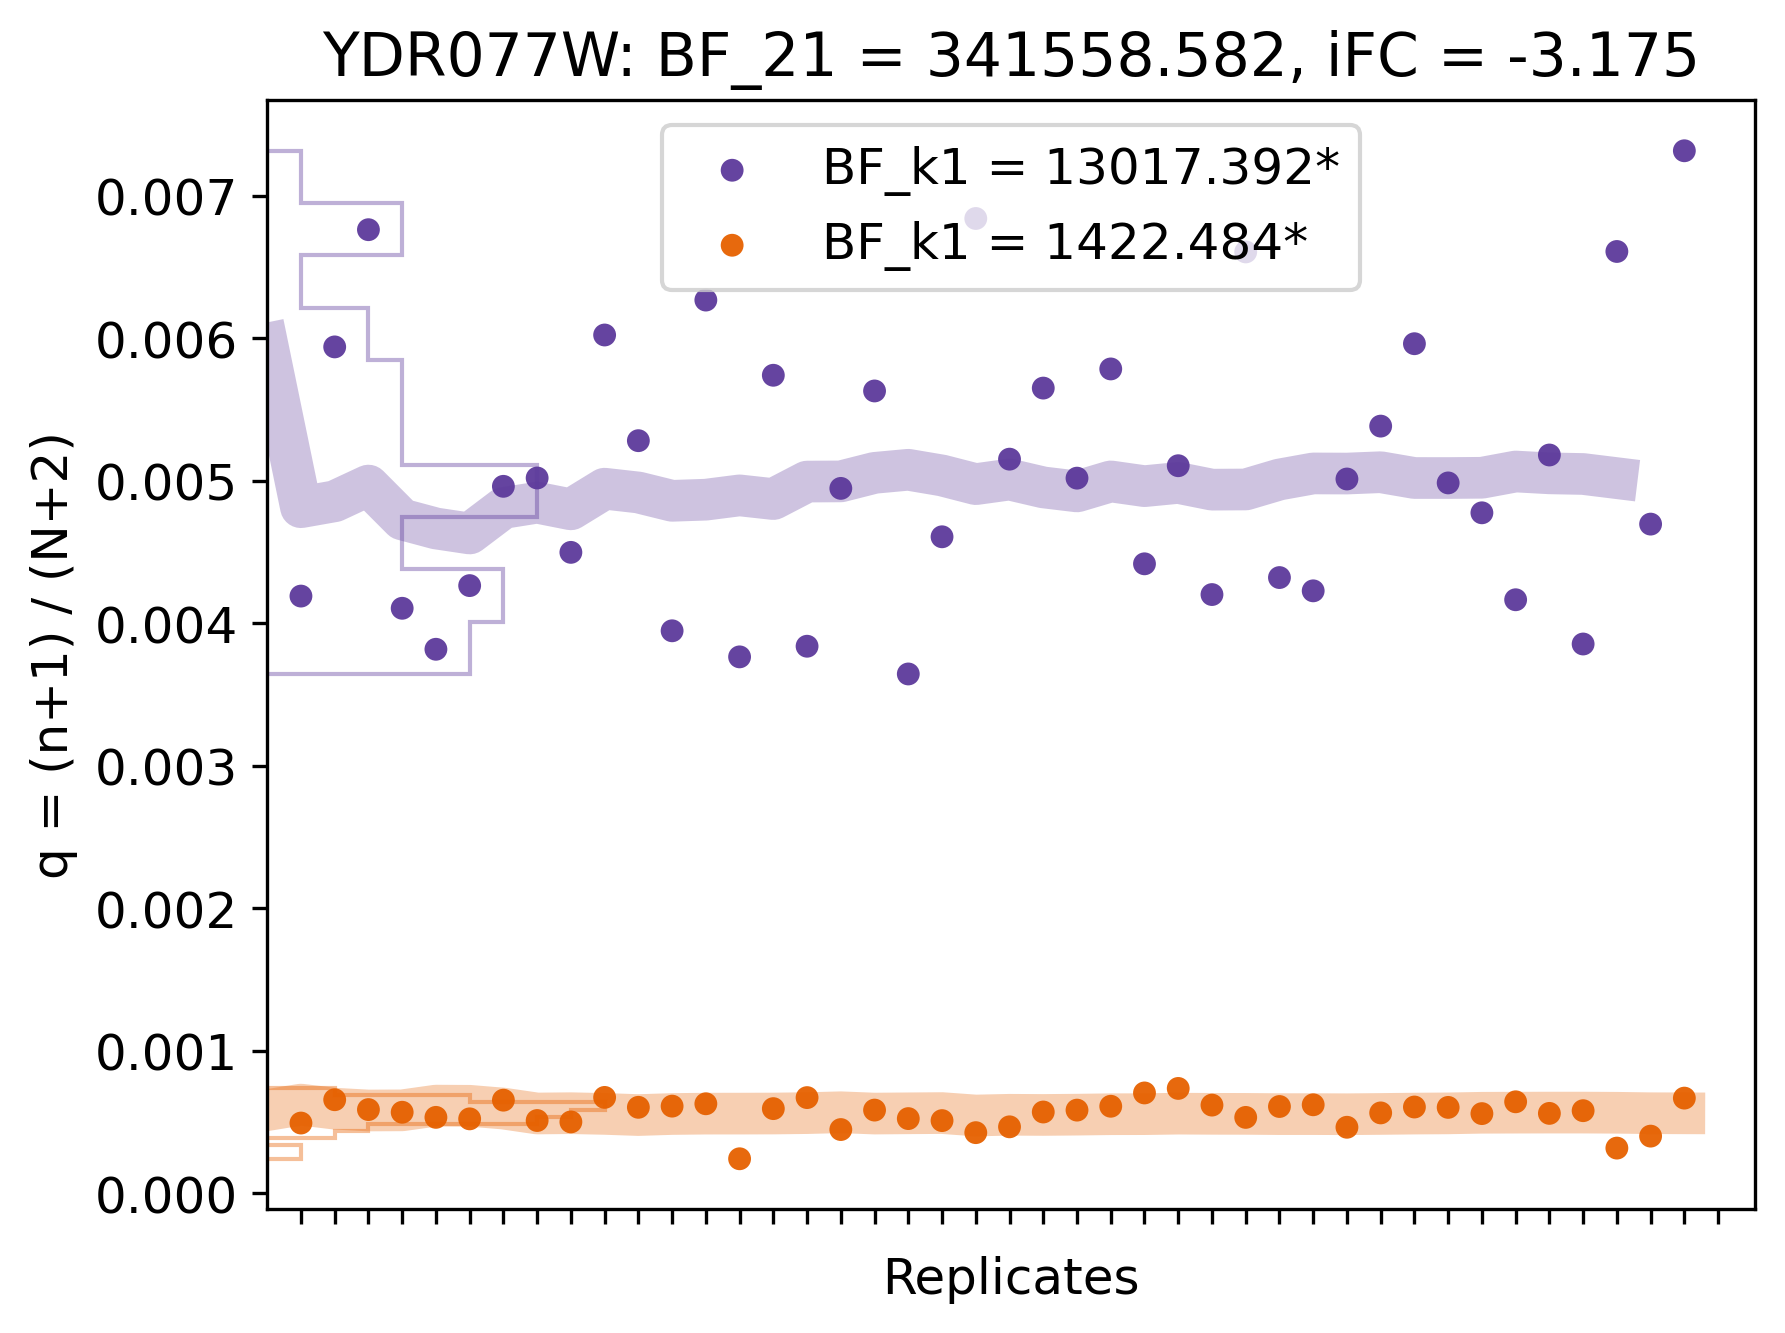

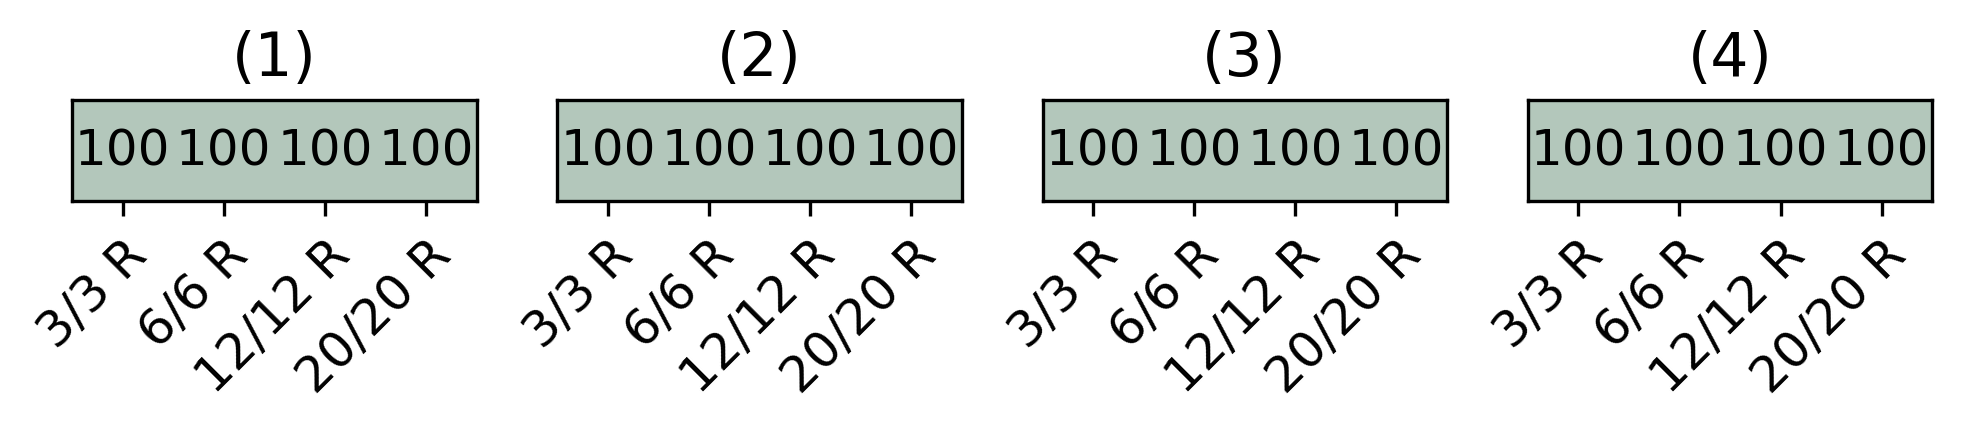

[None, None, None, None]

In [60]:
[stalk([gene]) for gene in ['YGR192C', 'YOR383C', 'YHR174W', 'YDR077W']]

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
5422,YNL232W,388,697,459,658,779,1276,674,718,769,...,528,775,833,529,395,536,1068,385,1080,515


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
5422,YNL232W,841,622,644,855,573,983,688,772,635,...,1335,666,913,595,804,679,714,710,768,646


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
5422,YNL232W,7.1749,0.090803,-48.996454,False,-181.486812,False


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


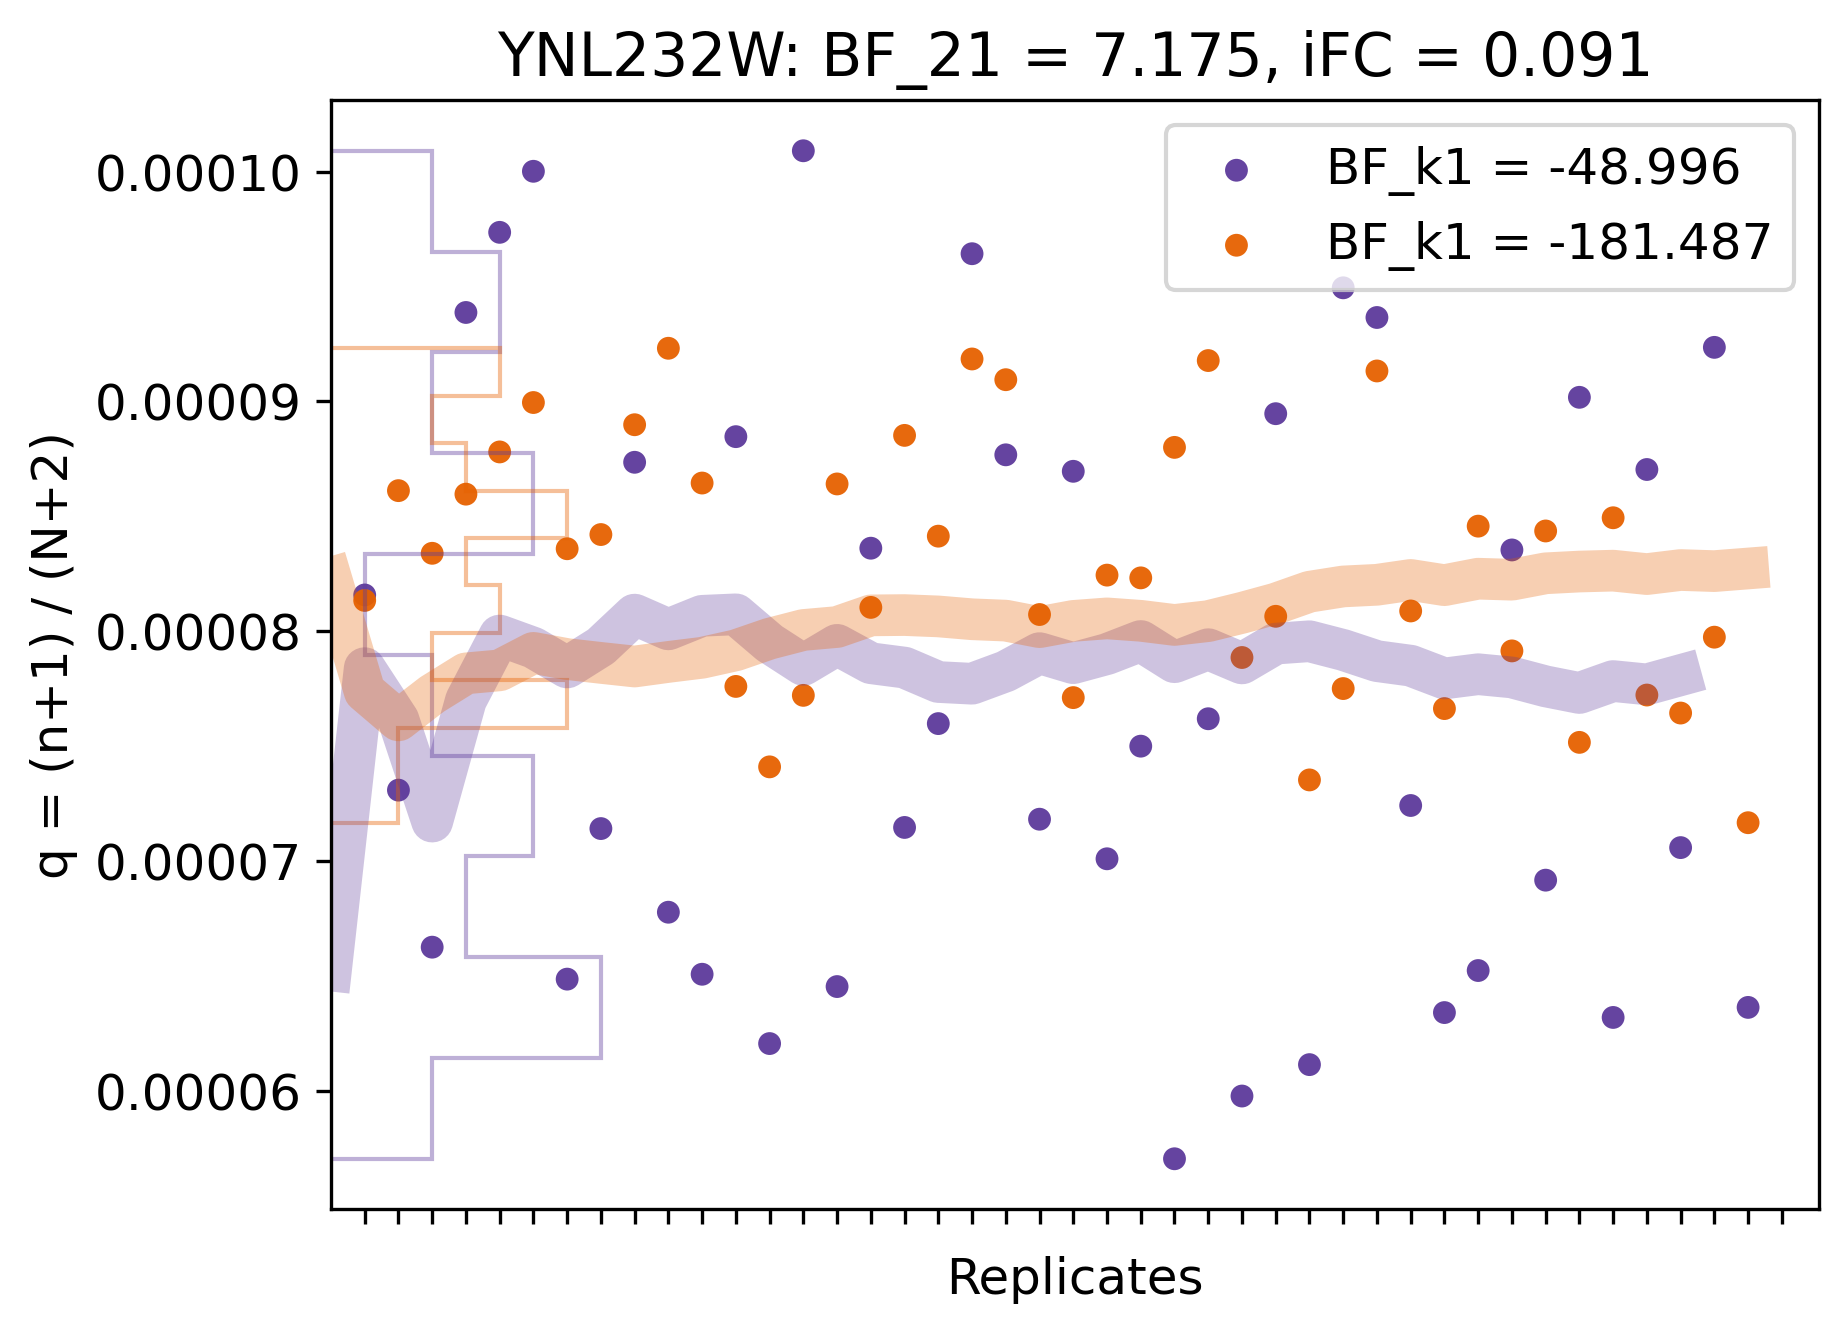

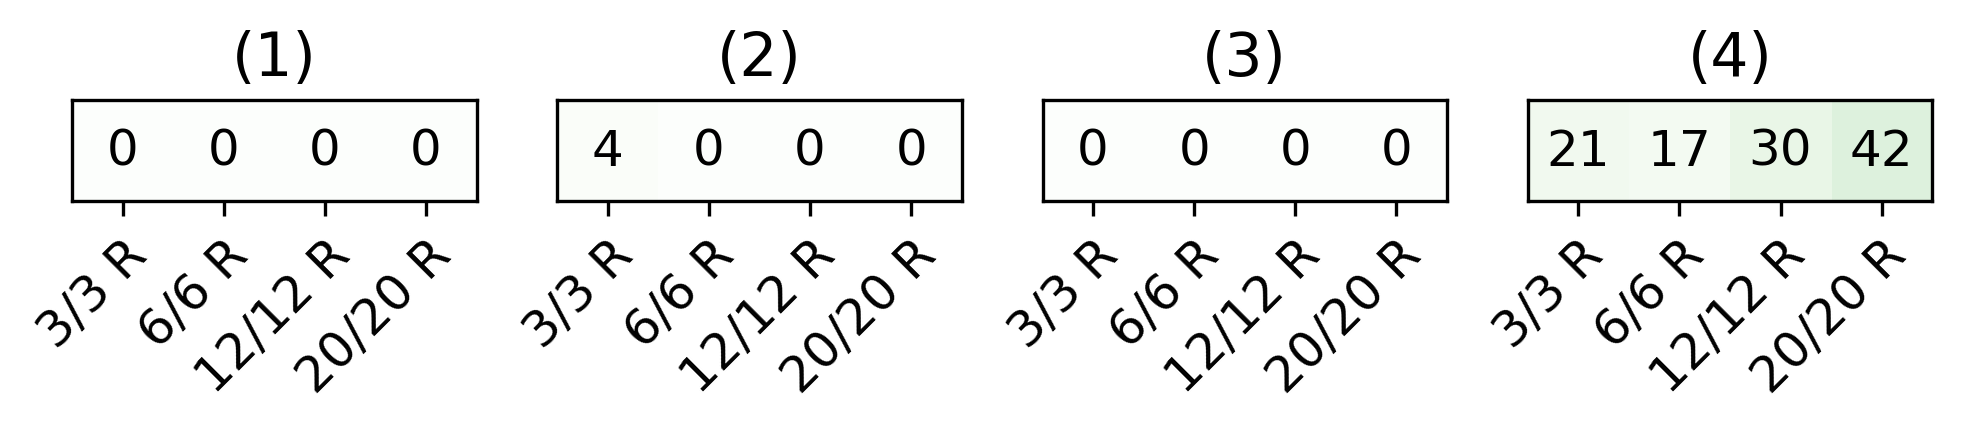

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
4511,YLR329W,30,49,62,88,64,104,48,34,53,...,29,85,56,43,52,27,71,44,86,51


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
4511,YLR329W,112,65,71,104,52,114,62,73,50,...,111,65,73,47,70,120,59,56,105,57


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
4511,YLR329W,7.20385,0.306775,-196.805858,False,-205.931345,False


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


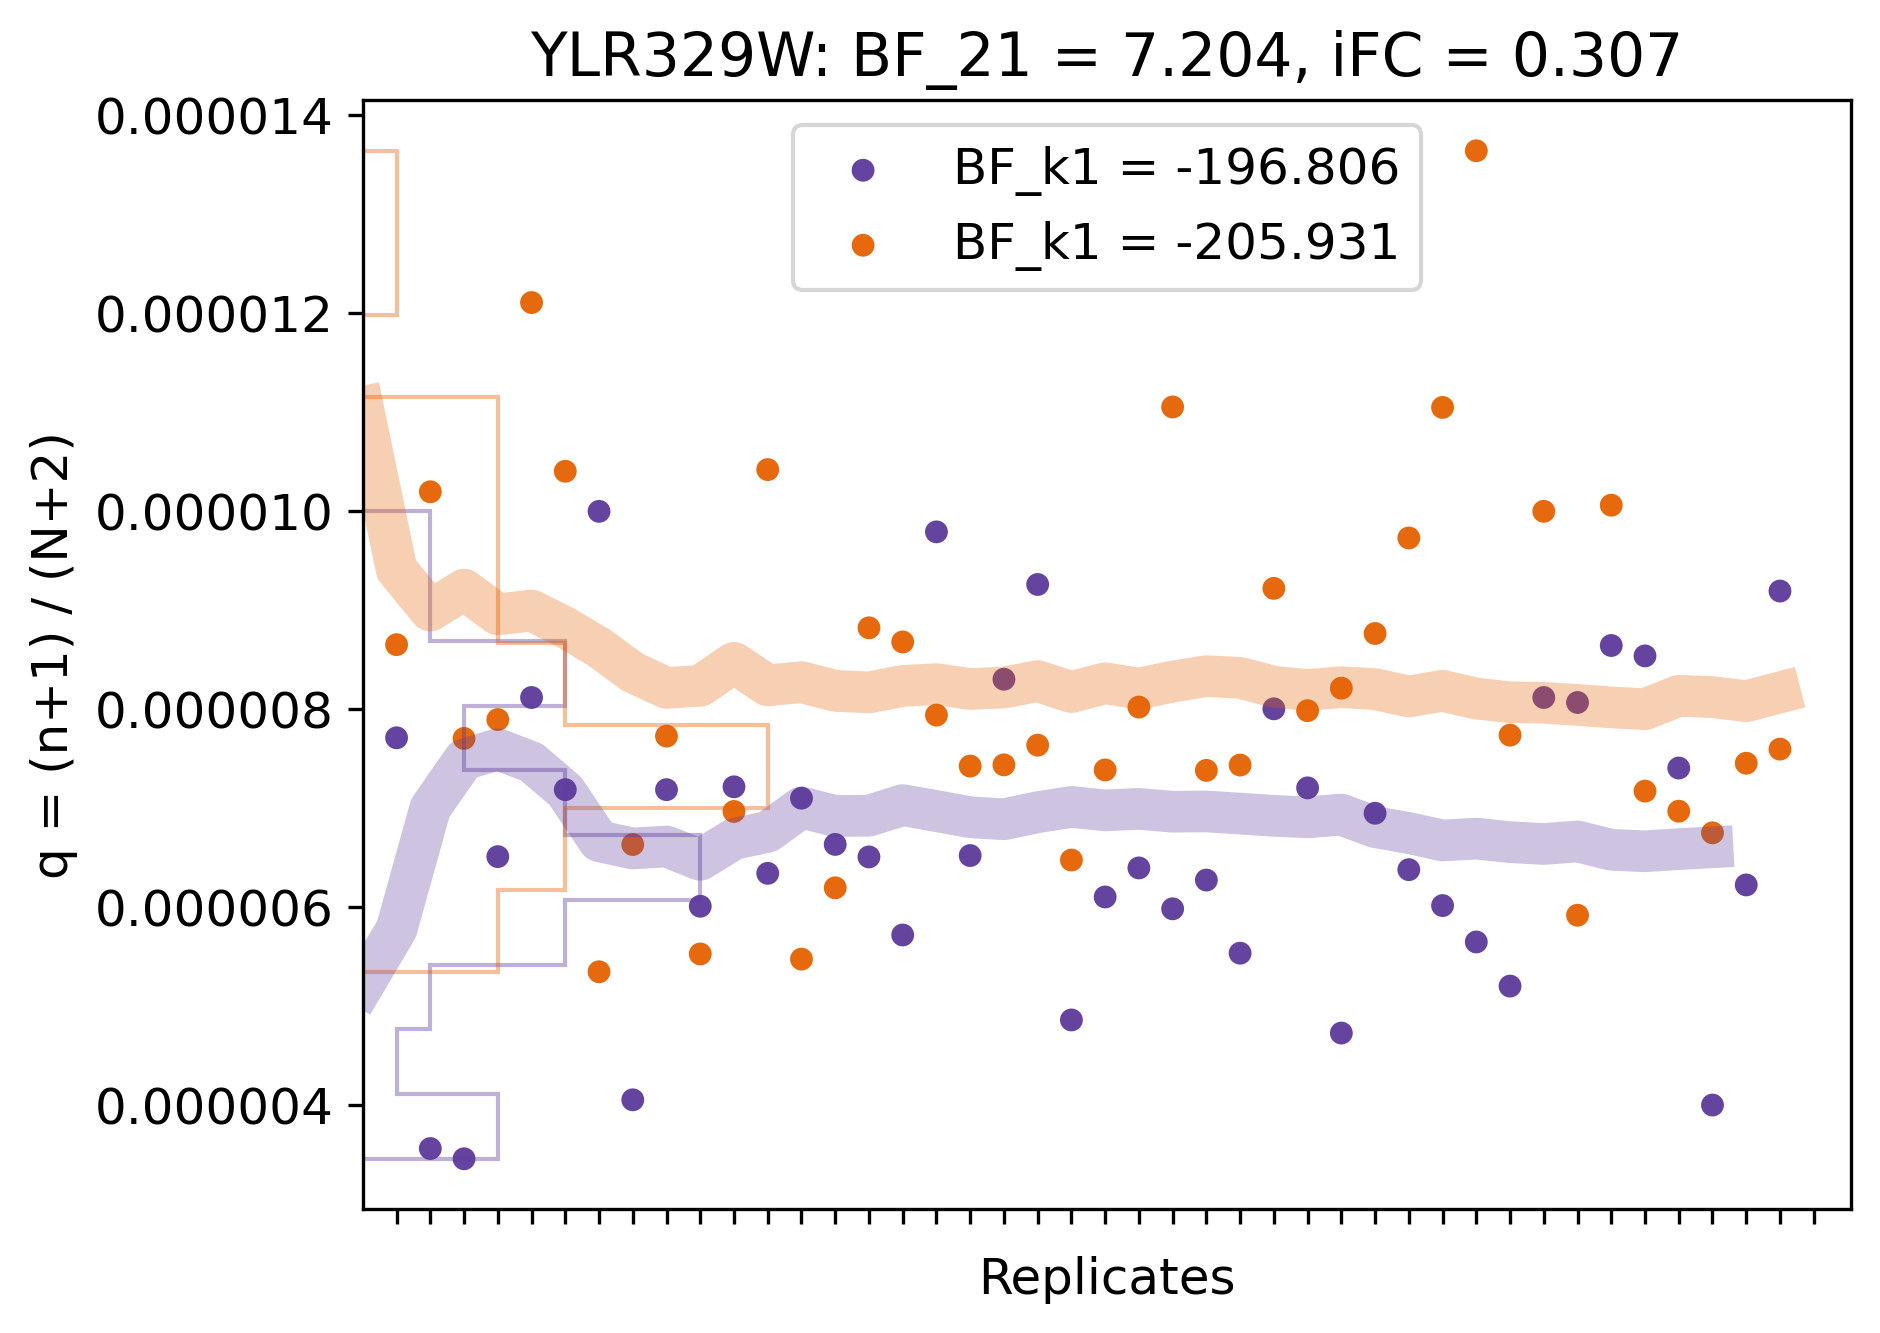

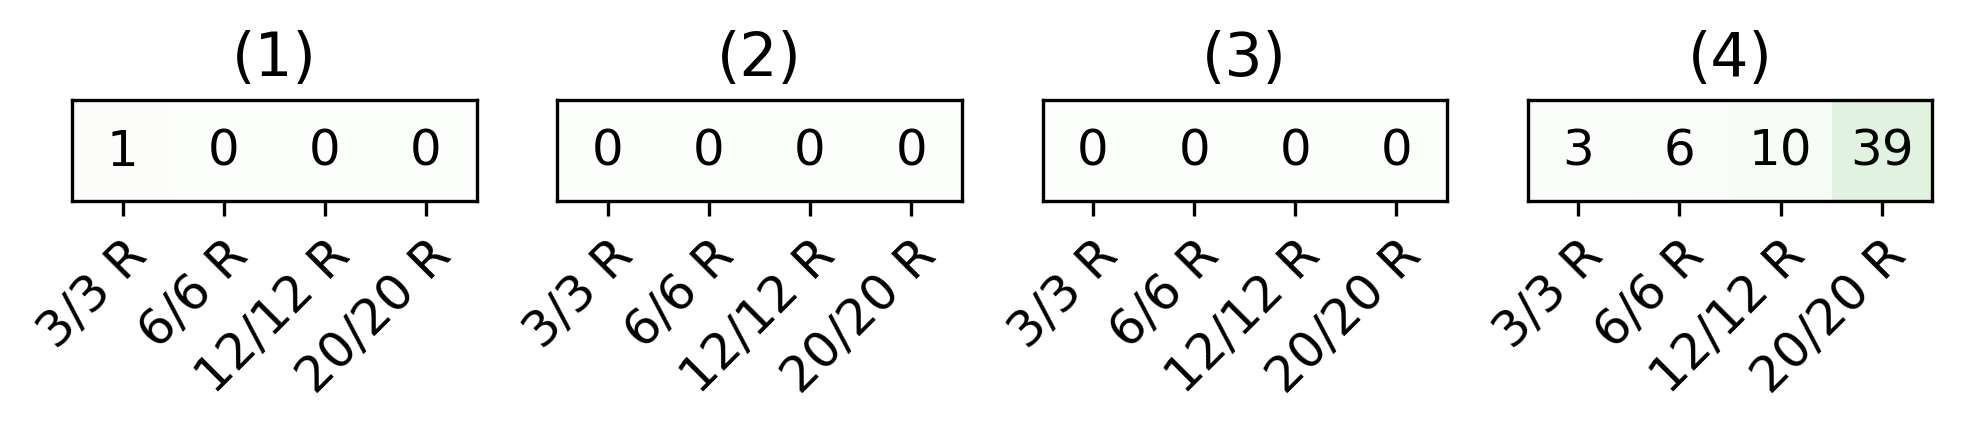

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
1409,YDR291W,268,443,315,477,451,956,473,409,458,...,337,586,516,380,261,323,603,288,659,359


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
1409,YDR291W,630,488,538,663,399,753,410,564,461,...,816,434,496,391,453,477,425,570,524,405


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
1409,YDR291W,7.219764,0.111894,-95.144699,False,-163.157529,False


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


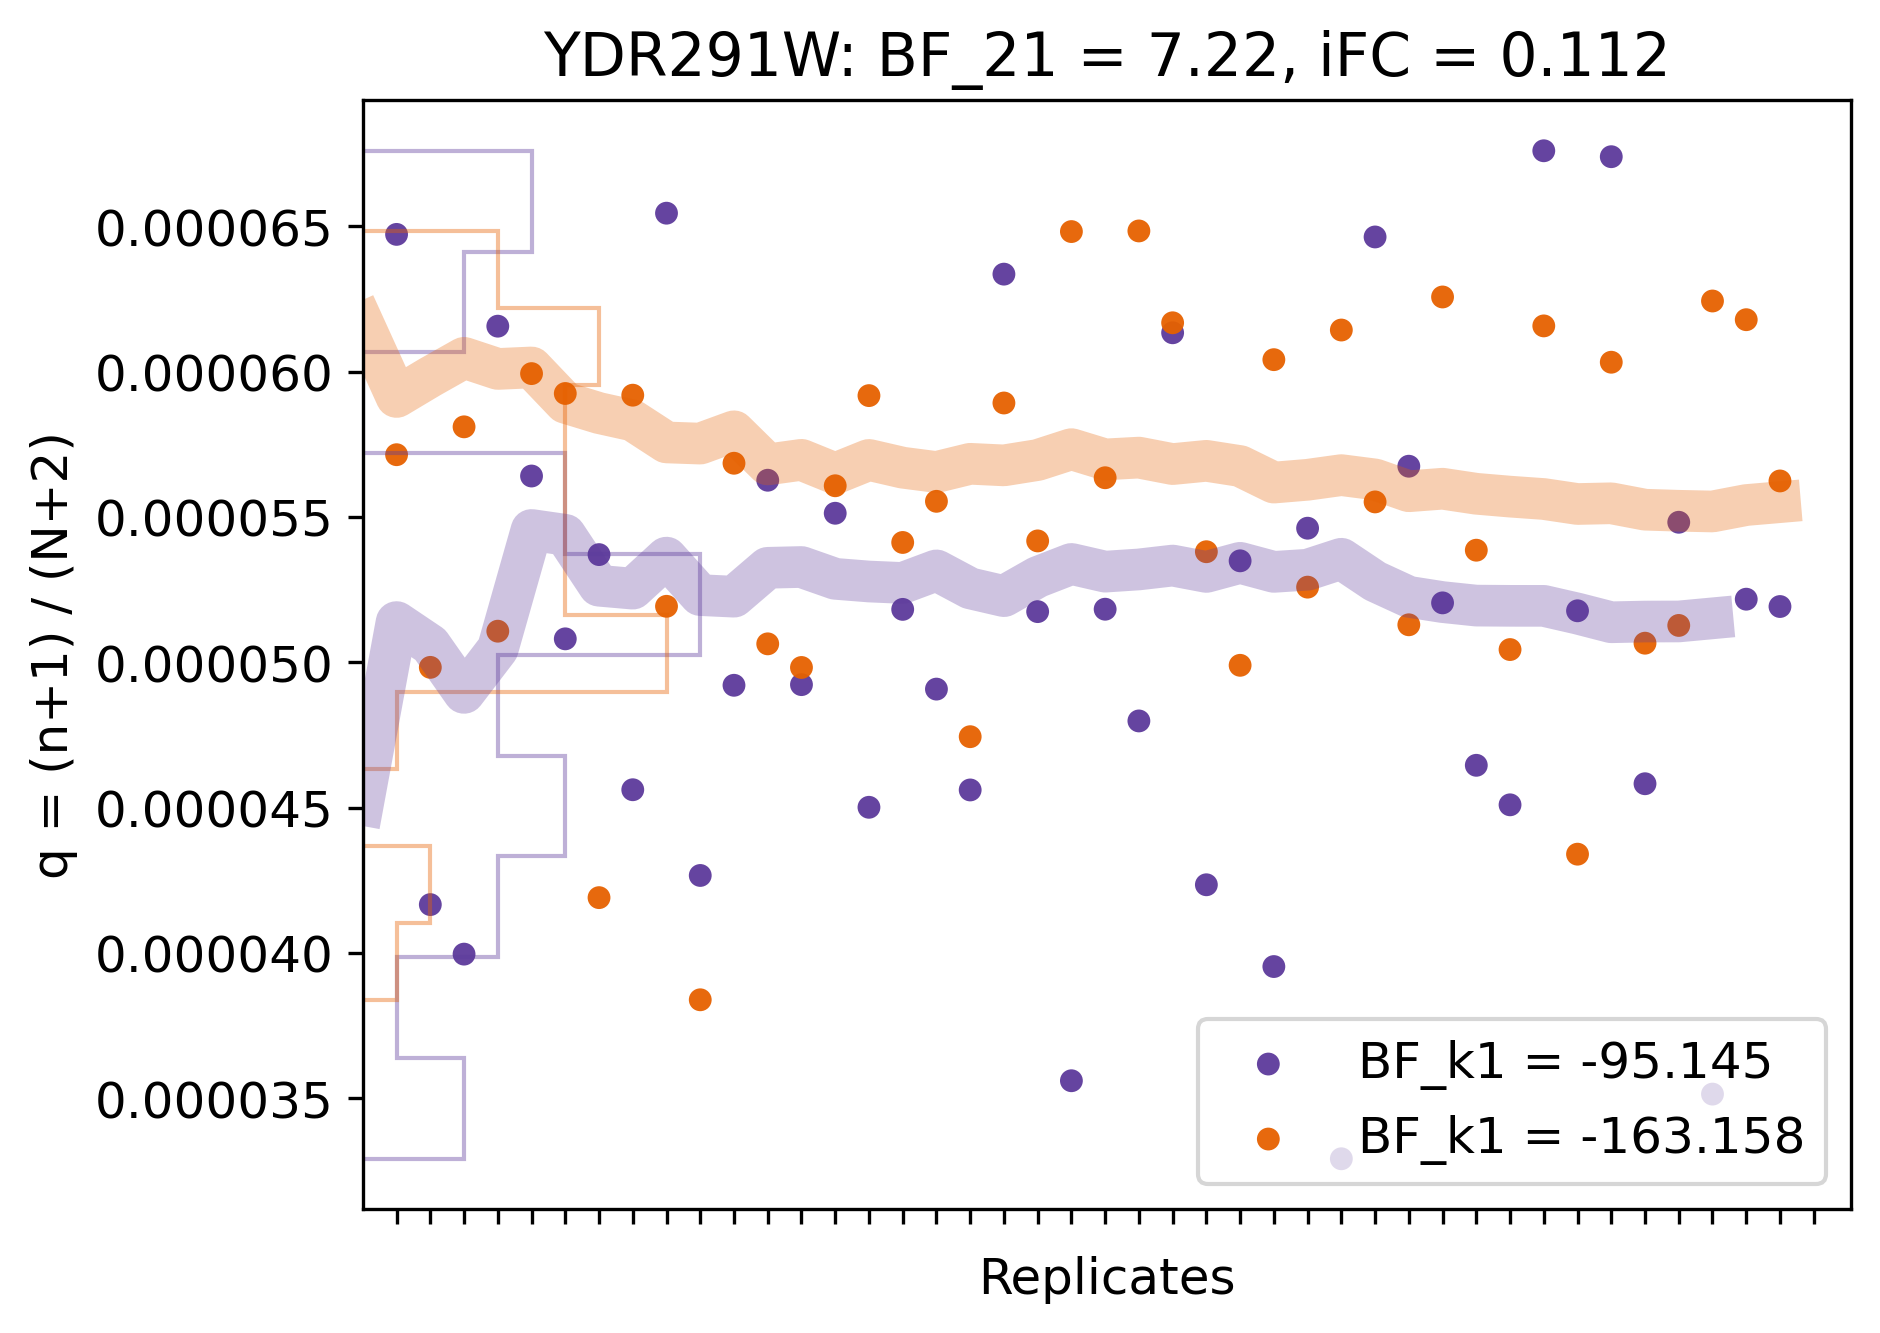

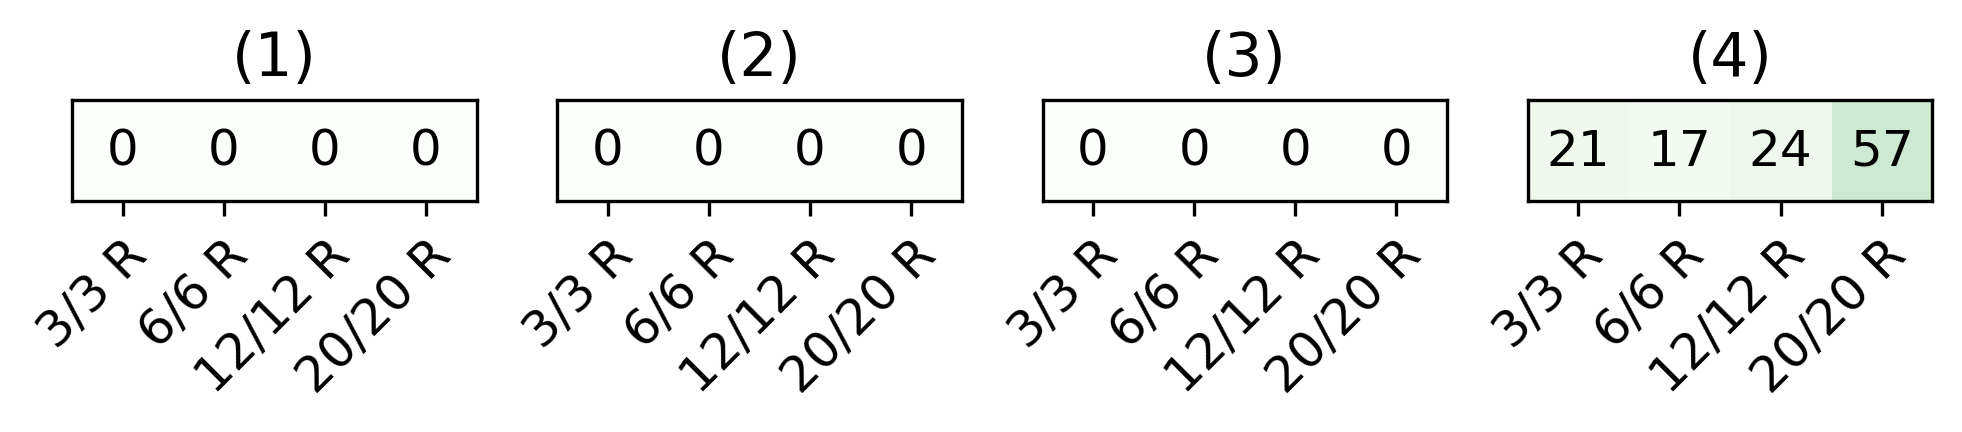

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
6701,YPR164W,247,418,292,425,408,879,456,432,388,...,340,552,482,383,270,328,621,267,613,363


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
6701,YPR164W,512,478,462,545,356,682,411,539,417,...,805,403,470,379,478,459,388,485,420,389


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
6701,YPR164W,7.242236,0.115596,-129.747251,False,-198.587507,False


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


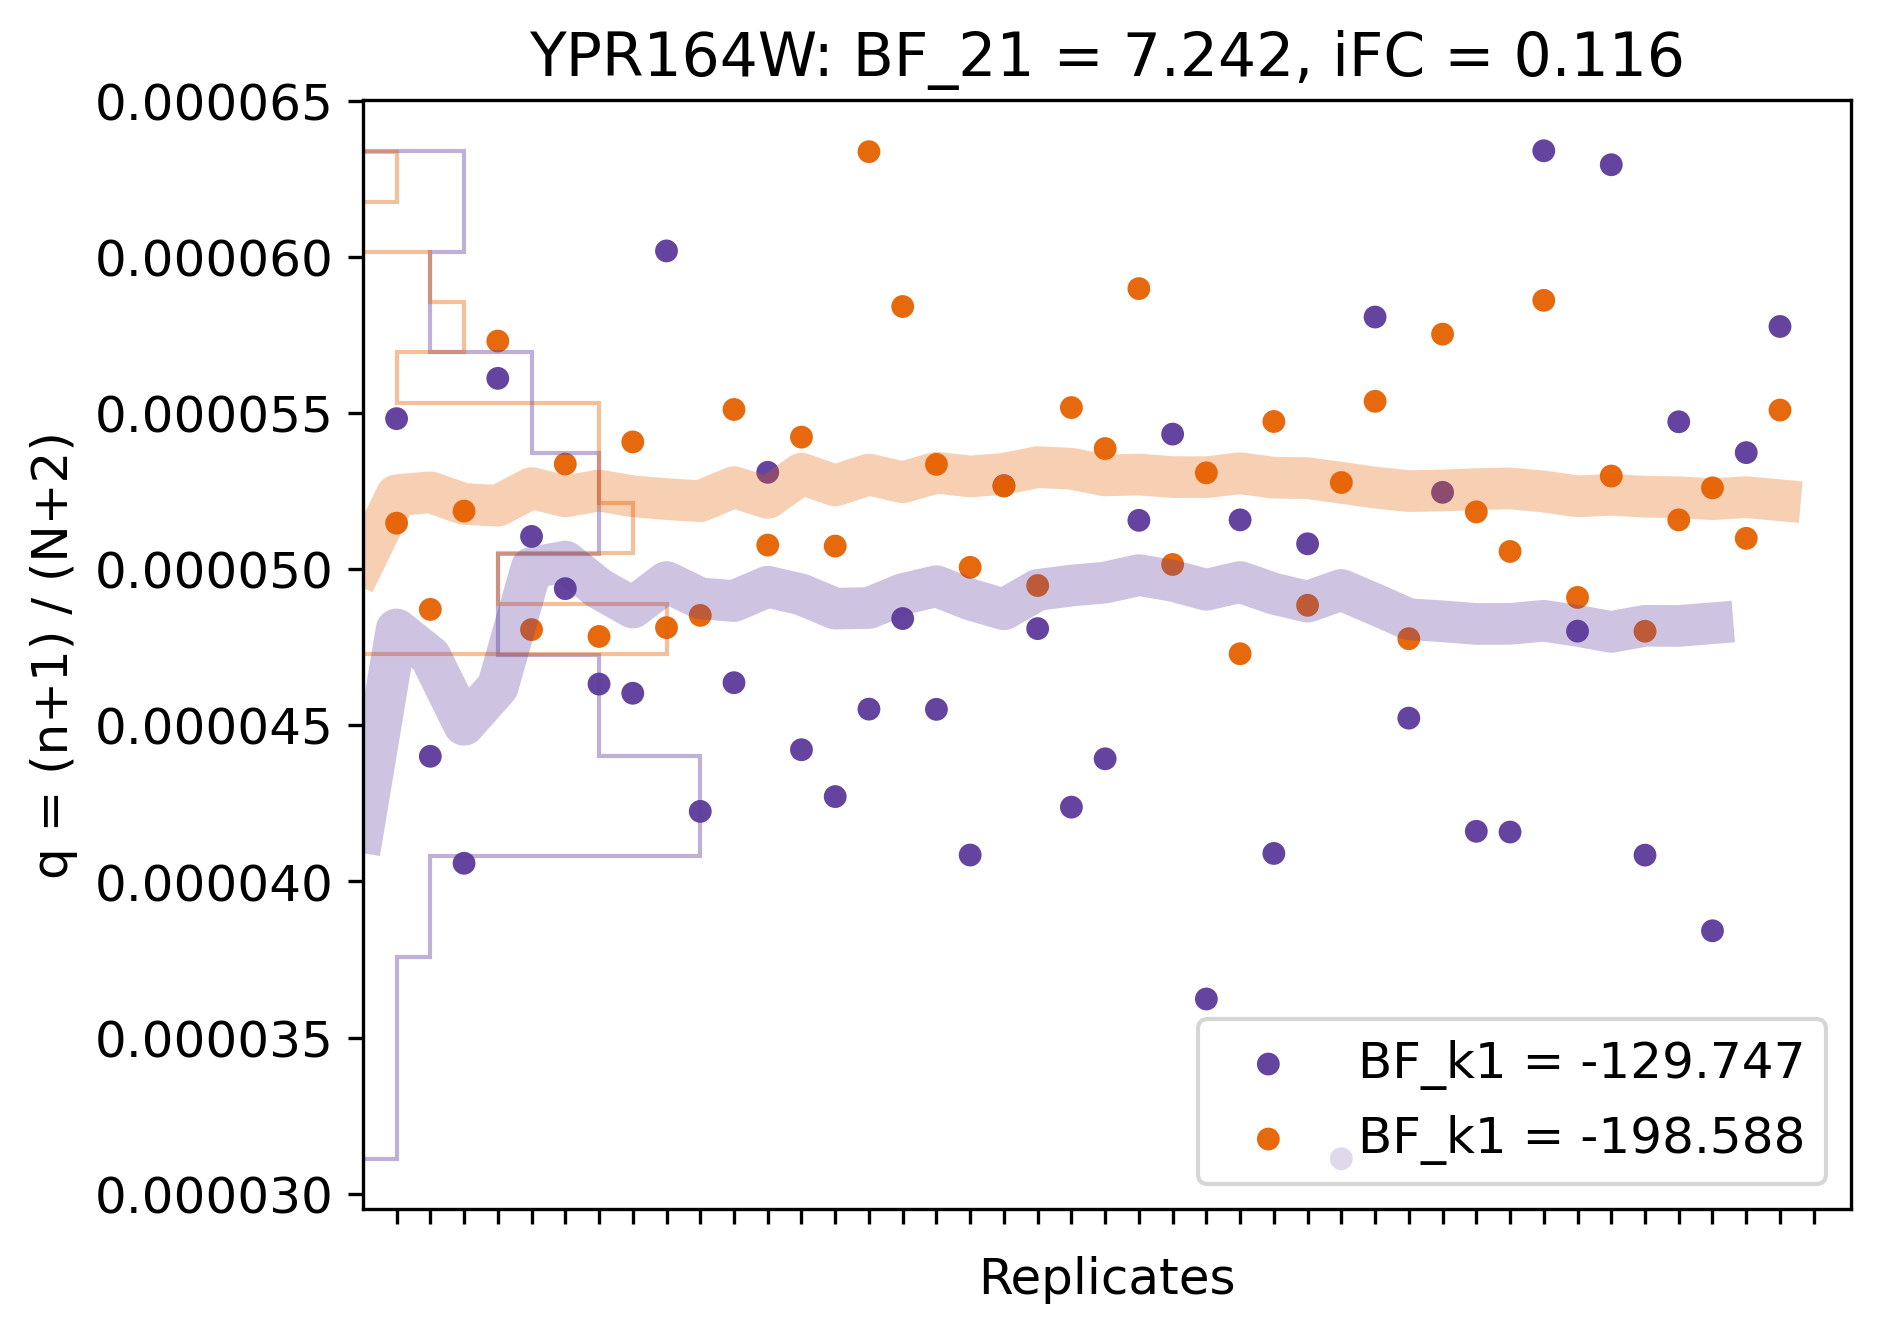

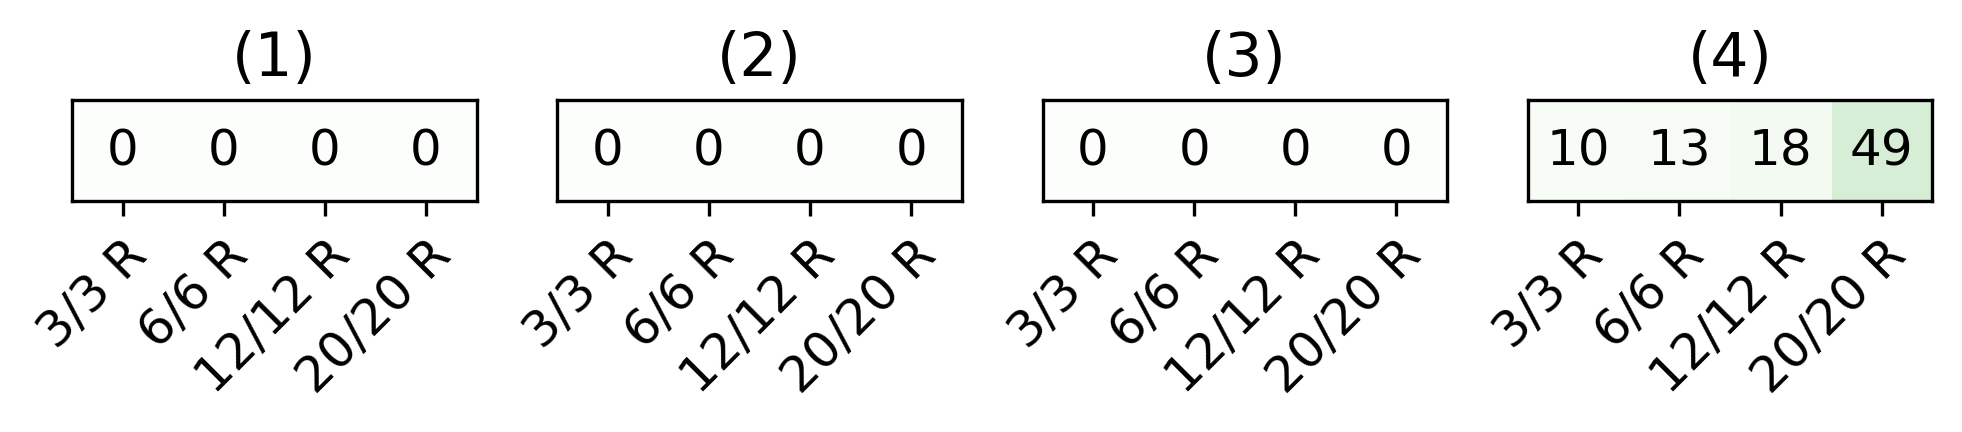

[None, None, None, None]

In [61]:
[stalk([gene]) for gene in ['YNL232W', 'YLR329W', 'YDR291W', 'YPR164W']]

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
6763,snR32,22,65,37,32,60,81,32,21,59,...,23,50,64,38,18,14,38,36,65,27


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
6763,snR32,37,35,29,60,49,35,24,39,42,...,70,33,35,21,63,50,32,38,43,40


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
6763,snR32,-5.400319,-0.10677,-173.267945,False,-199.190675,False


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


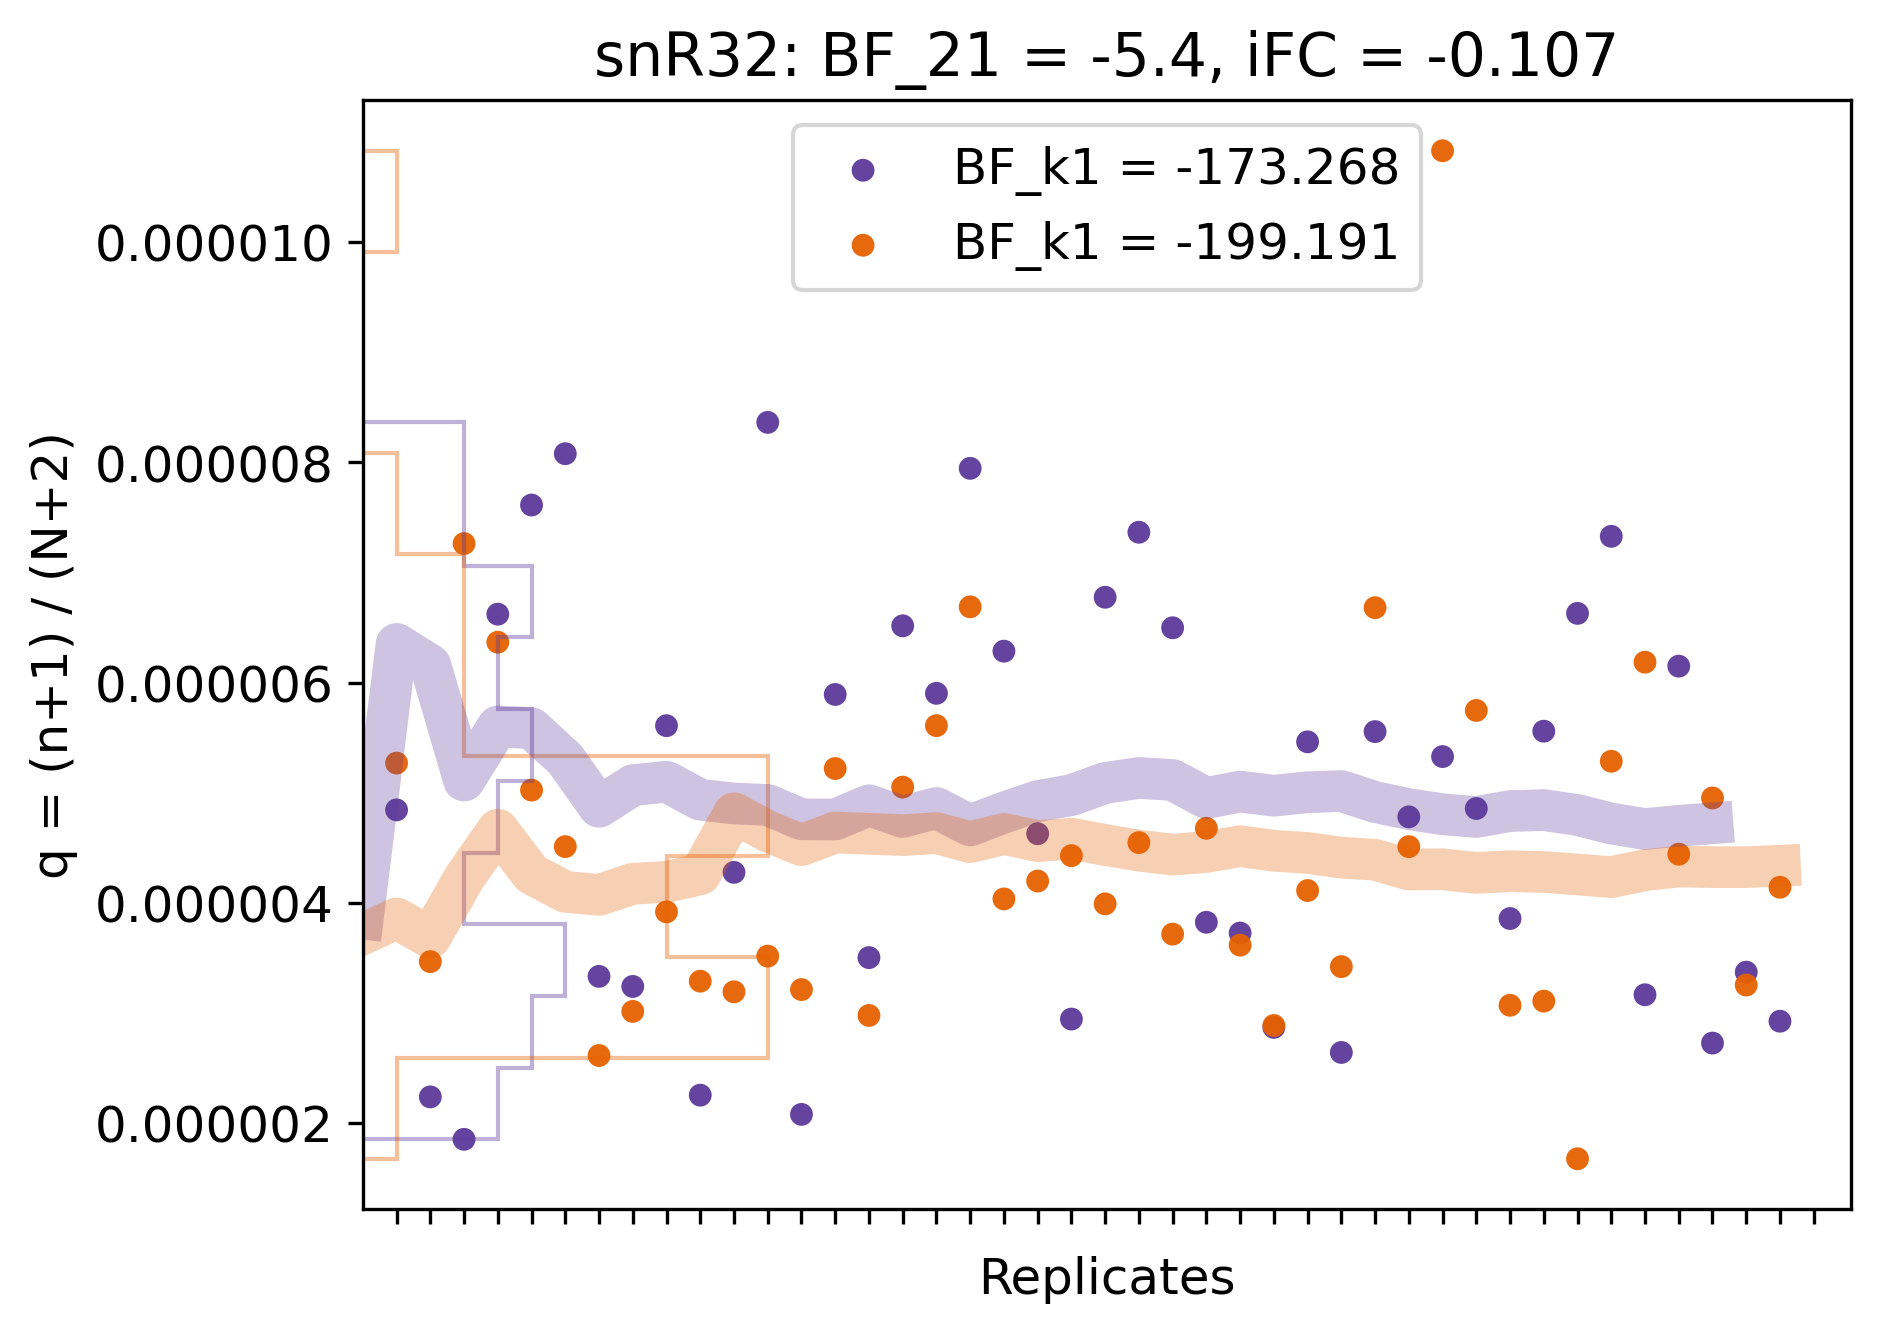

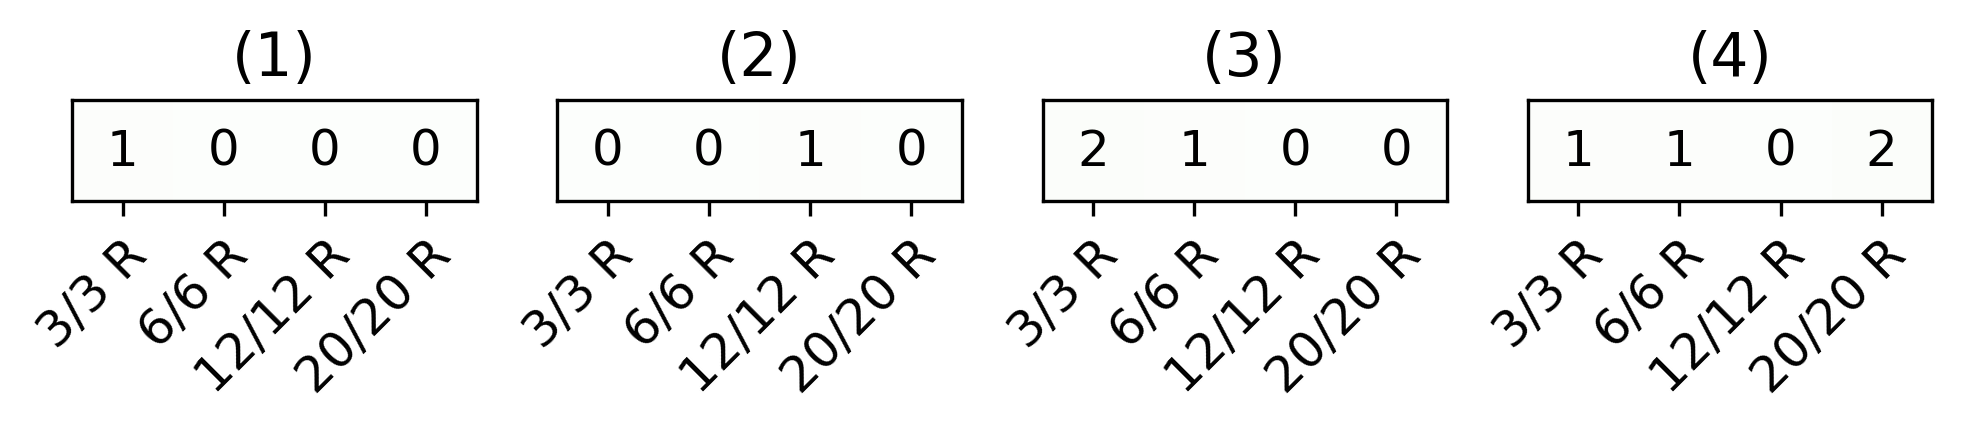

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
6255,YPL032C,775,1330,978,1470,1316,2684,1284,1254,1236,...,1030,1656,1729,1157,903,872,1773,747,1894,1122


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
6255,YPL032C,1643,1301,1153,1612,987,2242,1161,1532,860,...,2383,1350,1488,978,1419,1514,1069,1348,1511,1103


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
6255,YPL032C,-5.39359,0.009353,15.238002,True,-61.994904,False


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


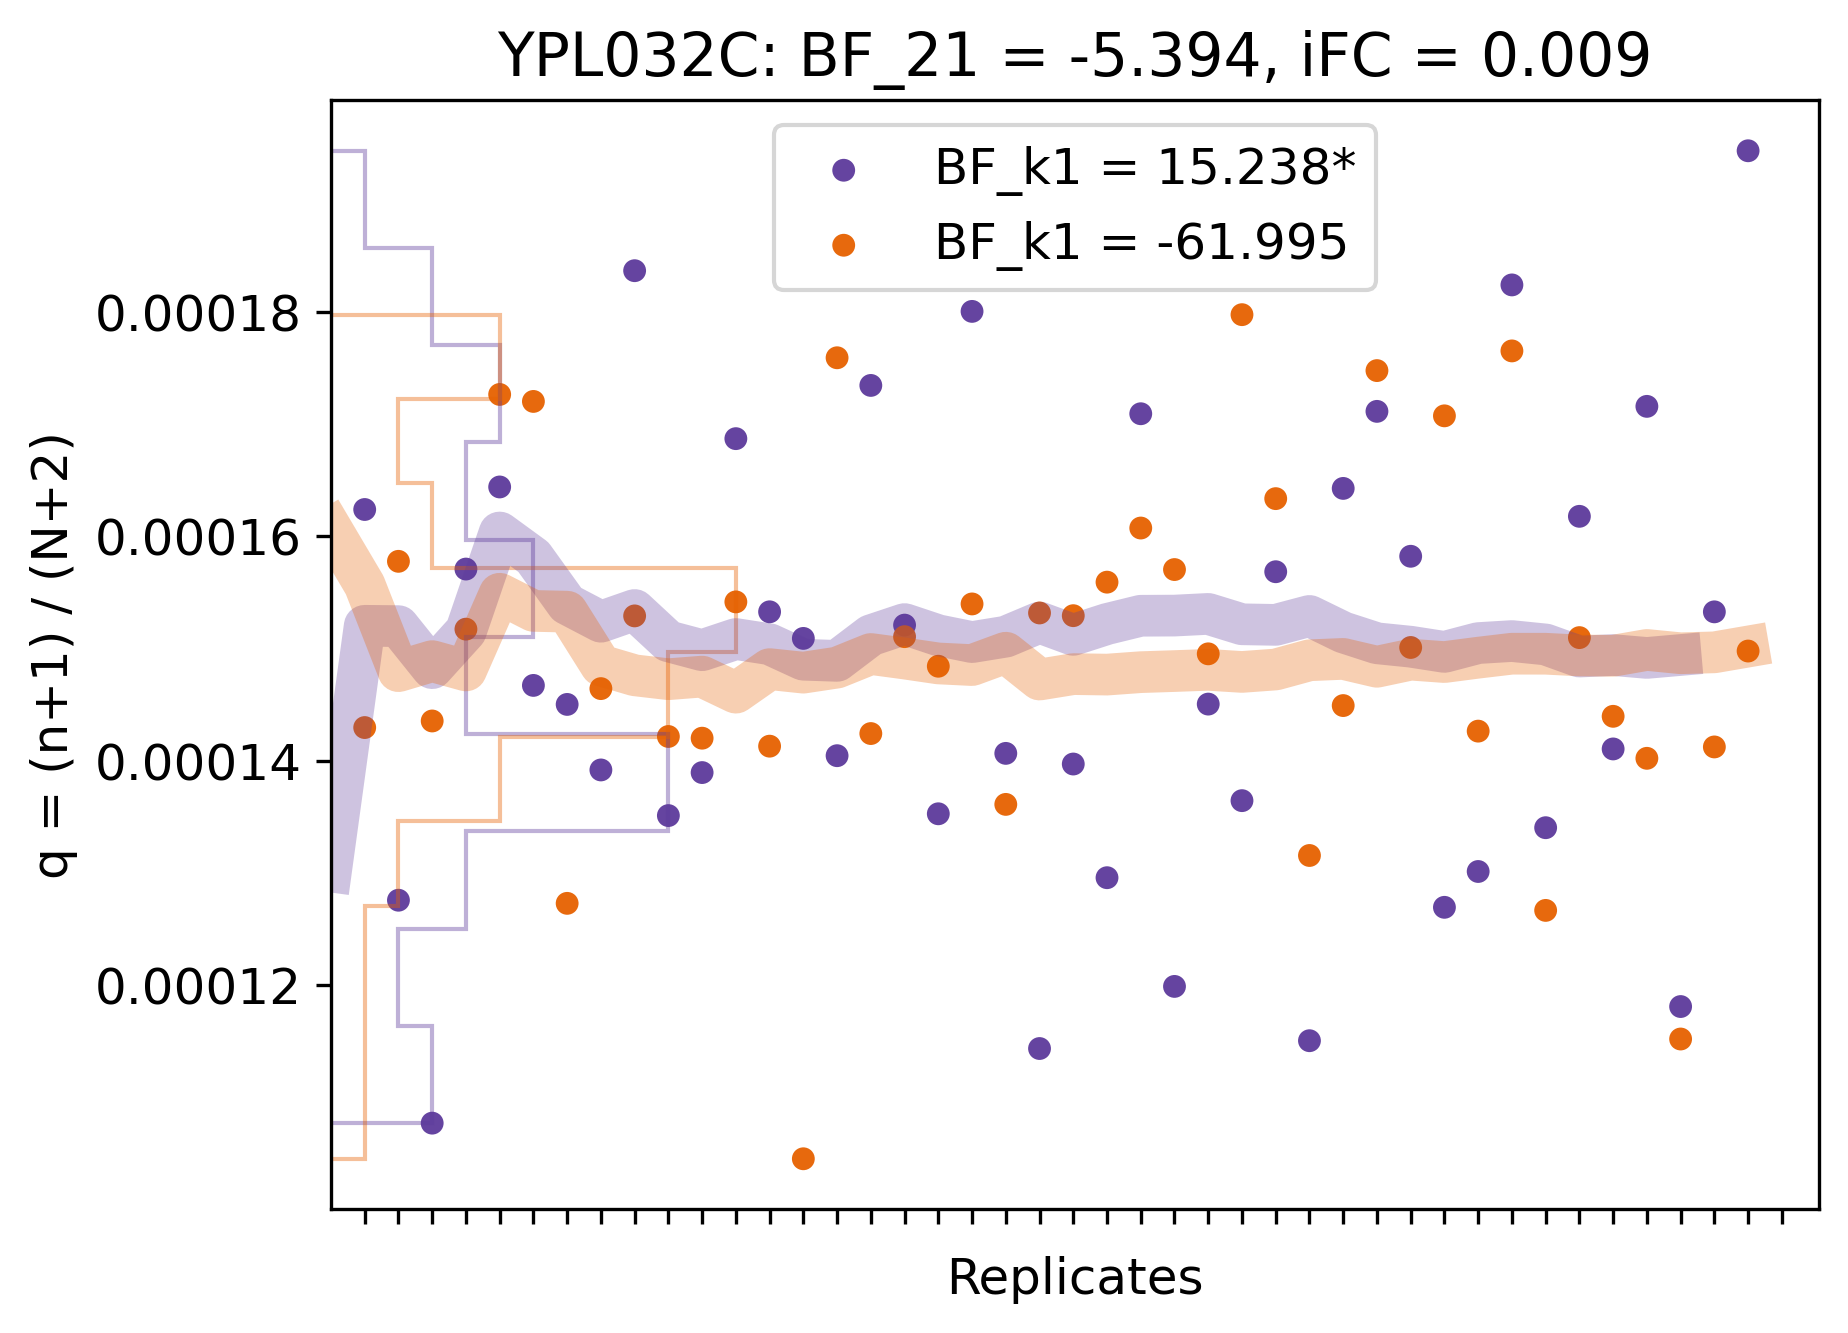

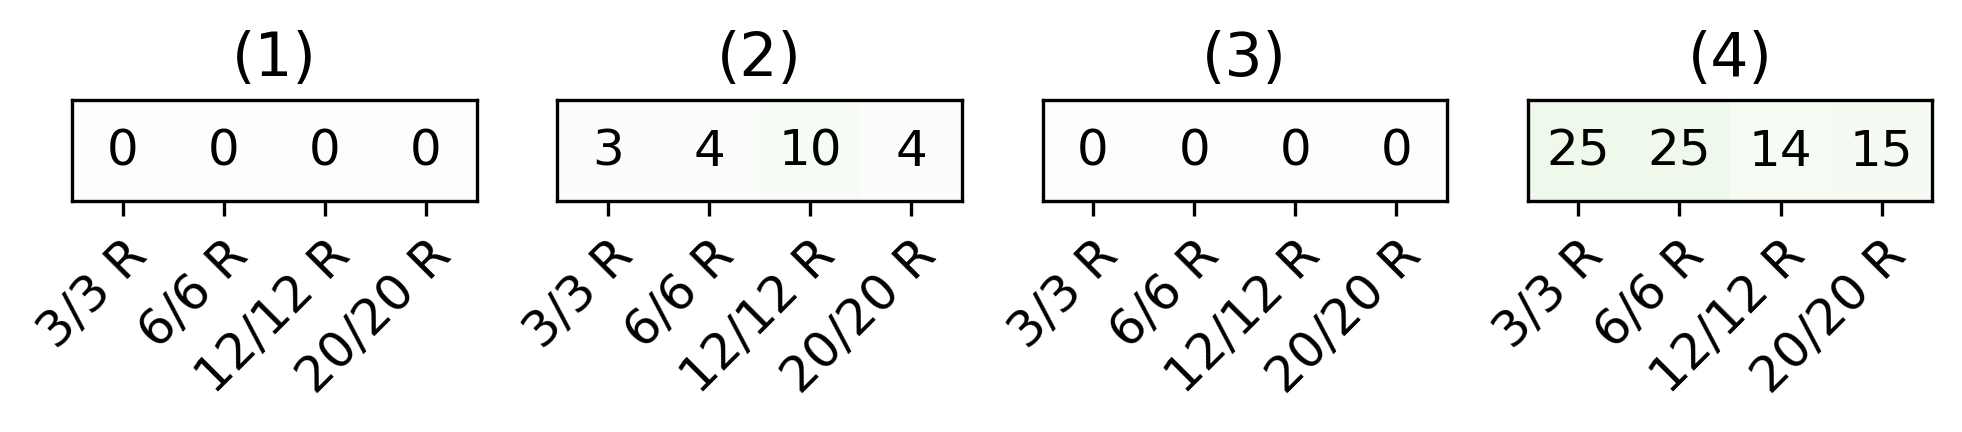

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
5212,YNL034W,14,42,33,30,31,78,39,37,35,...,18,51,35,25,29,29,43,22,43,34


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
5212,YNL034W,25,34,26,50,25,47,31,29,26,...,50,34,40,21,35,33,16,27,34,24


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
5212,YNL034W,-5.392332,-0.122325,-220.383309,False,-234.900049,False


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


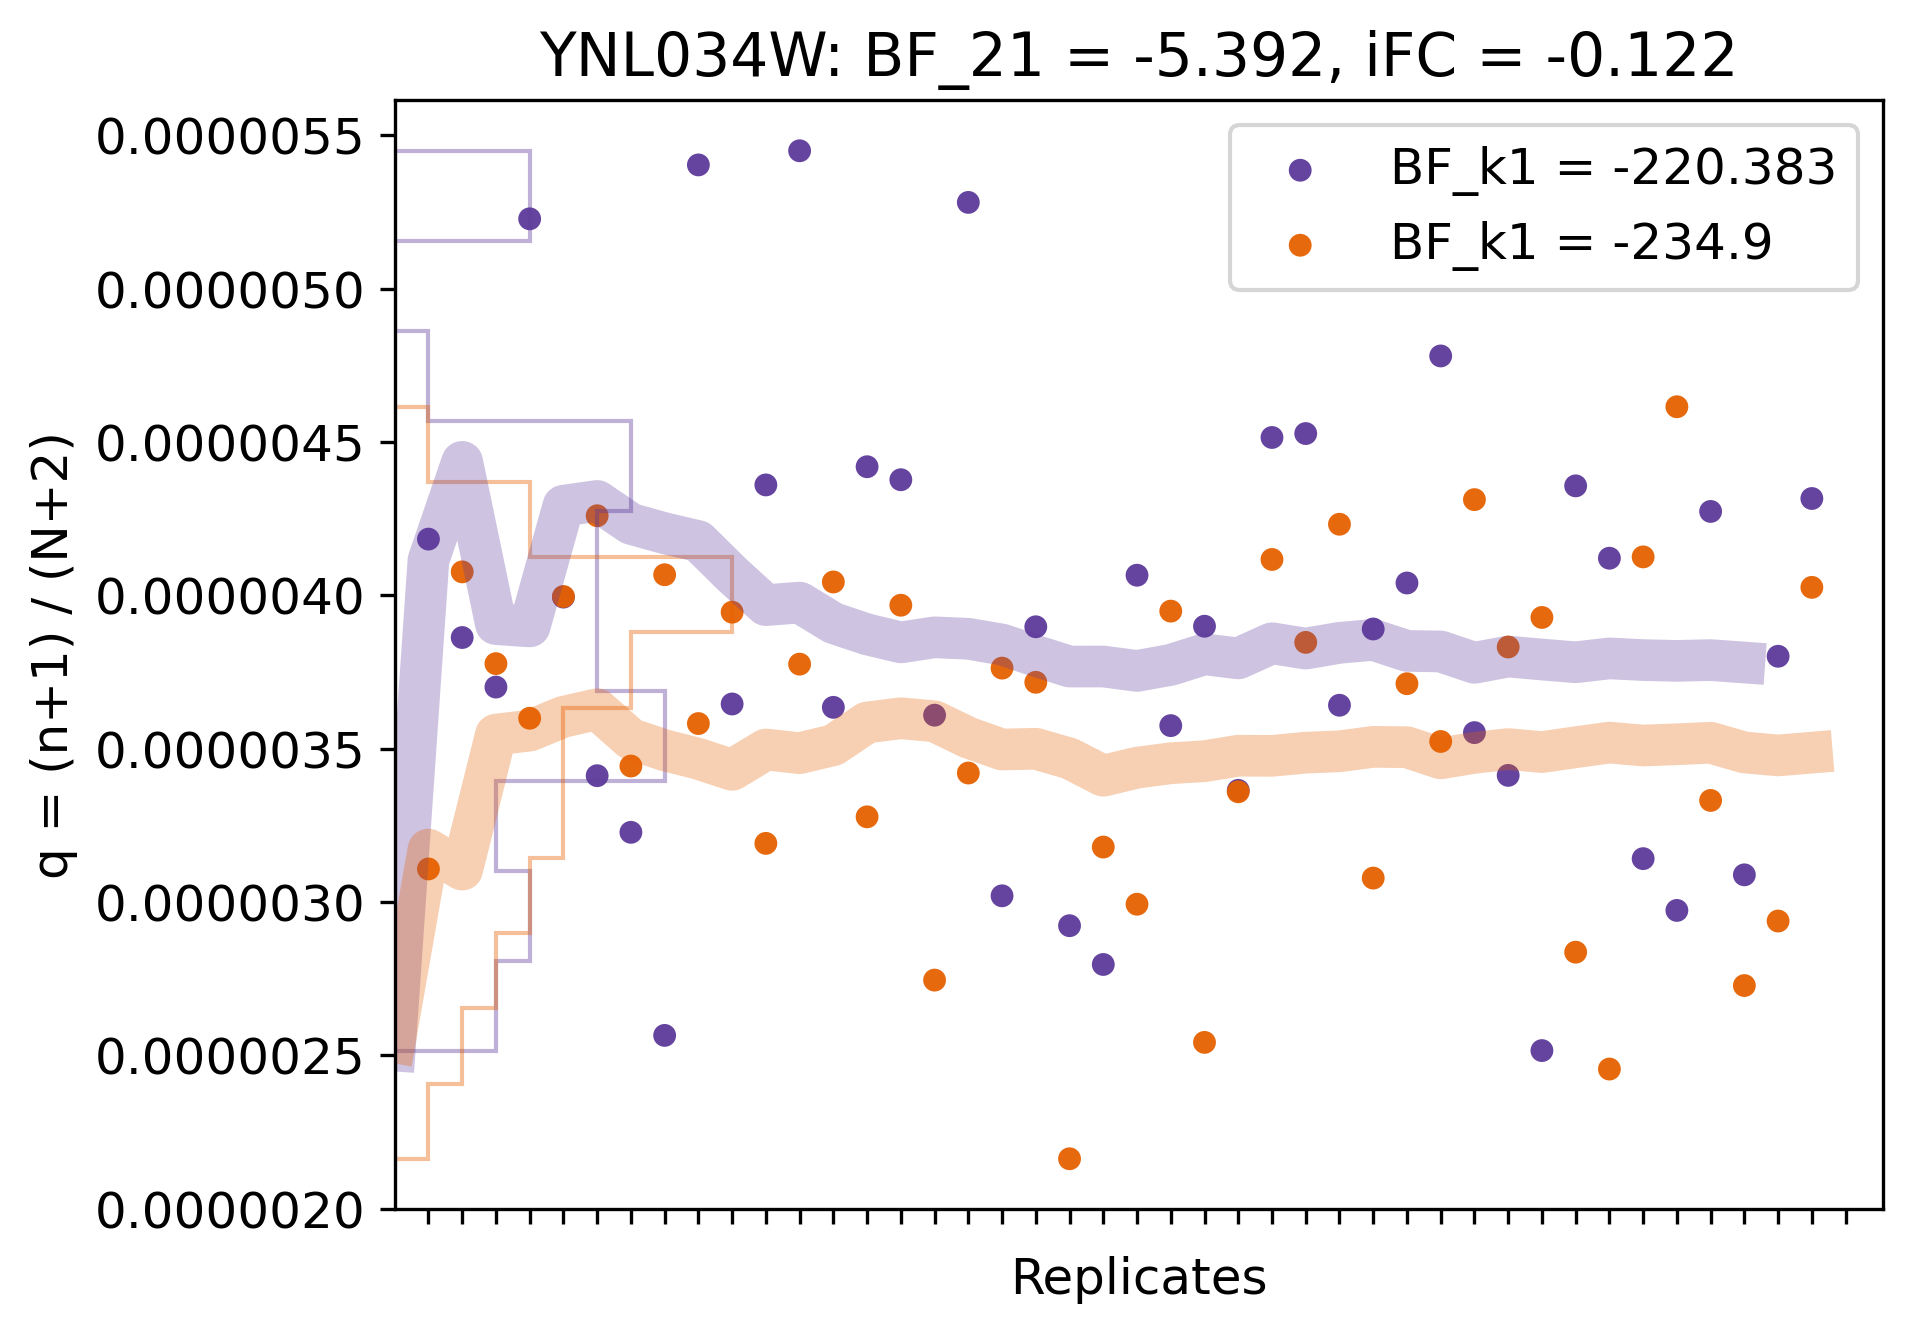

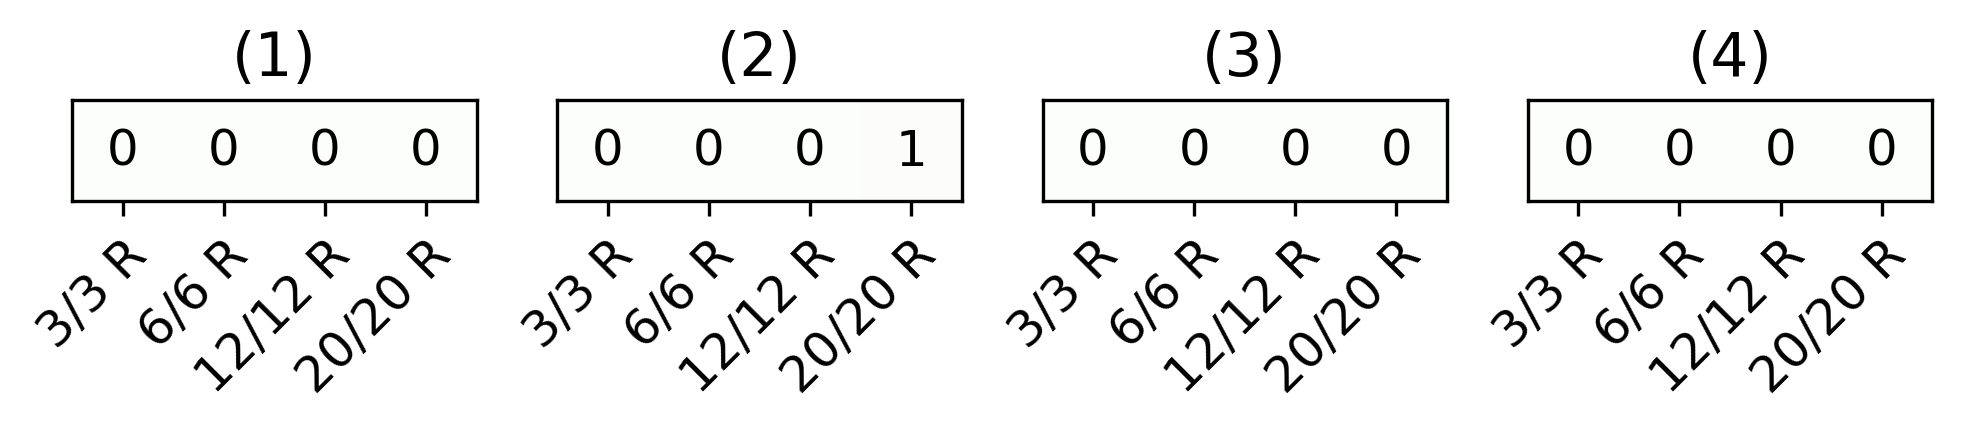

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
6253,YPL030W,184,384,235,283,457,801,364,255,270,...,281,297,466,244,200,184,570,174,515,212


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
6253,YPL030W,380,282,308,347,236,484,306,381,327,...,561,312,324,275,302,377,320,387,398,352


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
6253,YPL030W,-5.389092,0.027465,46.700324,True,-174.514572,False


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


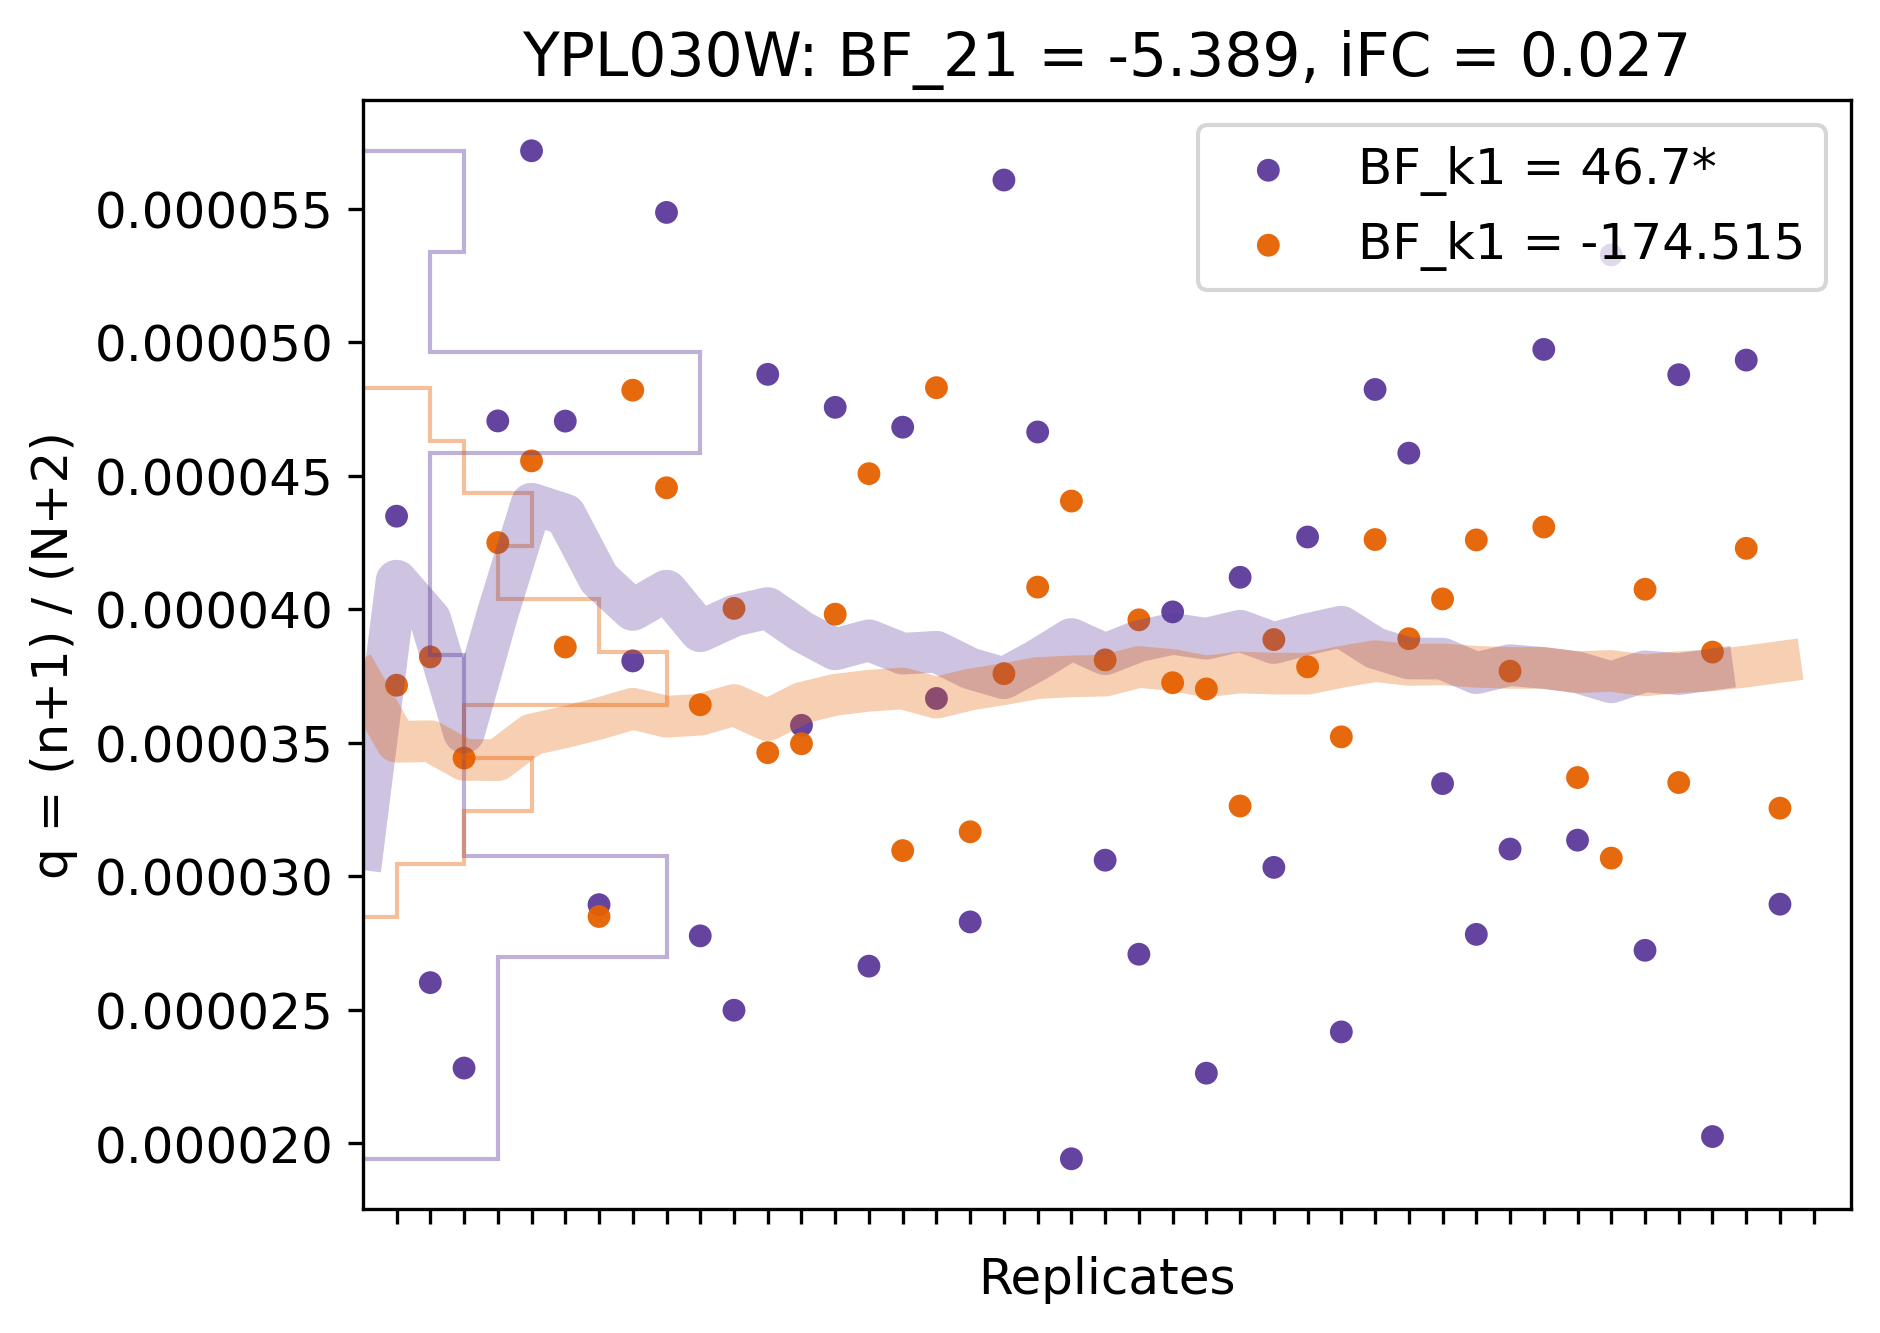

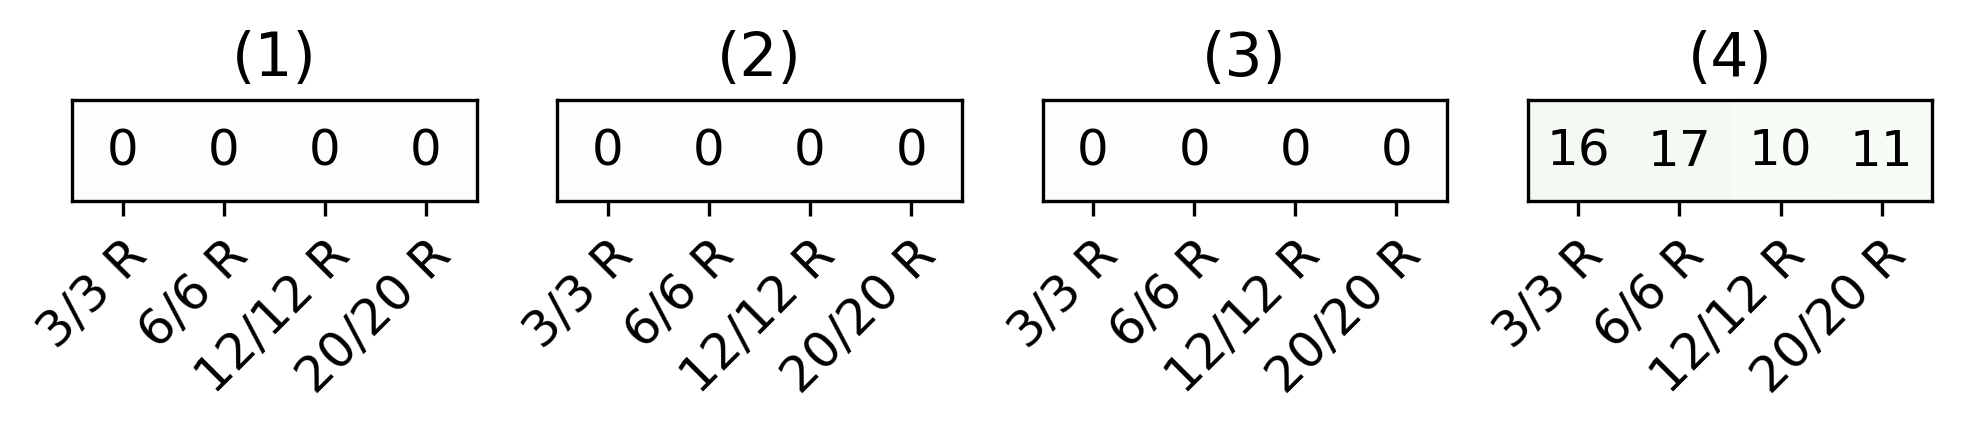

[None, None, None, None]

In [62]:
[stalk([gene]) for gene in ['snR32', 'YPL032C', 'YNL034W', 'YPL030W']]

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
4,LSR1,60,163,233,163,193,375,194,84,211,...,66,385,232,149,114,81,109,132,243,128


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
4,LSR1,210,103,159,260,298,303,96,132,263,...,250,195,153,57,742,227,227,117,224,136


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
4,LSR1,0.451012,0.120243,251.787125,True,478.066414,True


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


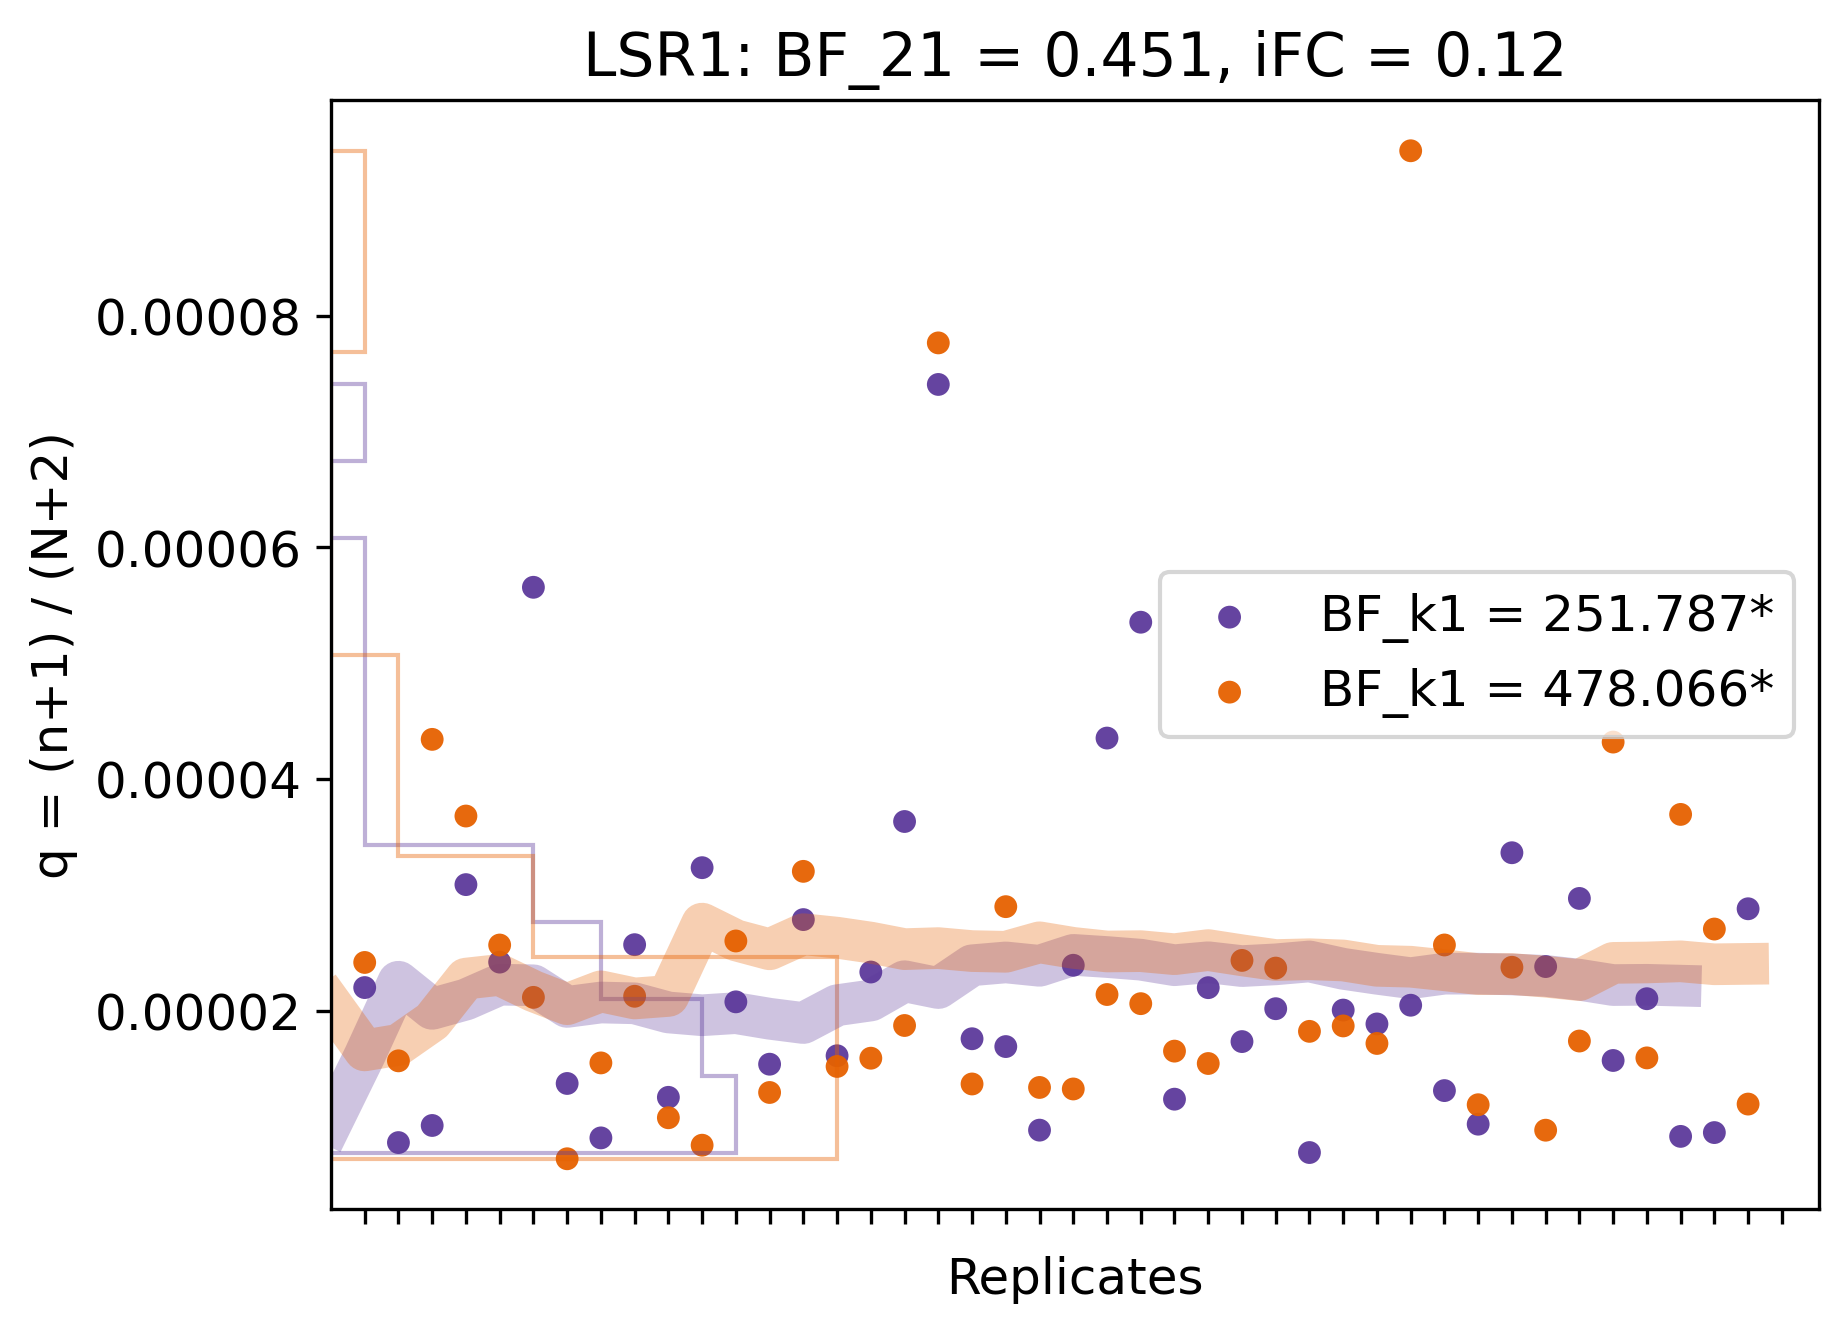

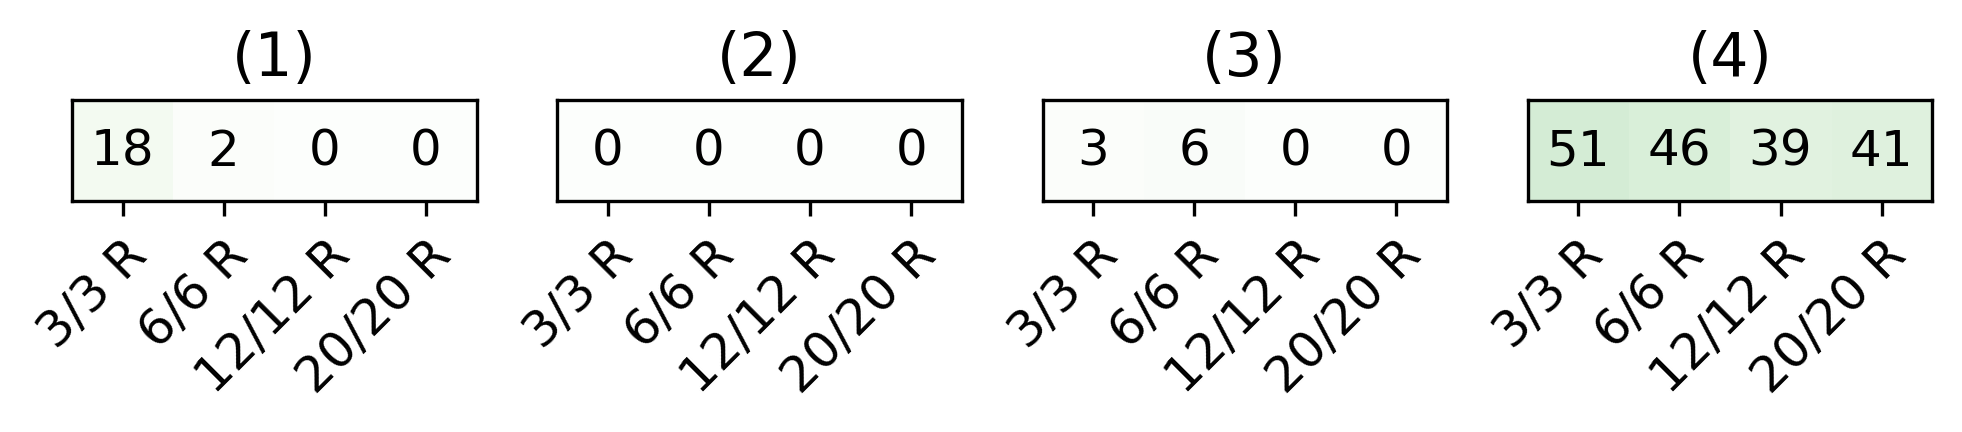

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
4118,YLL039C,2871,2292,3125,5119,1856,3819,2731,4535,2751,...,2505,6020,2577,3350,3851,3740,3142,2683,3485,3700


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
4118,YLL039C,4854,4618,4216,5444,3416,5893,3748,4813,3494,...,6705,3932,4700,3101,4272,3889,3504,4042,3635,3027


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
4118,YLL039C,533.296466,0.257212,2171.972823,True,14.76729,True


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


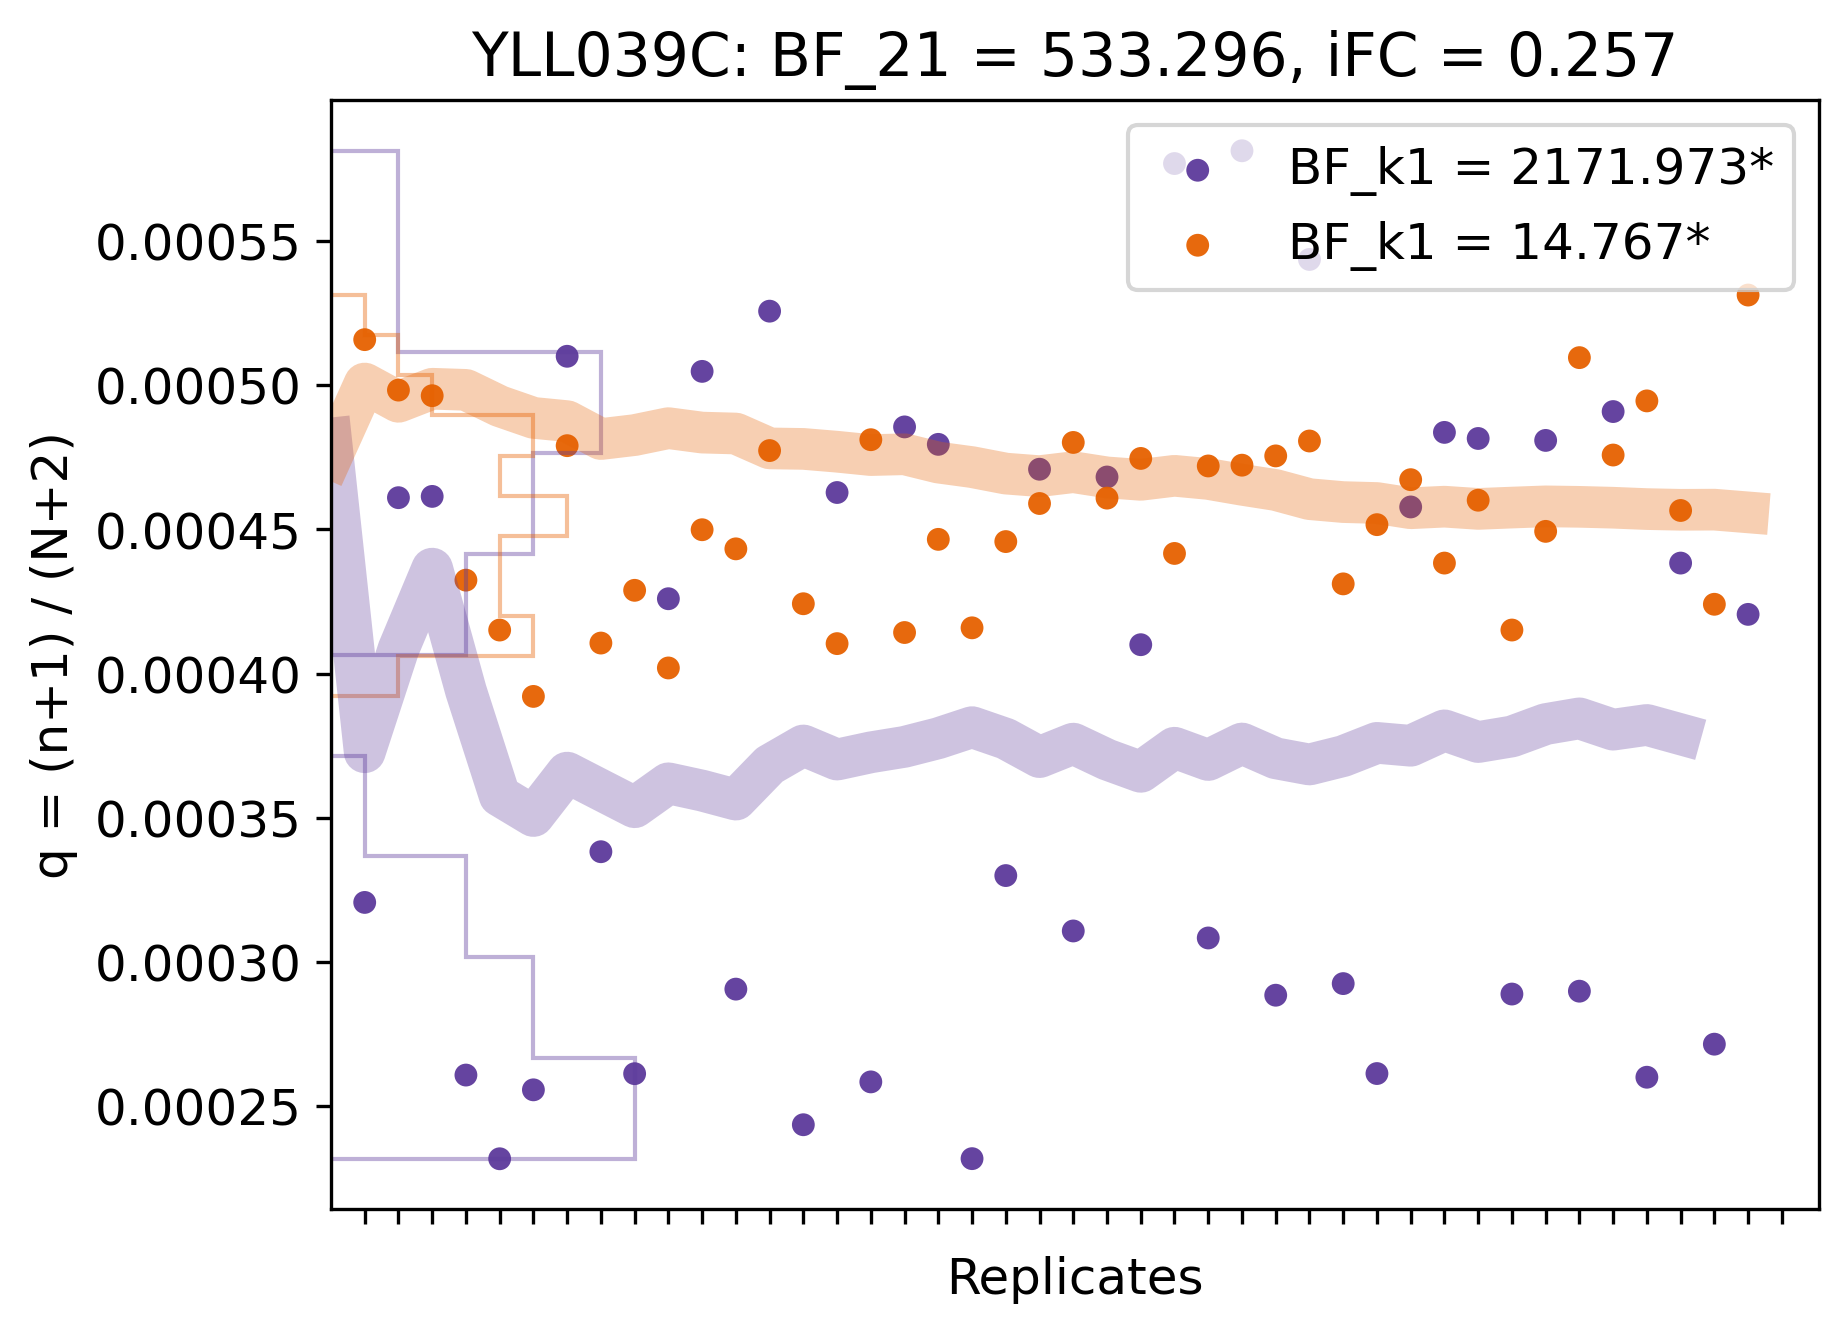

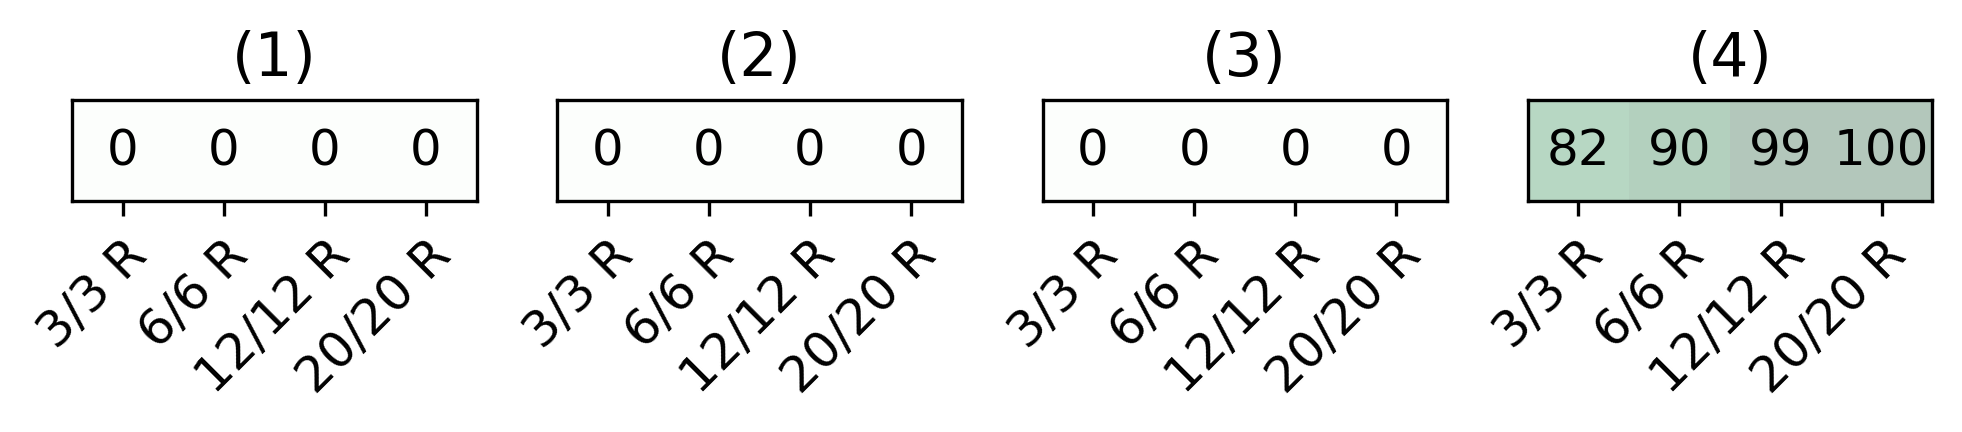

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
3425,YJL098W,191,444,189,274,482,835,377,351,333,...,425,319,600,276,190,276,740,141,675,209


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
3425,YJL098W,422,275,270,406,206,479,388,422,328,...,632,355,483,251,318,441,302,344,430,272


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
3425,YJL098W,1.025525,-0.09119,113.153322,True,-129.167778,False


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


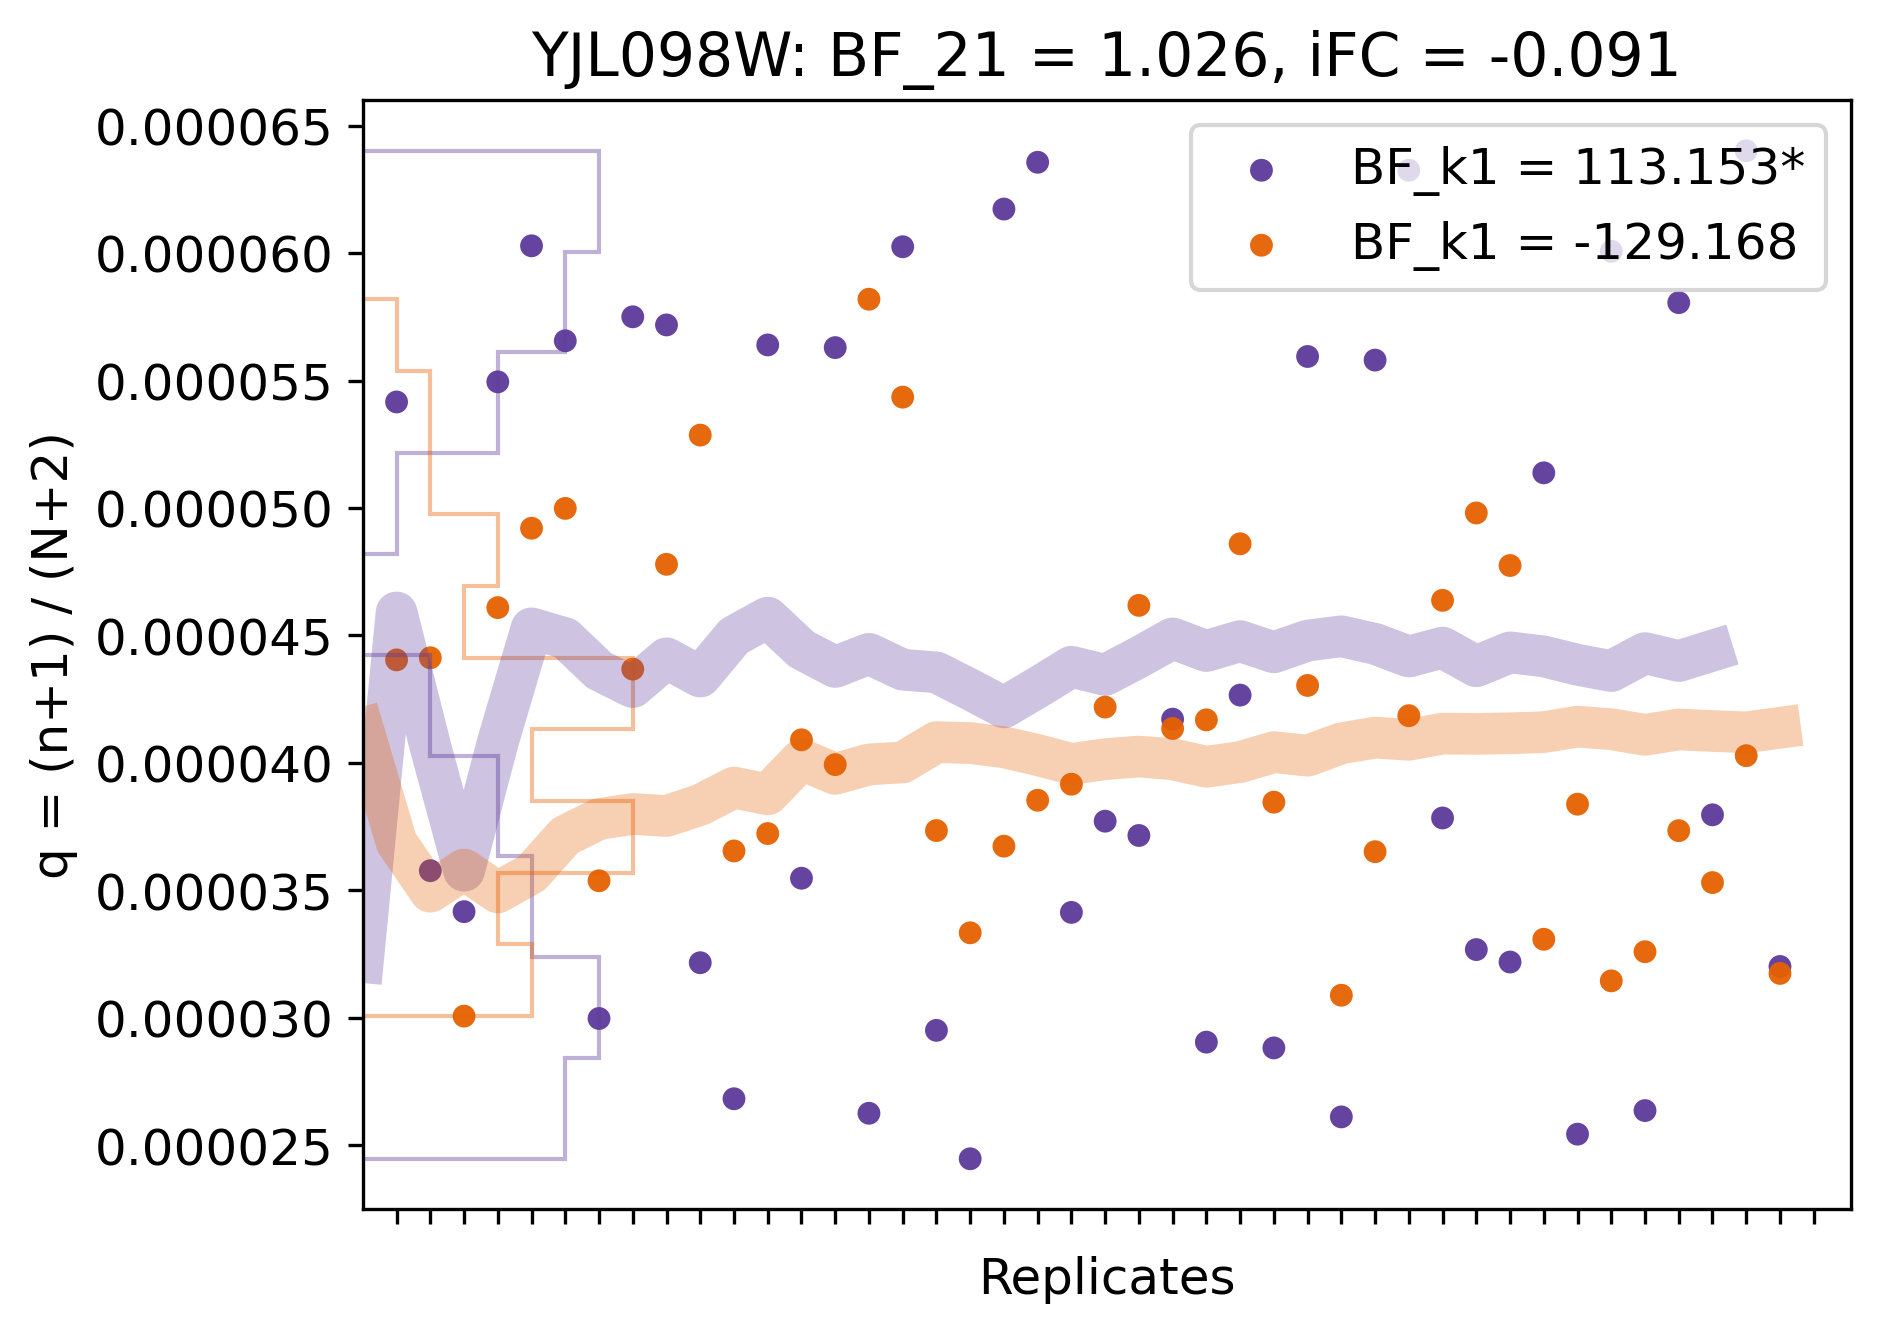

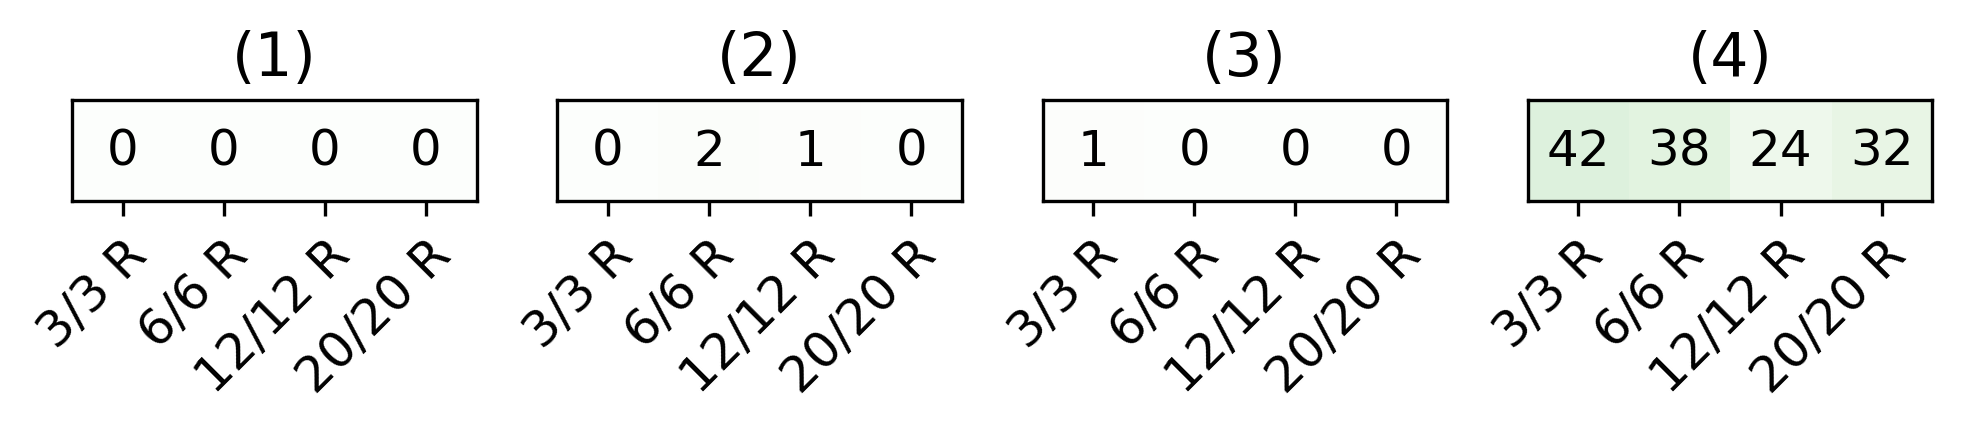

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
4105,YLL026W,7782,6824,5769,15638,5762,12947,11553,7721,8710,...,9044,14953,9460,6648,14532,10012,8658,5186,10382,11633


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
4105,YLL026W,4902,6442,8778,6301,5824,6513,3583,9178,8045,...,8981,4753,4432,5837,7484,4437,6357,8747,3817,6881


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
4105,YLL026W,6986.693811,-0.641283,7075.514403,True,4404.269569,True


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


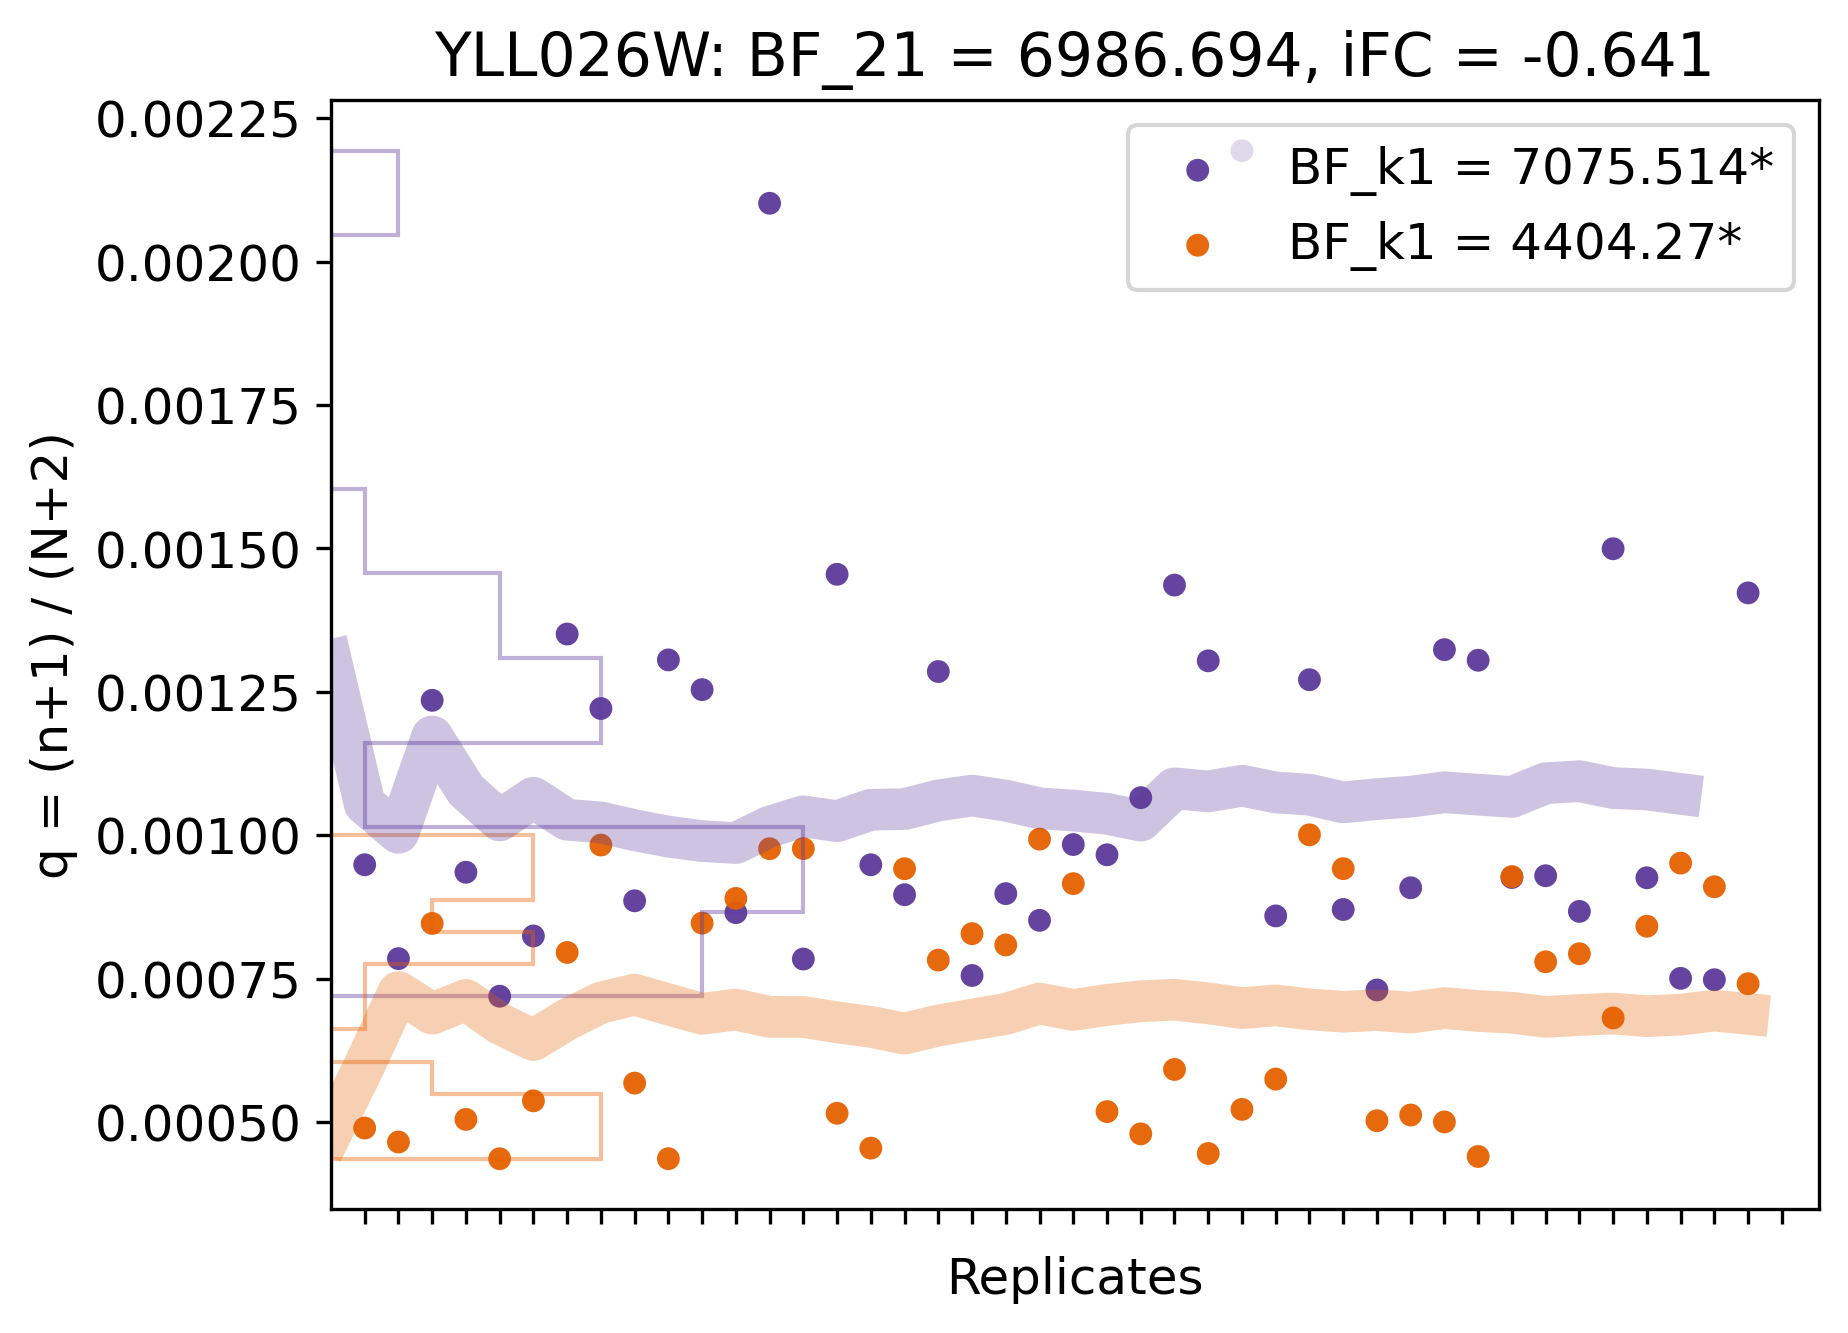

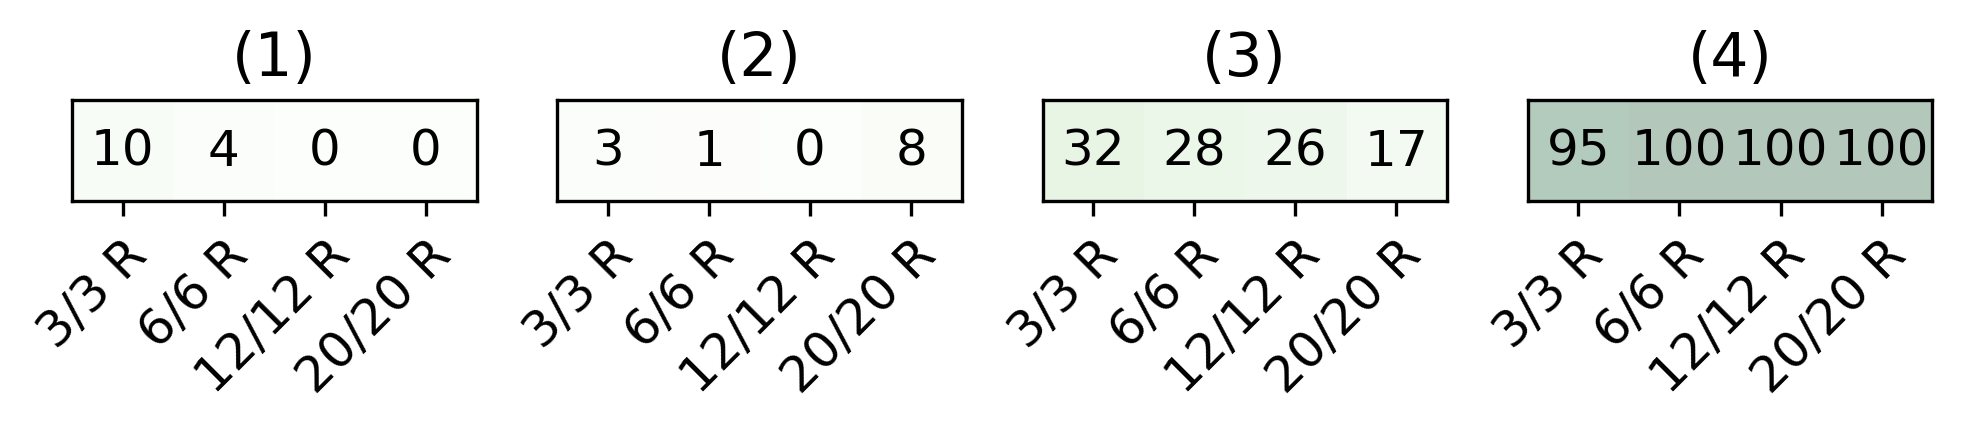

[None, None, None, None]

In [63]:
[stalk([gene]) for gene in ['LSR1', 'YLL039C', 'YJL098W', 'YLL026W']]

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
4868,YMR048W,125,178,146,217,178,257,136,217,178,...,136,249,209,152,131,158,216,122,265,153


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
4868,YMR048W,390,310,331,418,243,479,292,276,296,...,597,297,398,231,342,326,266,267,383,258


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
4868,YMR048W,329.411226,0.797614,-202.050367,False,-190.785337,False


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


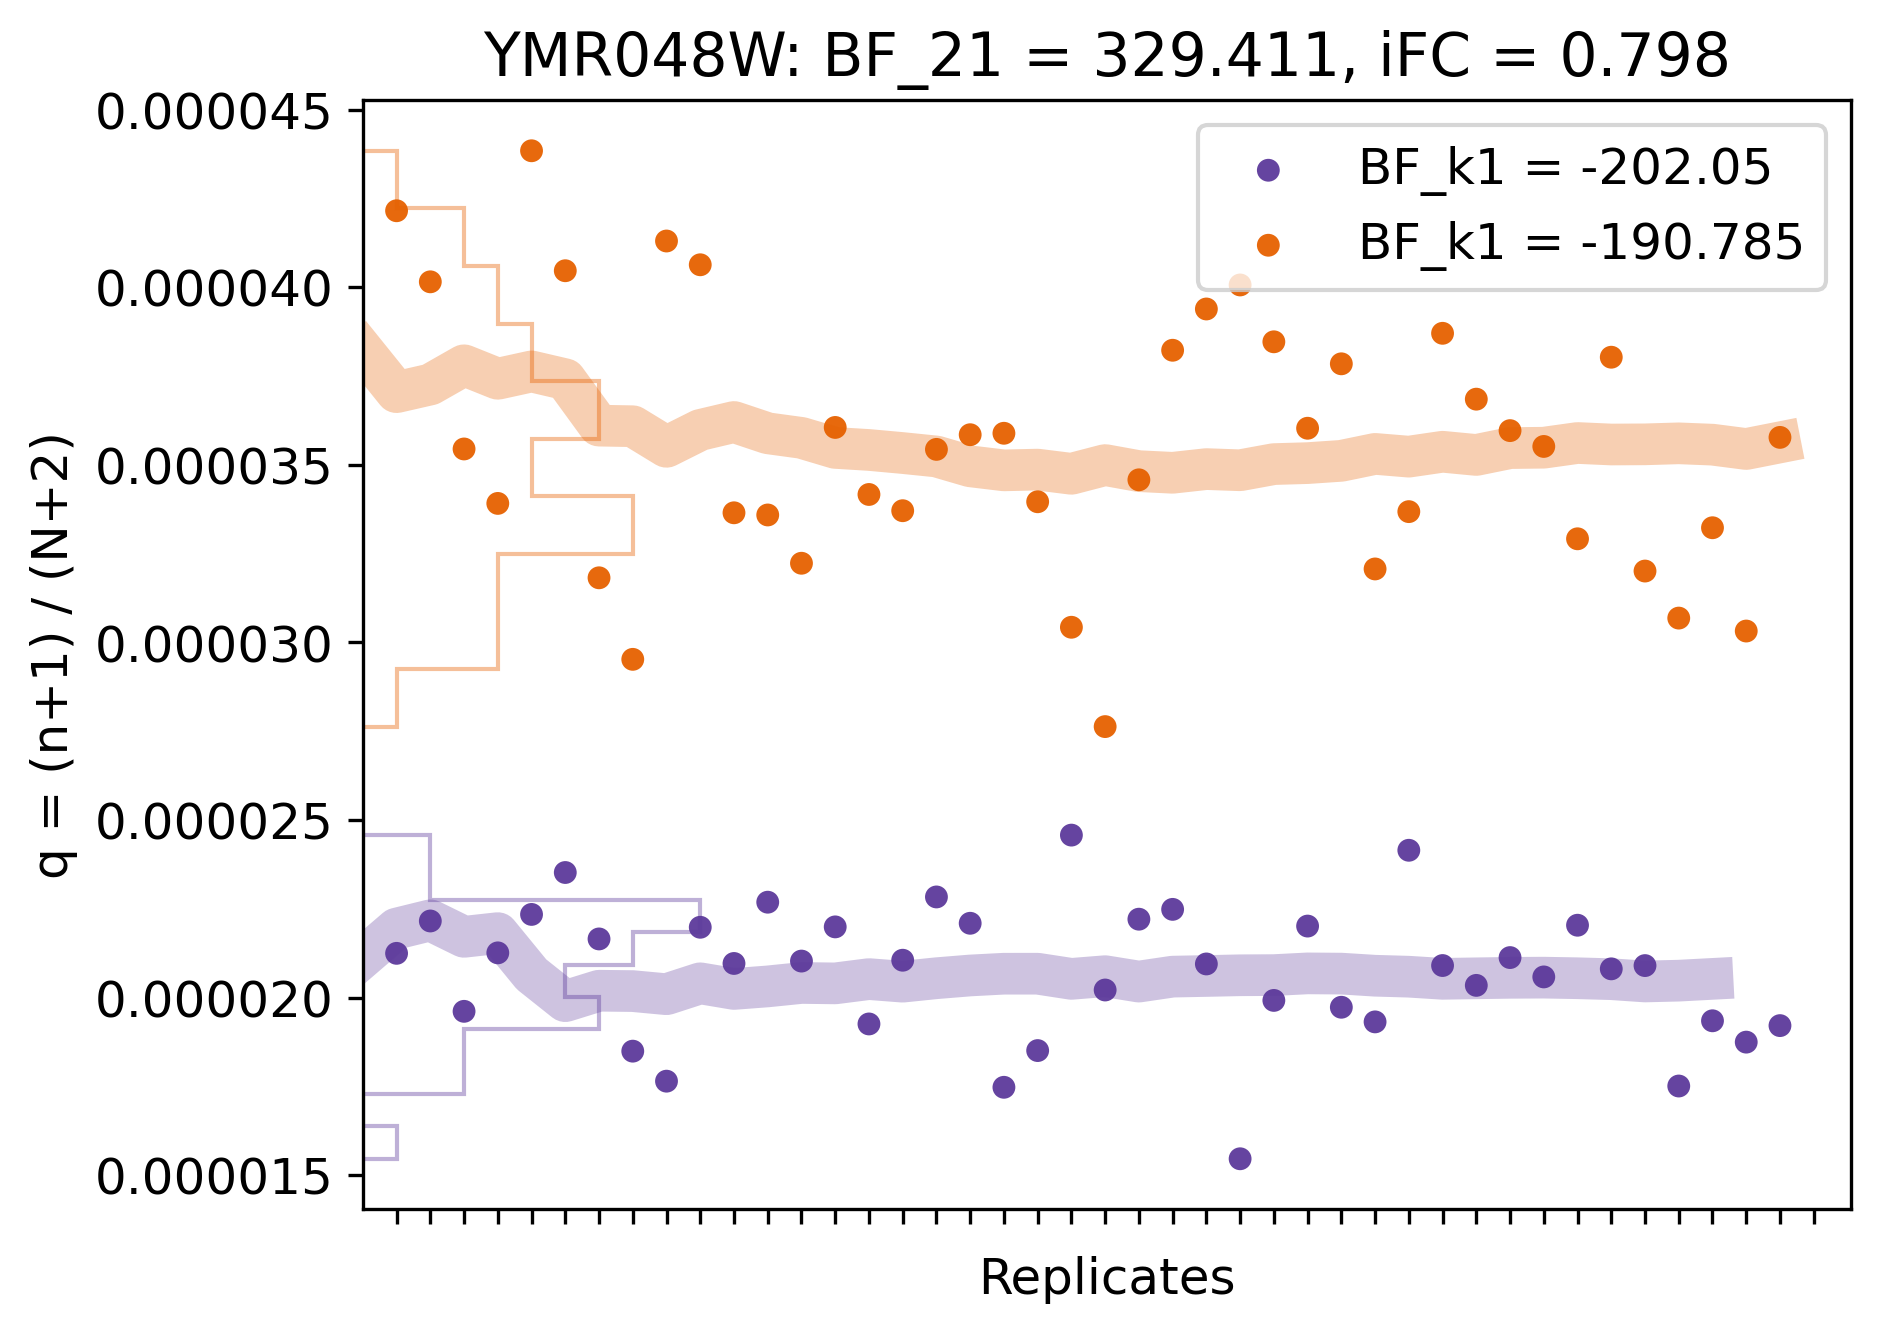

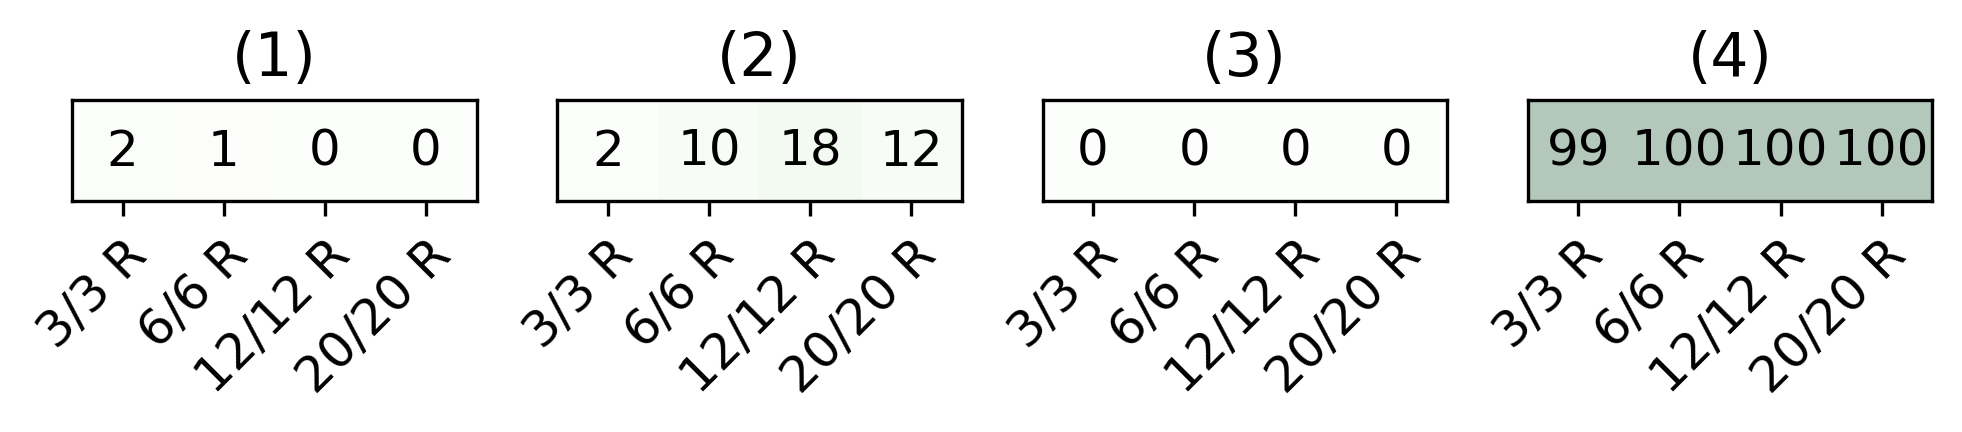

In [64]:
# the chosen one, Figure 1

stalk(['YMR048W'])

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
5422,YNL232W,388,697,459,658,779,1276,674,718,769,...,528,775,833,529,395,536,1068,385,1080,515


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
5422,YNL232W,841,622,644,855,573,983,688,772,635,...,1335,666,913,595,804,679,714,710,768,646


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
5422,YNL232W,7.1749,0.090803,-48.996454,False,-181.486812,False


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


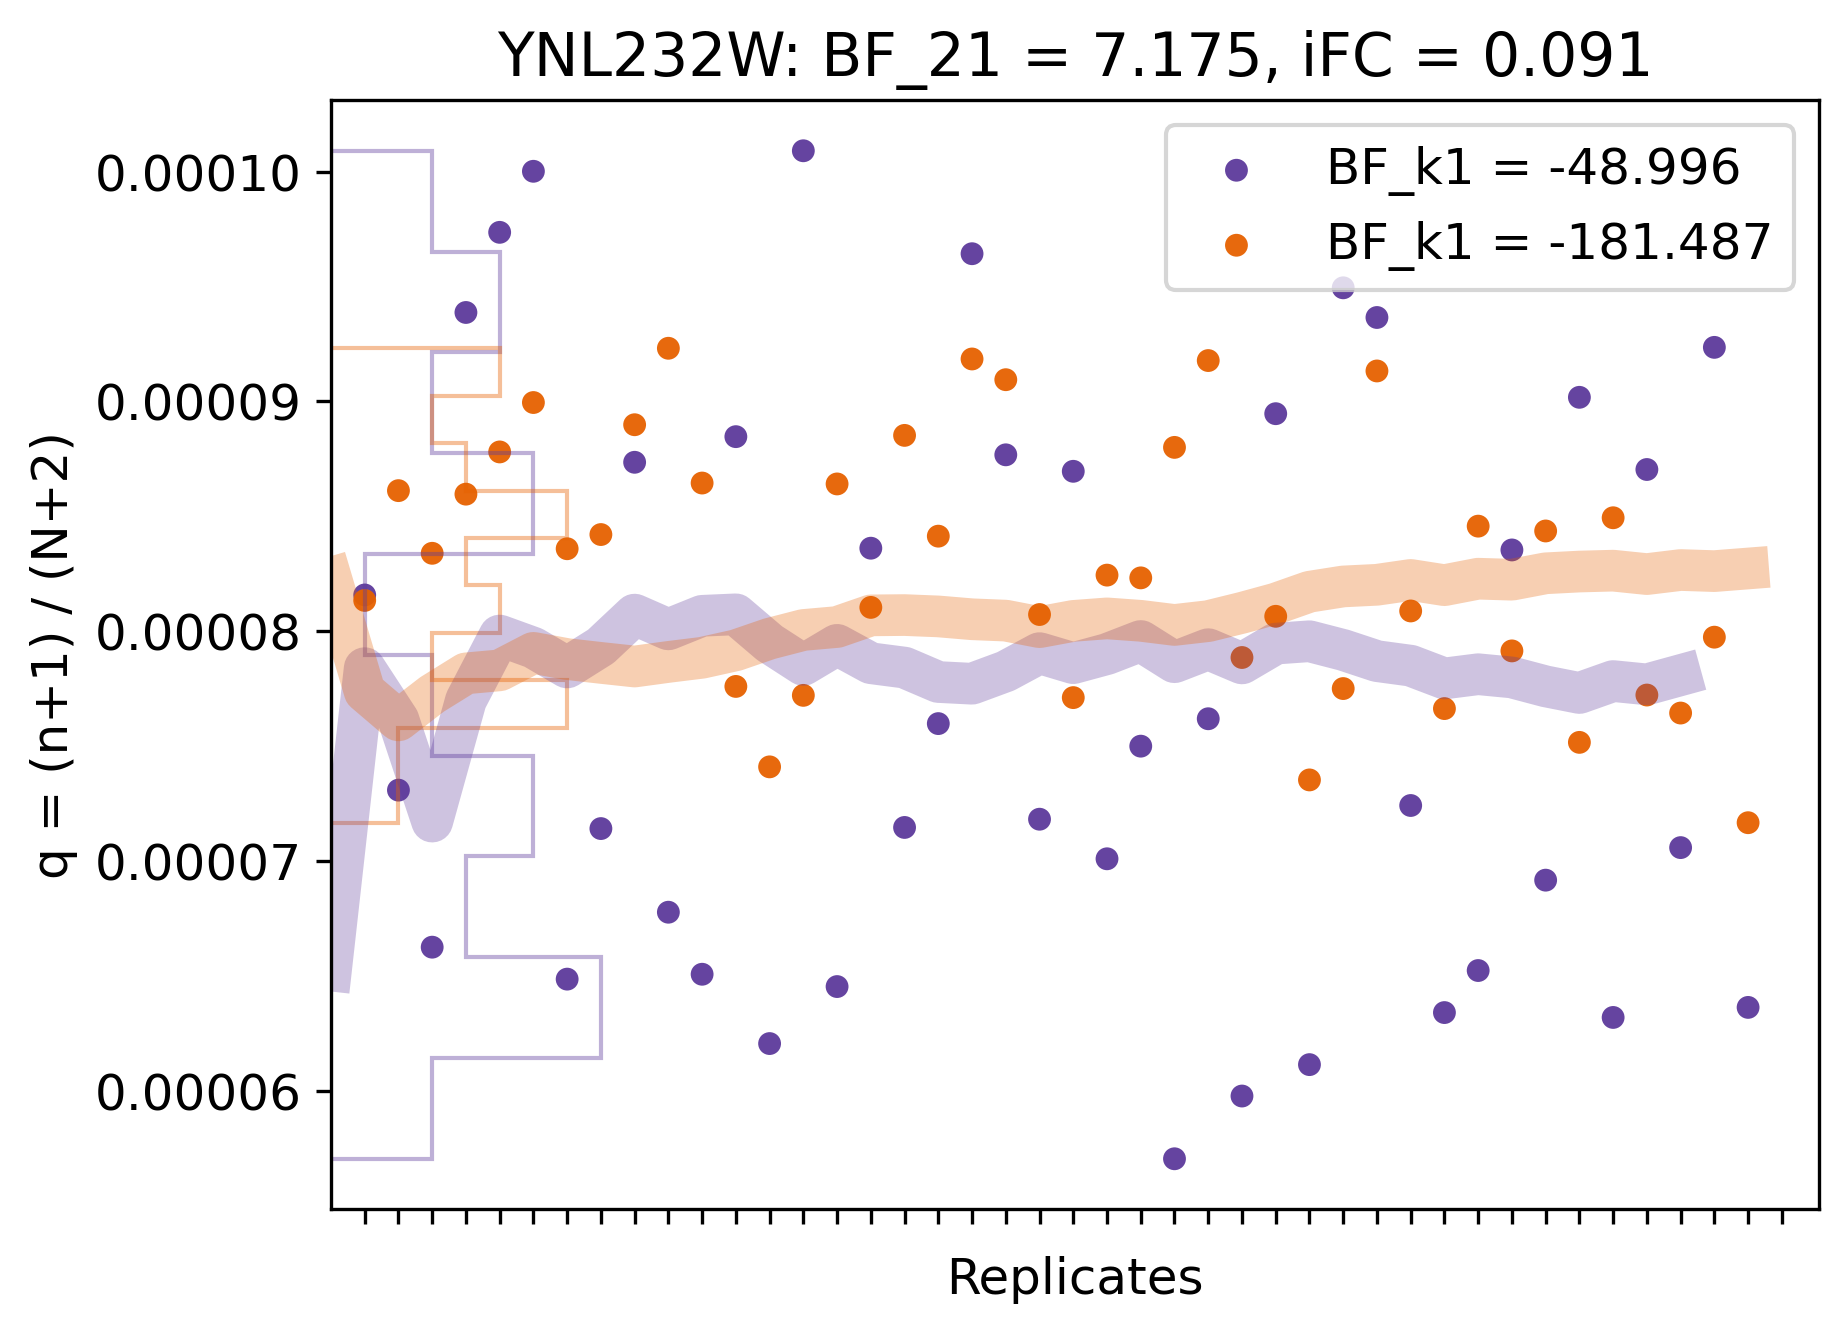

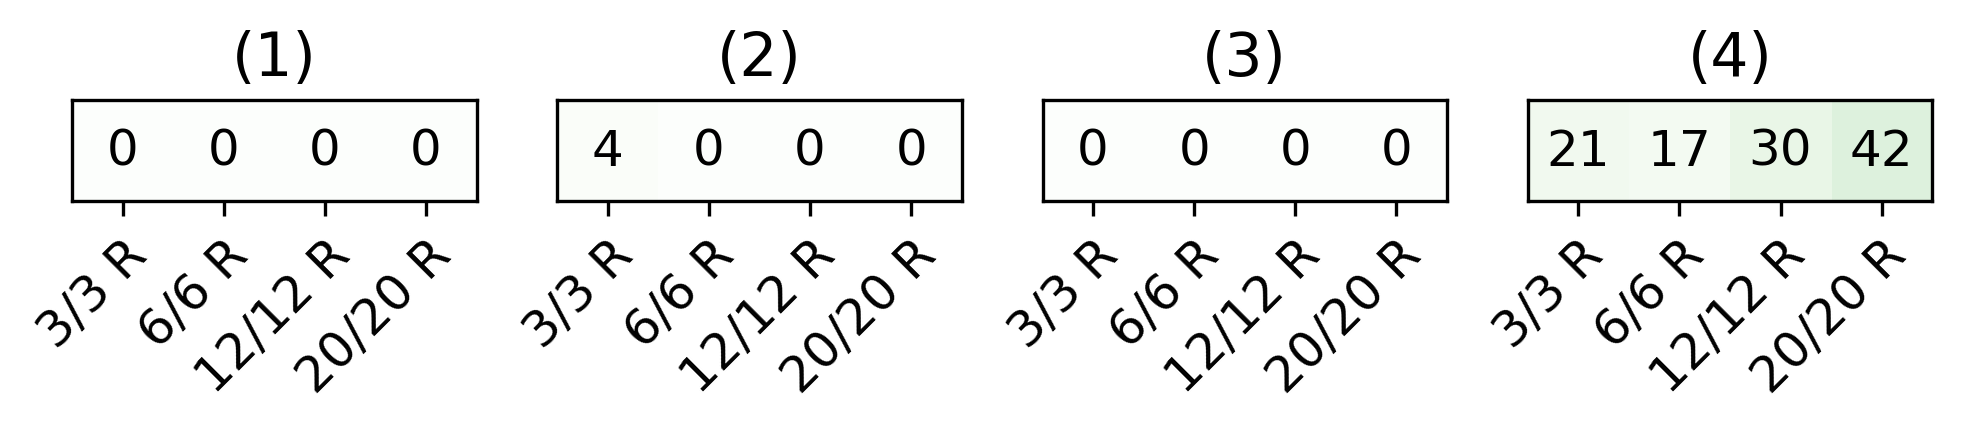

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
4511,YLR329W,30,49,62,88,64,104,48,34,53,...,29,85,56,43,52,27,71,44,86,51


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
4511,YLR329W,112,65,71,104,52,114,62,73,50,...,111,65,73,47,70,120,59,56,105,57


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
4511,YLR329W,7.20385,0.306775,-196.805858,False,-205.931345,False


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


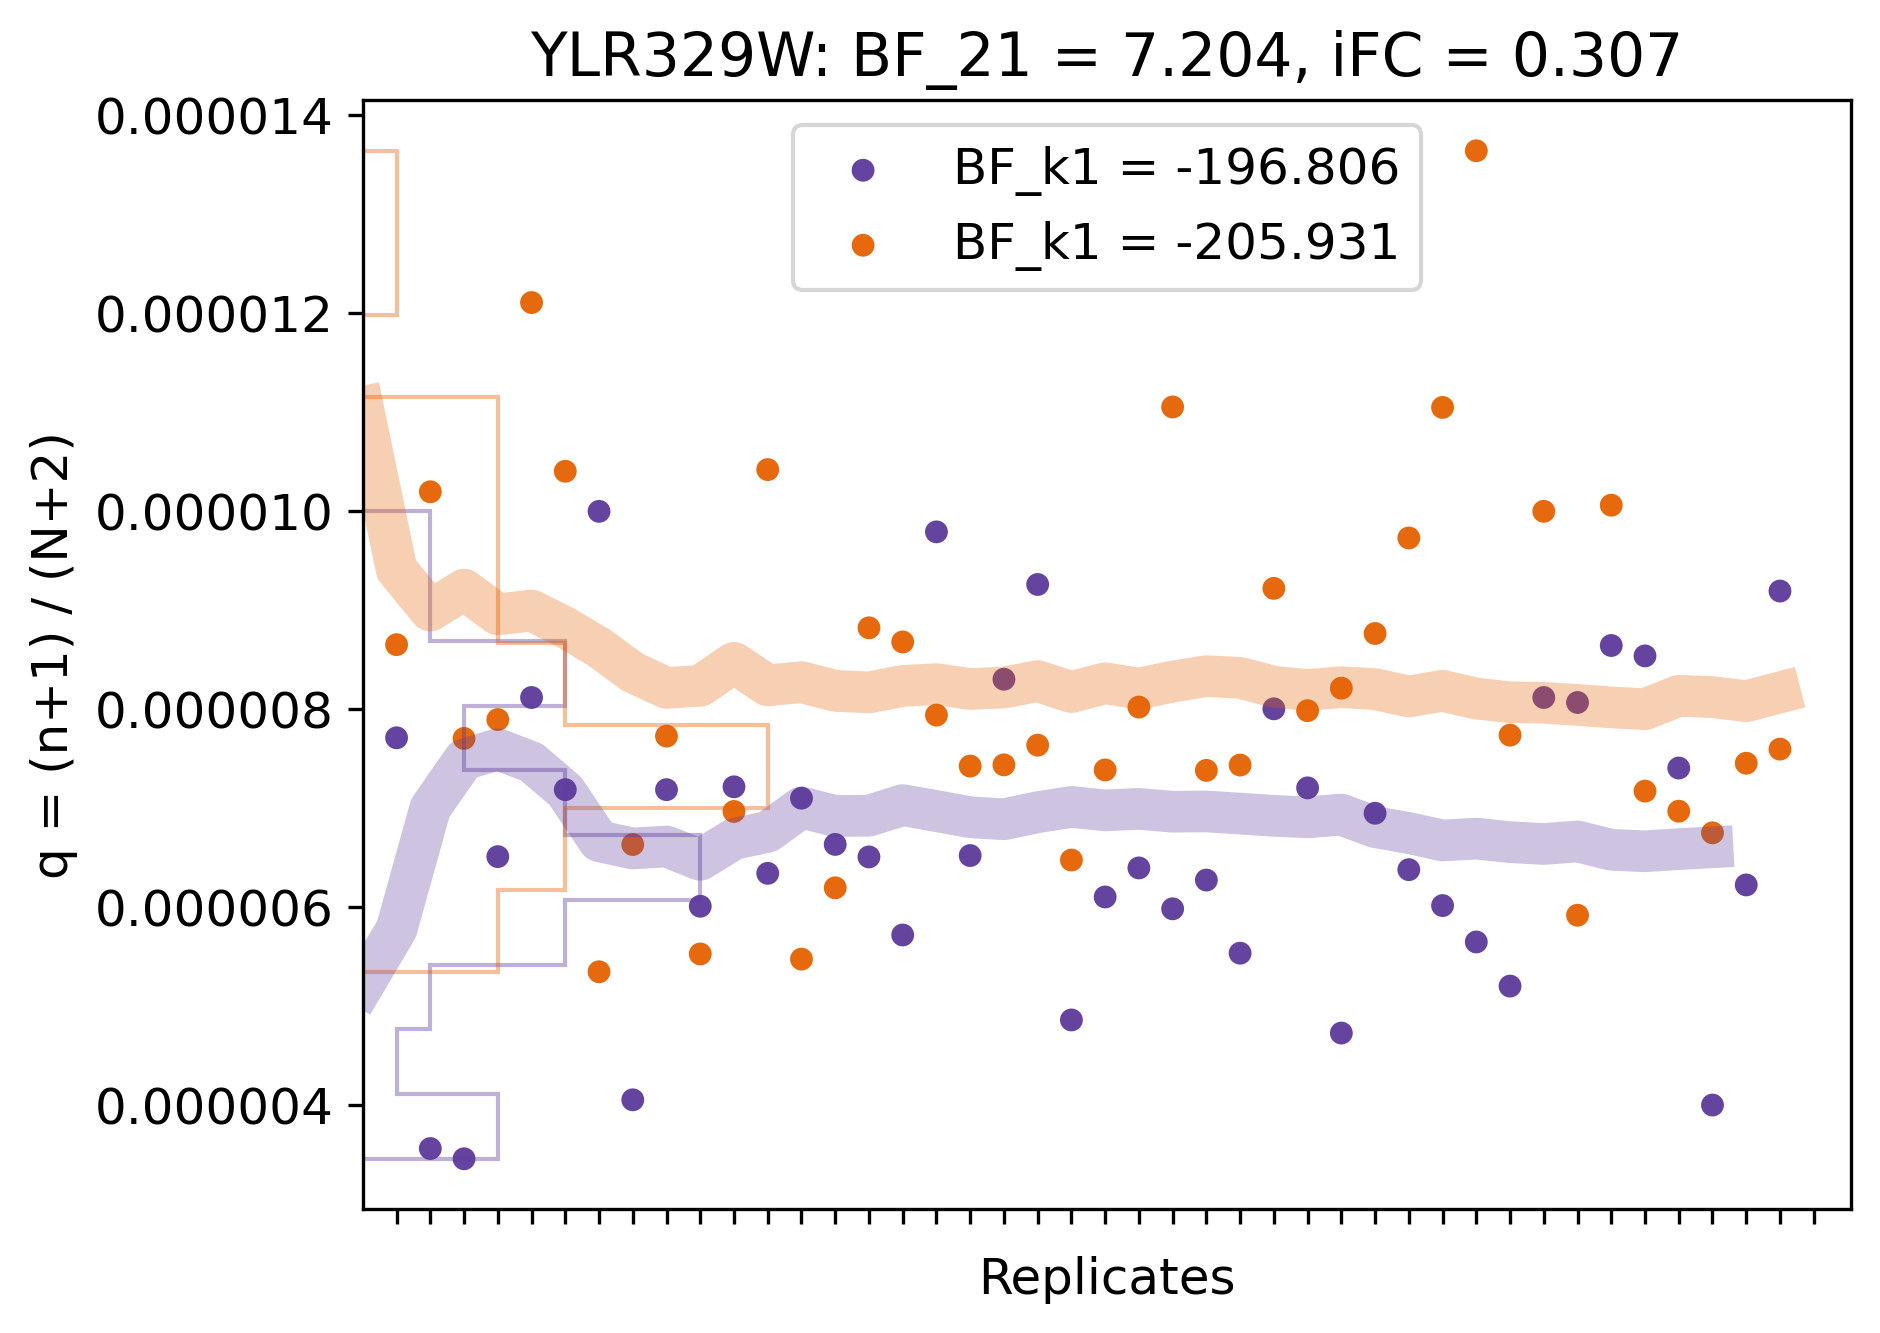

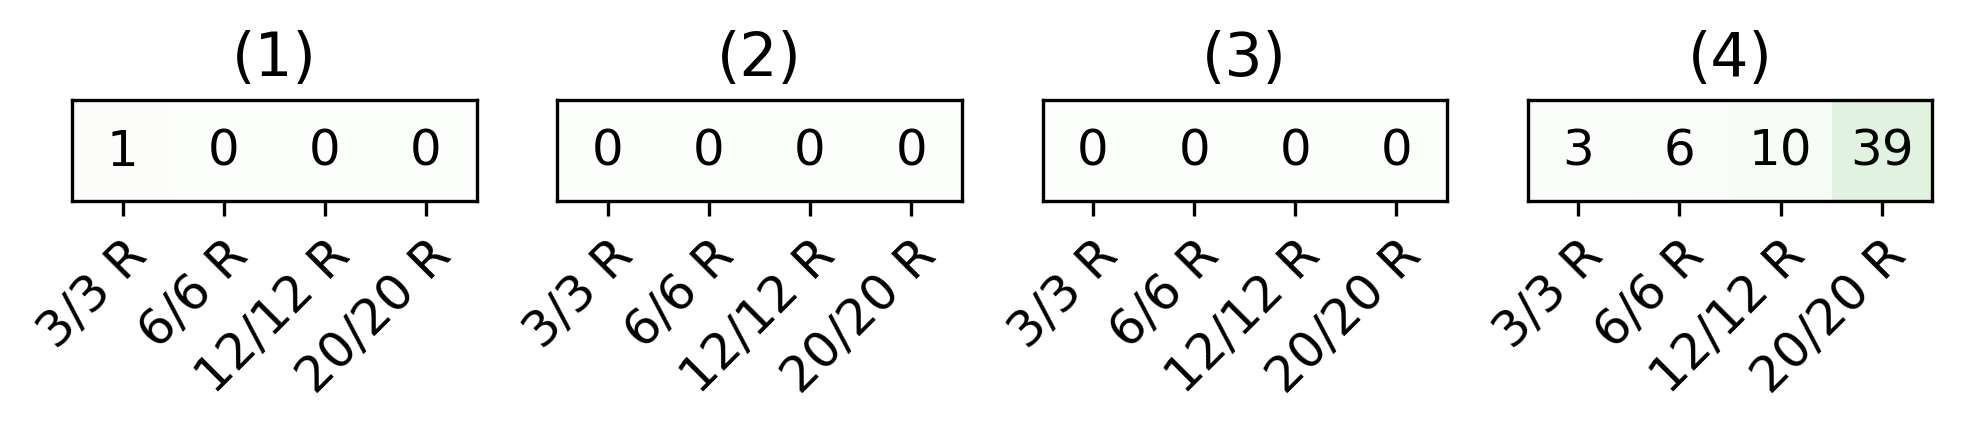

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
1409,YDR291W,268,443,315,477,451,956,473,409,458,...,337,586,516,380,261,323,603,288,659,359


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
1409,YDR291W,630,488,538,663,399,753,410,564,461,...,816,434,496,391,453,477,425,570,524,405


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
1409,YDR291W,7.219764,0.111894,-95.144699,False,-163.157529,False


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


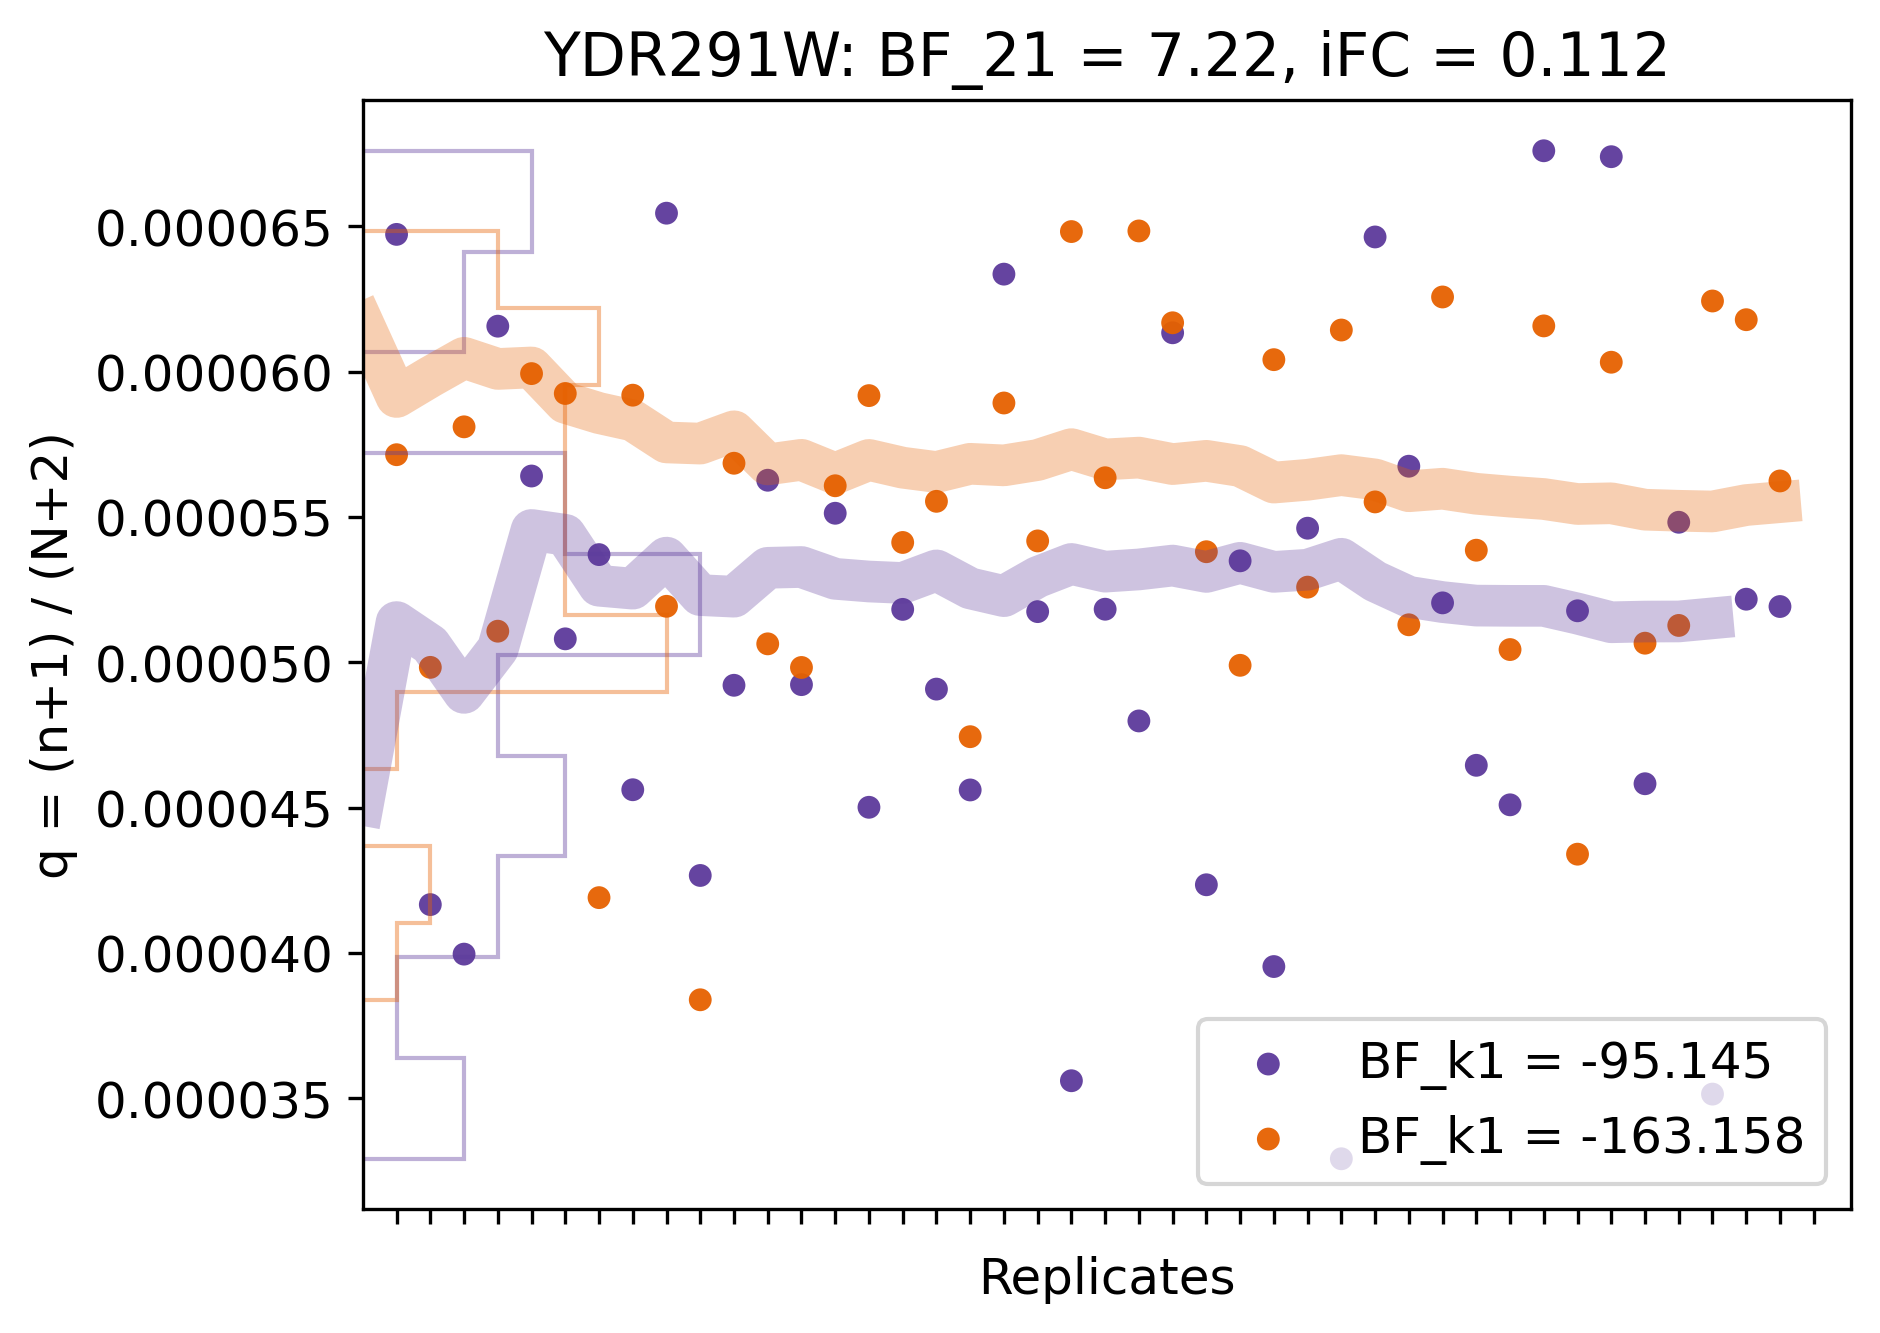

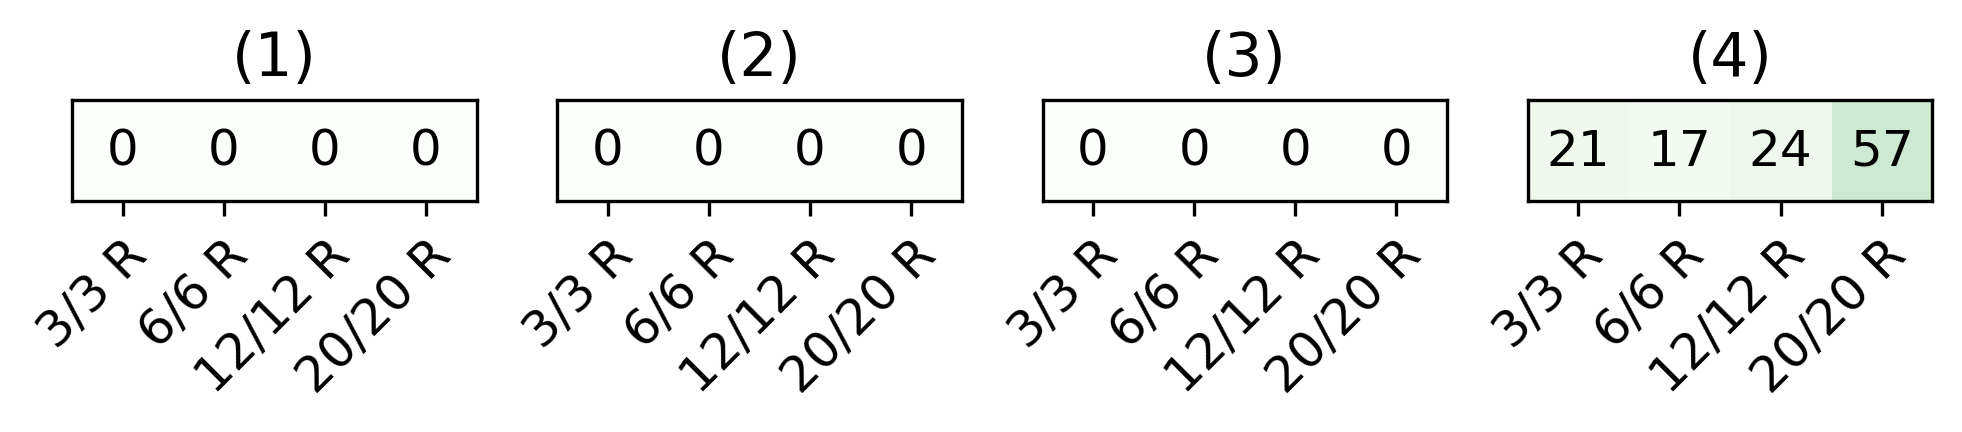

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
6701,YPR164W,247,418,292,425,408,879,456,432,388,...,340,552,482,383,270,328,621,267,613,363


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
6701,YPR164W,512,478,462,545,356,682,411,539,417,...,805,403,470,379,478,459,388,485,420,389


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
6701,YPR164W,7.242236,0.115596,-129.747251,False,-198.587507,False


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


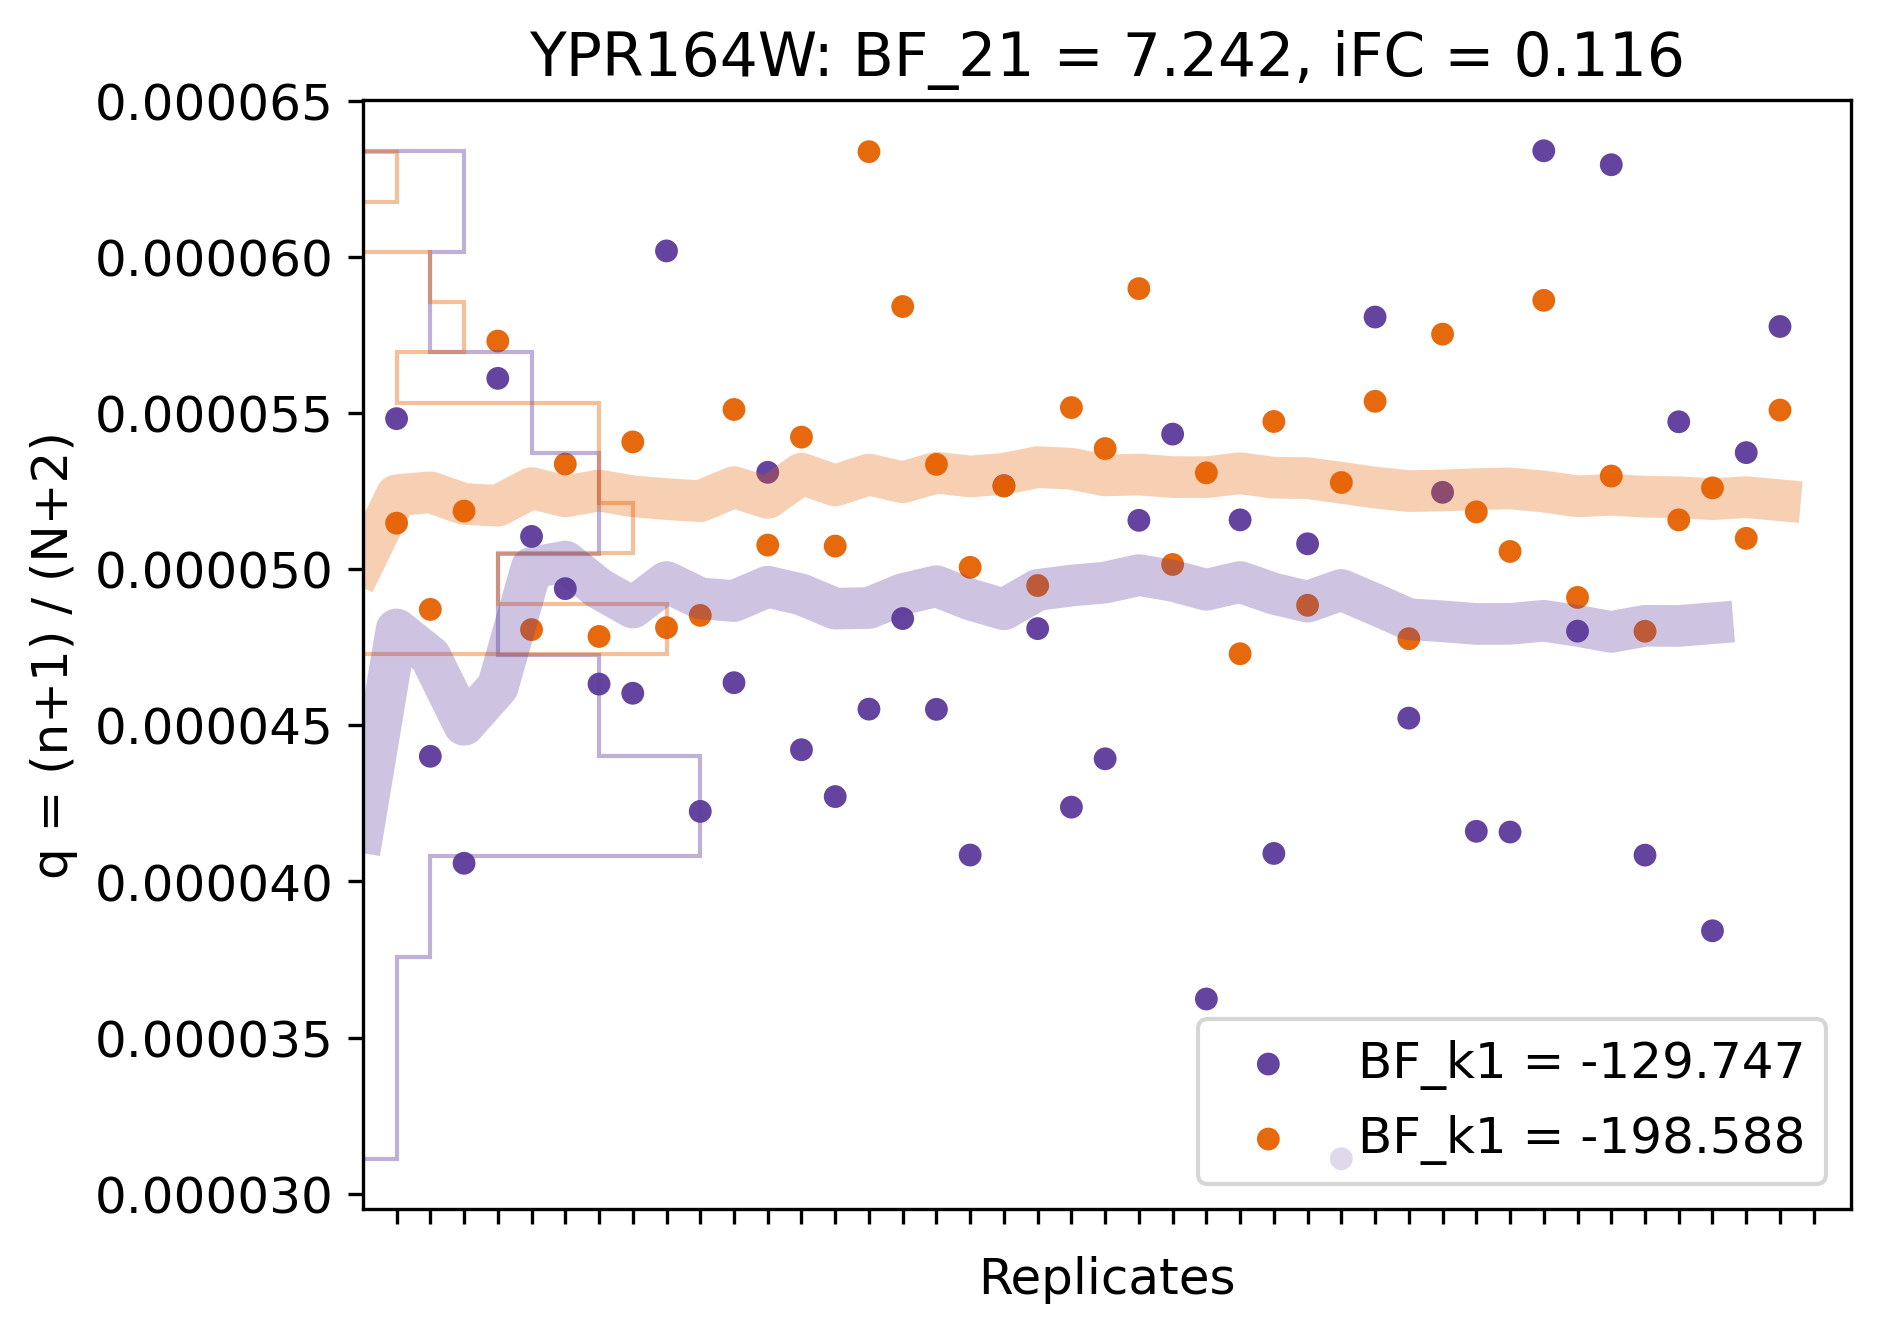

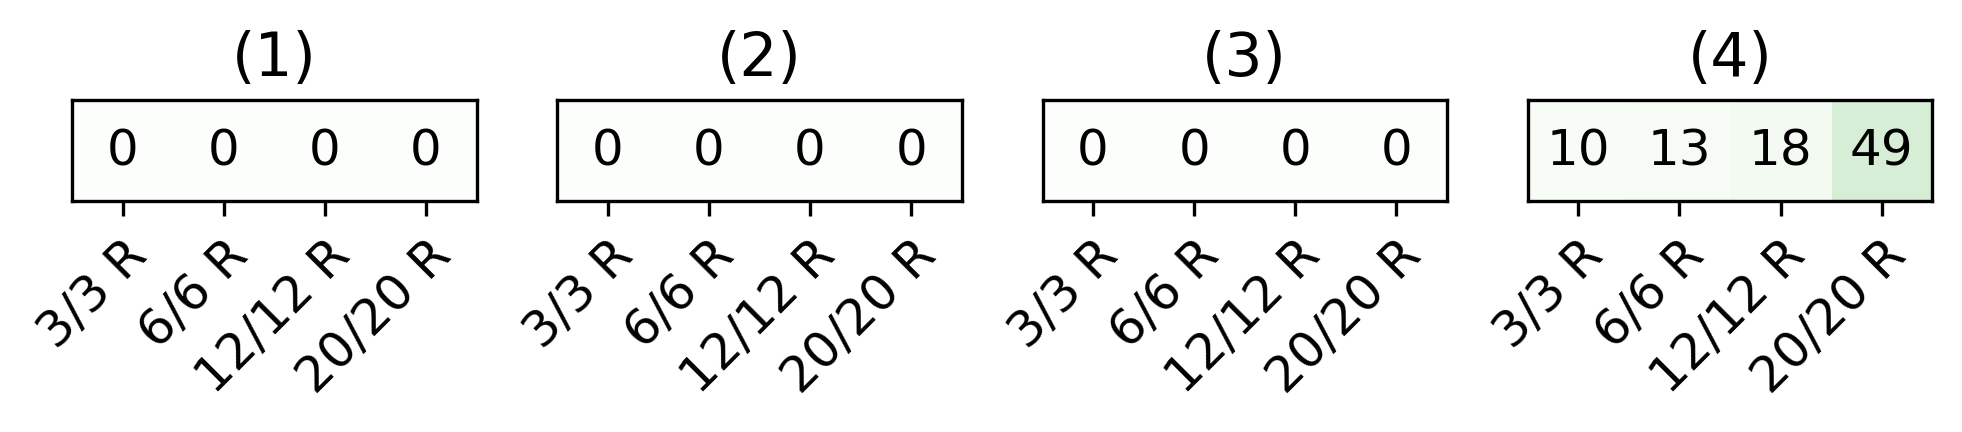

Read counts in WT across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
6459,YPL227C,278,544,401,549,554,1031,508,498,485,...,424,669,676,431,405,329,666,343,736,438


Read counts in Snf2 mutant across replicates:


,genes,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
6459,YPL227C,679,479,489,768,412,836,457,631,563,...,996,543,520,391,586,559,507,587,629,538


bayexpress results:


,locus_name,BF_21,FC,BF_k1_WT,CIG_WT,BF_k1_Snf2,CIG_Snf2
6459,YPL227C,7.247946,0.104776,-124.629656,False,-150.409227,False


With:
BF_21 ... Bayes factor for differential gene expression analysis
FC ... inferred log_2 fold change
BF_k1_WT ... Bayes factor for testing wether replicates are consistent with each other in wild-type
CIG_WT ... genes that have been identified to be All Over The Place in WT meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
BF_k1_Snf2 ... Bayes factor for testing wether replicates are consistent with each other in Snf2-mutant
CIG_Snf2 ... genes that have been identified to be All Over The Place in the mutant meaning it is part of the list of highy variable genes idenified in bootstrapping experiments. If CIG == True, the gene is marked*.
(1) = Bayes factors = BF_21 > 1, |FC| > 1; (2) = edgeR = significant p-value, |FC| > 1; (3) = DESeq2 = significant p-value, |FC| > 1; (4) = Bayes factors = BF_21 > 1


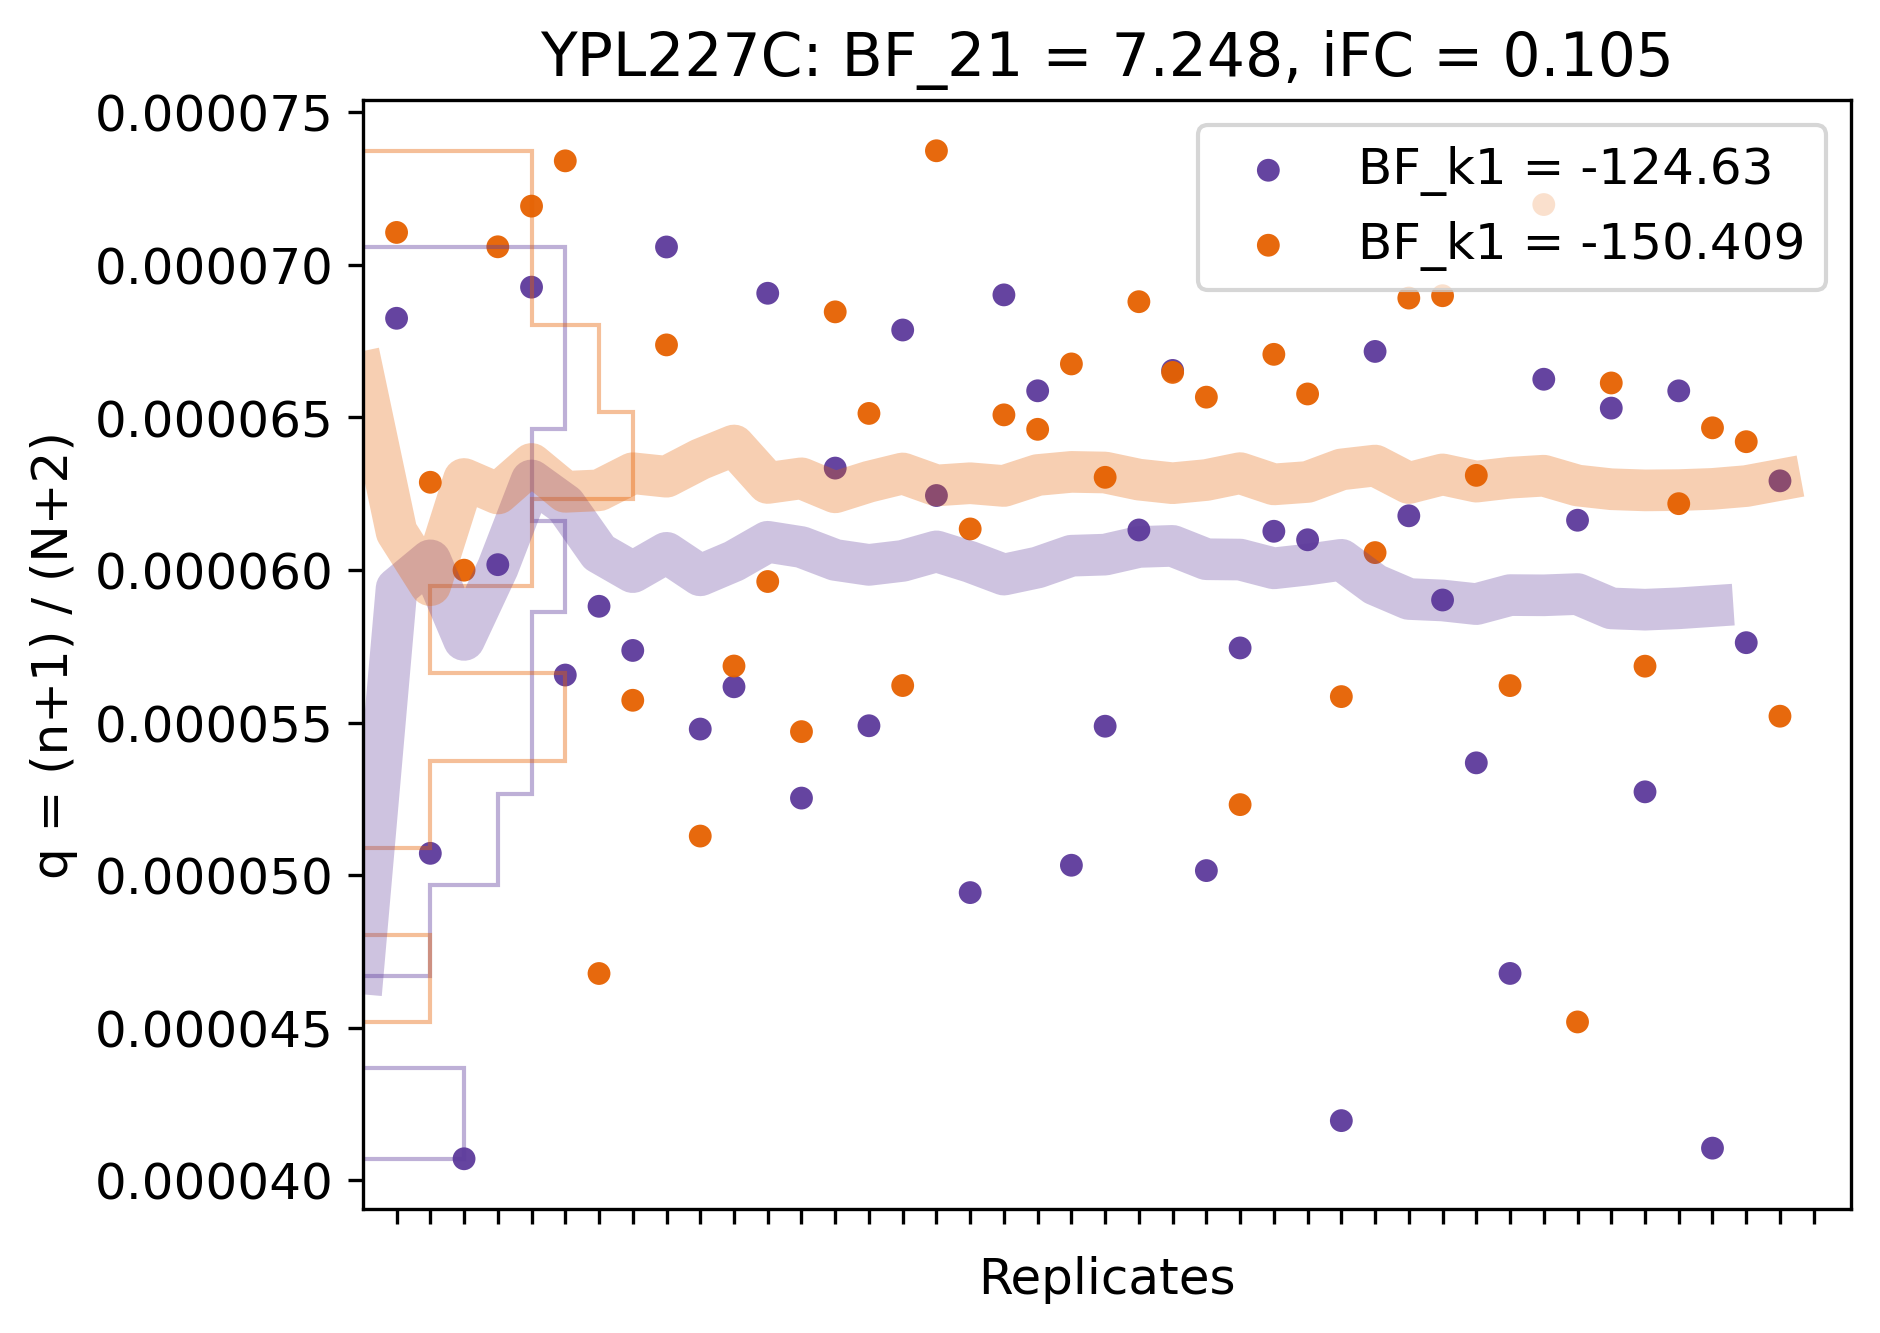

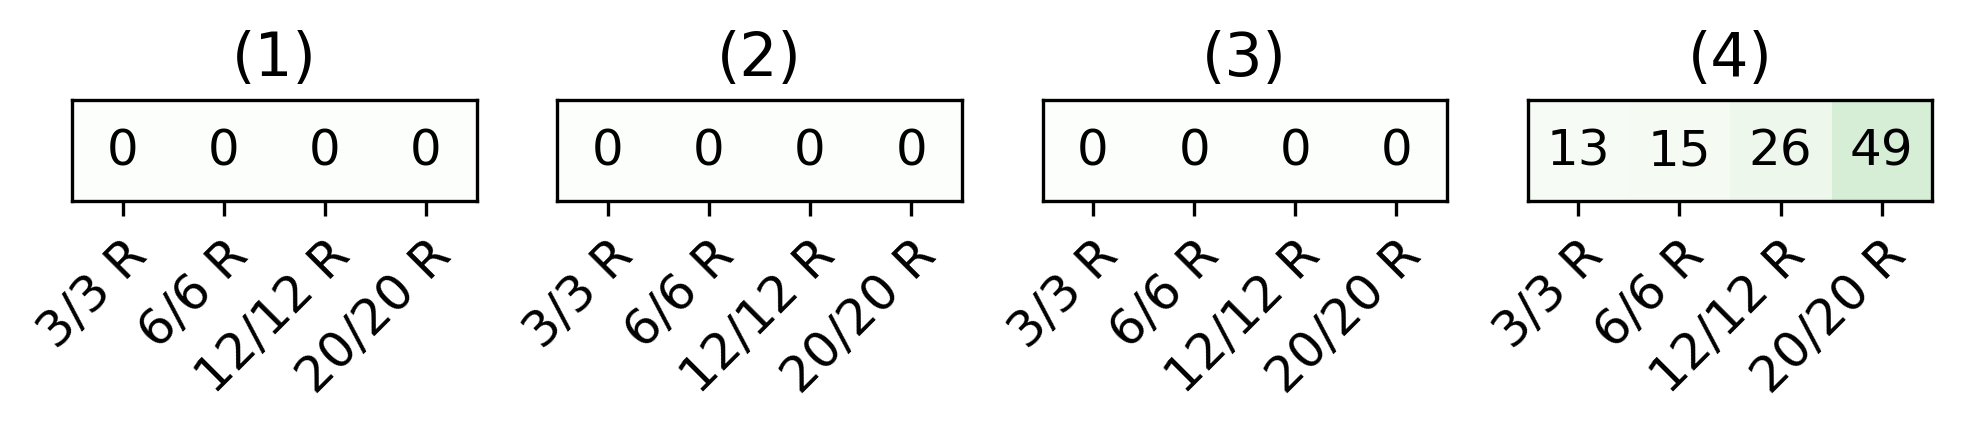

[None, None, None, None, None]

In [65]:
[stalk([gene]) for gene in ['YNL232W', 'YLR329W', 'YDR291W', 'YPR164W', 'YPL227C']
]